## Практическое домашнее задание 2. Градиентный спуск своими руками

### Общая информация

Дата выдачи: 16.10.2026

Мягкий дедлайн: 16.11.2026 23:59 MSK

Жесткий дедлайн: 23.11.2026 23:59 MSK


### Оценивание и штрафы

Каждая из задач имеет определенную «стоимость» (указана в скобках около задачи). **Максимально допустимая оценка за работу — 10 баллов.**

Задание выполняется самостоятельно. «Похожие» решения считаются плагиатом и все задействованные студенты (в том числе те, у кого списали) не могут получить за него больше 0 баллов (подробнее о плагиате см. на странице курса). Если вы нашли решение какого-то из заданий (или его часть) в открытом источнике, необходимо указать ссылку на этот источник (скорее всего вы будете не единственным, кто это нашел, поэтому чтобы исключить подозрение в плагиате, необходима ссылка на источник).

Неэффективная реализация кода может негативно отразиться на оценке. Также оценка может быть снижена за плохо читаемый код и плохо считываемые диаграммы.

Все ответы должны сопровождаться кодом или комментариями о том, как они были получены.

Для удобства проверки самостоятельно посчитайте свою максимальную оценку (исходя из набора решенных задач) и укажите ниже.

**Оценка**: 9


### О задании

В данном задании необходимо реализовать обучение линейной регрессии с помощью различных модификаций градиентного спуска. В файле `descents.py` вам нужно будет реализовать несколько классов для различных вариаций градиентного спуска, а именно:
* `VanillaGradientDescent`
* `StochasticGradientDescent`
* `SAGDescent`
* `MomentumDescent`
* `Adam`


В файле `linear_regression.py` вам необходимо будет реализовать класс `CustomLinearRegression` для обучения линейной регрессии (и, разумеется, предсказания целевой переменной на основе обученной модели).


### Про предложенную архитектуру

Предложенная вам архитектура шаблонов написана по принципам SOLID: основная ее идея в том, что вы сможете использовать различные лоссы и оптимизаторы с одним и тем же кодом прочих классов, никак не изменяя и не переписывая методы классов, которые с оптимизаторами и лоссом взаимодействуют. Мы добиваемся этого при помощи выделения интерфейсов (в Python мы достигаем этого при помощи абстрактных классов, см дальше в заданиях) и выделения зон ответственности каждого класса.

Глобально в нашей архитектуре всего 4 интерфейса (некоторые из которых на самом деле сразу concrete классы), каждый из которых порождает одно семейство:
- `interfaces.LossFunction`
  - Классы, имплементирующие этот интерфейс, отвечают за одну конкретную функцию потерь, используемую при обучении, и всё, что меняется вместе с ней при её замене: подсчёт лосса, подсчет градиента и аналитическое решение (если есть, то добавляется в интерфейс соответствующим mixin-ом).
- `interfaces.LinearRegressionInterface`
  - Интерфейс обертки для модели линейной регрессии, контейнер, содержащий составные части (лосс-функцию и оптимизатор) и использующий их для выполнения содержательной работы.
- `interfaces.LearningRateSchedule`
 - Простенькое семейство расписаний, определяющих шаг обучения для каждой итерации
- `interfaces.AbstractOptimizer`.
  -  Классы, имплементирующие этот интерфейс, имплементируют конкретный алгоритм оптимизации и всё, что происходит в его процессе. Пользуются обёрткой линейной регрессии для доступа к данным и вызова расчетов, чтобы не зависеть напрямую от конкретных функций потерь и шедулеров шага обучения.

Концепция передачи маленьких объектов, отвечающих за свою маленькую зону ответственности внутрь более сложного объекта для выполнения ими составных частей работы называется Dependency Injection, и работает как раз за счет выделения зоны ответственности и опоры на интерфейс вместо реализации.

Посмотрите на код `linear_regression.CustomLinearRegression`: она принимает в себя объекты с интерфейсами `LossFunction` и `AbstractOptimizer`, а в `descents.BaseDescent` как уточнении интерфейса абстрактного оптимизатора до итеративных оптимизаторов видно, что он в свою очередь принимает при инициализации объект шедулера шага обучения.

Благодаря этому, код, который использует эти классы, может по очереди:
- Инициализировать нужный шедулер с нужными параметрами для задания шага обучения
- Иницализировать оптимизатор, задав ему нужные параметры процесса и передав готовый шедулер
- Инициализировать класс линейной регрессии нужной под задачу функцией потерь и уже готовым оптимизатором.
- Запустить процесс обучения

И на любом этапе можно использовать другой объект с подходящим интерфейсом, и всё будет работать!


**В ходе выполнения этой домашки вы наполните все эти семейства классов различными имплементациями и будете менять их на ходу как перчатки!**

Более подробно про наследование классов в Python можно прочитать здесь:
* Наследование: https://docs.python.org/3/tutorial/classes.html#inheritance
* Абстрактные классы: https://docs.python.org/3/library/abc.html



## Задание 1. Линейная регрессия  (1 балл)

### Градиент функции потерь MSE

### Задание 1.0. Градиент MSE в матричном виде (0.3 балла).

Напомним, что функция потерь MSE записывается как:

$$
    Q(w) = \frac{1}{\ell} \sum \limits_{i = 1}^\ell (y_i - \langle x_i, w \rangle)^2 = \frac{1}{\ell} \| X w - y \|^2
$$

где $\ell$ – количество объектов в выборке, $X \in \mathbb{R}^{\ell \times d}$ – матрица "объект-признак", а $y \in \mathbb{R}^\ell$ – целевая переменная. Через $x_i$ обозначается $i$-ая строчка матрицы $X$, отвечающая за $i$-й объект выборки.

- **Выпишите ниже градиент для функции потерь MSE в матричном виде.**

**Решение:**

$grad  [Q(w)] = \frac{2}{\ell} X^T (Xw - y)$


- **Имплементируйте методы `MSELoss.loss`, `MSELoss.gradient`**





### Задание 1.1 Аналитическое решение и `CustomLinearRegression` (0.7 балла)

Перед тем, как мы углубимся в итеративные методы оптимизации, давайте вспомним, что для ряда функций потерь существует и аналитическое решение. Давайте сперва вспомним, как оно выглядит для MSE.

- **Выведите формулу оптимальных $w$ в задаче минимизации MSE, и запишите её ниже.**

- **Имплементируйте подсчет этого решения в `MSELoss._plain_analytic_solution`**

$$\text{MSE} = \| X w - y \|^2$$
$$
w = (X^T X)^{-1} X^T y
$$

**Вопрос**: Как мы помним, у аналитического решения есть минусы - какие?

**Ответ**: `чисто теоретические: проблемы с обращением матрицы, не любая матрица может быть обращена (в общем случае используется псевдо-обратная матрица)
правктические: при обращении возможна большая ошибка (например, если использовать метод Крамера, то малый определитель матрицы может дать в обращение большие числа из-за деления на него)`

Теперь прокинем это решение в наш класс линейной регрессии, чтобы получше разобраться в архитектуре.


- **Допишите класс `descents.AnalyticSolutionOptimizer`**
- **Допишите класс `CustomLinearRegression`**
  - В нем на текущем этапе нужно имплементировать все методы: `fit` и `predict` вам понадобятся прямо сейчас, а `compute_gradients` и `compute_loss` в следующей части.

Помните, про разделение ответственности классов!

За контроль процесса обучения отвечает оптимизатор, а объект линейной регрессии по факту выступает точкой входа, контейнером для данных и способом доступа к вычислениям, на основе которых оптимизатор принимает решения (e.g. значение антиградиента в точке весов).

При этом сам по себе оптимизатор должен быть универсален, в нем никак не должны содержаться детали, связанные с конкретными функциями потерь, все необходимое от них он может получить через `self.model`.

Аналогично, класс линейной регрессии тоже должен быть универсальным и готовым к работе с любыми лоссами и оптимизаторами, исполняющими заявленный интерфейс. Здесь применена dependency injection, и вы должны грммотно ее поддержать в своей имплементации. Аналогично, все, что вам может быть нужно от функций потерь, вы можете получить при помощи обращения к переданному объекту.

In [69]:
import numpy as np
from linear_regression import MSELoss, CustomLinearRegression, AnalyticSolutionOptimizer

num_objects = 100
dimension = 5

x = np.random.rand(num_objects, dimension)
y = np.random.rand(num_objects)

In [70]:
from sklearn.metrics import mean_squared_error as mse
import sklearn

sklearn_linreg = sklearn.linear_model.LinearRegression(fit_intercept=False)
sklearn_linreg.fit(x, y)
print("Sklearn MSE", mse(sklearn_linreg.predict(x), y))

your_linreg = CustomLinearRegression(AnalyticSolutionOptimizer(), loss_function=MSELoss())
your_linreg.fit(x, y)
print("Your MSE", mse(your_linreg.predict(x), y))

assert abs(mse(your_linreg.predict(x), y) - mse(sklearn_linreg.predict(x), y)) < 1e-12, "Не повезло, попробуйте еще раз"

Sklearn MSE 0.10773899160672228
Your MSE 0.10773899160672228


Давайте сделаем задание немного прикольнее и изменим одну из колонок. Как мы знаем, полная мультиколлинеарность запрещает нам пользоваться аналитическим решением, но `sklearn` по какой-то причине это обходит, хмм

In [71]:
x[:, 3] = x[:, 2] + x[:, 4]

In [72]:
sklearn_linreg = sklearn.linear_model.LinearRegression(fit_intercept=False)
sklearn_linreg.fit(x, y)
print("Sklearn MSE", mse(sklearn_linreg.predict(x), y))

your_linreg = CustomLinearRegression(AnalyticSolutionOptimizer(), loss_function=MSELoss())
your_linreg.fit(x, y)
print("Your MSE", mse(your_linreg.predict(x), y))

Sklearn MSE 0.11198159720144131
Your MSE 0.11348613183054557


Ваша задача - понять, как можно сделать так, чтобы аналитическое решение работало всегда, вне зависимости от матрицы X. Как оказывается, это можно сделать, если воспользоваться SVD разложением. Для имплементации воспользуйтесь `scipy.sparse.linalg.svds`.

- Выведите через SVD формулу оптимальных $w$ в задаче минимизации MSE.

- Имплементируйте подсчет этого решения в `MSELoss._svd_analytic_solution`
    - Мир итерационных агоритмов причудлив. Если вы посмотрите на опции солверов svds, то увидите, что возможности вычислить точно все сингулярные числа вам не дают (propack рандомизированный и даст вам неточные ответы). Используйте стандартный солвер, выставьте максимальную доступную точность.

- Ответьте на **вопрос на засыпку**. Вообще говоря, в ряде случаев (например в нашем), даже такая неабсолютная на первый взгляд точность все равно позволяет получить точное решение задачи. Обоснуйте, почему? Как называется такой вид SVD? Какого минимального числа сингулярных чисел с вероятностью 1 будет достаточно в нашем случае для получения точного решения? Обоснуйте, почему.


$$\text{X} = \underset{n\times m}{\mathrm{U}} \ \underset{m\times m}{\mathrm{\Sigma}} \ \underset{m\times k}{\mathrm{V^T}}$$
$$w = X^+y = V\Sigma^+U^Ty$$

**Ответ**: Для решения нужны только ненулевые сингулярные числа и соответствующие им сингулярные векторы. Разложение, в котором оставляют только их усеченным SVD. В данном примере матрица имеет пять столбцов, но один из них задан как сумма двух других. Поэтому её ранг не превосходит 4, остальные четыре случайных столбца линейно независимы с вероятностью 1. Поэтому достаточно четырёх ненулевых сингулярных чисел и их векторов, чтобы восстановить псевдообратную матрицу и получить решение.

In [73]:
sklearn_linreg = sklearn.linear_model.LinearRegression(fit_intercept=False)
sklearn_linreg.fit(x, y)
print("Sklearn MSE", mse(sklearn_linreg.predict(x), y))
your_linreg =  CustomLinearRegression(AnalyticSolutionOptimizer(), loss_function=MSELoss(analytic_solution_func=MSELoss._svd_analytic_solution))
your_linreg.fit(x, y)

print("Your MSE", mse(your_linreg.predict(x), y))

assert abs(mse(your_linreg.predict(x), y) - mse(sklearn_linreg.predict(x), y)) < 1e-12, "Не повезло, попробуйте еще раз"

Sklearn MSE 0.11198159720144131
Your MSE 0.11198159720144134


## Задание 2. Реализация градиентного спуска (4 балла)

В этом задании вам предстоит написать собственные реализации различных подходов к градиентному спуску с опорой на подготовленные шаблоны в файле `descents.py`. При помощи них мы будем искать итеративные решения, подавая оптимизаторы внутрь нашей `CustomLinearRegression`.

### Напоминание про градиентный спуск

Основное свойство антиградиента &ndash; он указывает в сторону *наискорейшего* убывания функции в данной точке. Соответственно, будет логично стартовать из некоторой точки, сдвинуться в сторону антиградиента,
пересчитать антиградиент и снова сдвинуться в его сторону и т.д. Запишем это более формально.

Пусть $w_0$ &ndash; начальный набор параметров (например, нулевой или сгенерированный из некоторого
случайного распределения). Тогда ванильный градиентный спуск состоит в повторении следующих шагов до сходимости:

$$
    w_{k + 1} = w_{k} - \eta_{k} \nabla_{w} Q(w_{k}).
$$

Здесь $\eta_{k}$ обозначает длину шага на $k$-ой итерации (learning rate), а $Q(w)$ - функцию потерь (loss function).

Градиент для MSE вы уже нашли выше

### Задание 2.0. Learning Rate Schedules (0.2 балла)

Обратите внимание на **абстрактный** класс `LearningRateSchedule` в файле `descents.py`. С помощью его имплементаций мы на каждой итерации градиентного спуска будем получать соответствующий `learning_rate` $\eta_k$.

В файле уже реализован класс `ConstantLR`, который на каждой итерации возвращает один и тот же заранее заданный шаг. **Ваша задача в этом пункте – реализовать `TimeDecayLR`**, который мы будем использовать для обучения линейной регрессии. Формула очередного шага должна выглядеть следующим образом:
$$
    \eta_{k} = \lambda \left(\dfrac{s_0}{s_0 + k}\right)^p
$$

На практике достаточно настроить параметр $\lambda$, а остальным выставить параметры по умолчанию: $s_0 = 1, \, p = 0.5.$

### Задание 2.1. Родительский класс BaseDescent (1 балл).


Внимательно изучите устройство класса `BaseDescent`. У него есть один непомеченный абстрактным метод, который ему как частичному наследнику абстрактного класса нужно имплементировать - это `optimize`. В
этом методе необходимо имплементировать основной цикл обучения, и далее его будут переиспользовать все его наследники.

- **Допишите метод `BaseDescent.optimize`**


Для этого и всех дальнейших заданий необходимо соблюдать следующие условия:

* **Все вычисления должны быть векторизованы;**
* Циклы средствами python допускаются только для итераций градиентного спуска;
* В качестве критерия останова необходимо использовать (одновременно):
    * Квадрат евклидовой нормы разности весов на двух соседних итерациях меньше `tolerance`;
    * Разность весов содержит наны;
    * Достижение максимального числа итераций `max_iter`.
* Будем считать, что все данные, которые поступают на вход имеют столбец единичек последним столбцом;
* Веса модели надо обновлять внутри функции `_update_weights`, она неспроста так называется
* Чтобы проследить за сходимостью оптимизационного процесса будем использовать `CustomLinearRegression.loss_history`, в нём будем хранить *значения функции потерь до каждого шага, начиная с нулевого* (до первого шага по антиградиенту) и *значение функции потерь после оптимизации*.


Обратите внимание, что метод `_update_weights` всё ещё является абстрактным - его все ещё должны будут имплементировать дальнейшие наследники; фактически, только способом обновления весов они и отличаются. Она должна должна обновлять веса модели `self.model.w`, а также возвращать величину обновления $w_{k + 1} - w_k$.

Также обратите внимание на атрибут `self.iteration`, отвечающий за номер итерации алгоритма спуска. Как раз с помощью него (и `self.lr_schedule`) мы и будем получать `learning_rate` на соответствующей итерации алгоритма.

**Обратите внимание**


Все реализуемые вами классы спуска в задании - это *универсальные* оптимизаторы. Они не должны считать градиенты конкретной функции потерь внутри себя.

Для вычисления градиента они всегда обращаются к модели, с которой работают:

```
gradient = self.model.compute_gradients(X_batch, y_batch)
```

### Задание 2.2. Полный градиентный спуск VanillaGradientDescent (0.6 балла).

Реализуйте полный градиентный спуск заполнив пропуски в классе `VanillaGradientDescent` в файле `descents.py`. Напомним, что шаг классического градиентного спуска выглядит следующим образом:

$$
    w_{k + 1} = w_{k} - \eta_{k} \nabla_{w} Q(w_{k}).
$$

**Важно**: Здесь и далее функция `_update_weights` должна возвращать разницу между $w_{k + 1}$ и $w_{k}$: $\quad w_{k + 1} - w_{k} = -\eta_{k} \nabla_{w} Q(w_{k})$. Кроме того, соответственно своему названию, она должна обновлять веса модели `model.w`.

### Напоминание про SGD (стохастических градиентный спуск)

Как правило, в задачах машинного обучения функционал $Q(w)$ представим в виде суммы $\ell$ функций:

$$
    Q(w)
    =
    \frac{1}{\ell}
    \sum_{i = 1}^{\ell}
        q_i(w).
$$

В нашем домашнем задании отдельные функции $q_i(w)$ соответствуют ошибкам на отдельных объектах.

Проблема метода градиентного спуска состоит в том, что на каждом шаге необходимо вычислять градиент всей суммы (будем его называть полным градиентом):

$$
    \nabla_w Q(w)
    =
    \frac{1}{\ell}
    \sum_{i = 1}^{\ell}
        \nabla_w q_i(w).
$$

Это может быть очень трудоёмко при больших размерах выборки. В то же время точное вычисление градиента может быть не так уж необходимо &ndash; как правило, мы делаем не очень большие шаги в сторону антиградиента, и наличие в нём неточностей не должно сильно сказаться на общей траектории.

Оценить градиент суммы функций можно средним градиентов случайно взятого подмножества функций:

$$
    \nabla_{w} Q(w_{k}) \approx \dfrac{1}{|B|}\sum\limits_{i \in B}\nabla_{w} q_{i}(w_{k}),
$$
где $B$ - это случайно выбранное подмножество индексов, обычно называемое **батчом**.

Оценка $\frac{1}{|B|} \sum \limits_{i \in B} \nabla_w q_i(w_k)$ называется **стохастическим градиентом** функции потерь, а получившийся метод называют методом **стохастического градиентного спуска** или просто SGD.

### Задание 2.3. Стохастический градиентный спуск StochasticGradientDescent (0.7 балла).

Реализуйте стохастический градиентный спуск, заполнив пропуски в классе `StochasticGradientDescent`. Для оценки градиента используйте формулу выше (среднее градиентов случайно выбранного батча объектов). Шаг оптимизации:

$$
    w_{k + 1} = w_{k} - \eta_{k} \dfrac{1}{|B|}\sum\limits_{i \in B}\nabla_{w} q_{i}(w_{k}).
$$

Размер батча будет являться **гиперпараметром** метода и передаваться в конструктор класса `__init__(...)`. Семплировать индексы батча объектов $B$ можно с повторениями (через np.random.randint) - это допустимо и даёт несмещённую оценку градиента. По желанию можно без повторений (np.random.choice(..., replace=False) или через пермутацию по эпохам).

### Задание 2.4 Stochastic Average Gradient (0.6 балла)

Держим память последних индивидуальных градиентов $g_i$ по всем объектам и их среднее $\bar g = \frac{1}{\ell}\sum_i g_i$. На каждом шаге выбираем индексы $j$ (мини-батч), заново считаем $g_j^{new}(w_k)$, обновляем среднее:
$$
\bar g \leftarrow \bar g + \frac{1}{\ell}\bigl(g_j^{new} - g_j^{old}\bigr),\qquad
w_{k+1} = w_k - \eta_k \bar g.
$$
Инициализация: $g_i=0 \Rightarrow \bar g=0$.

Так получаем шаг почти как у полного градиента, но считаем градиент лишь на нескольких объектах за итерацию.

Реализуйте класс `SAGDescent` в `descents.py` с хранением `grad_memory` и `avg_grad`. Подсказка: чтобы получить пер-объектный градиент, можно вызывать `compute_gradients` на срезе из одного объекта `X[j:j+1]` или на фильтрованной индексами матрице для батча.

**Имейте в виду, что SAG достаточно капризный**: для его сходимости (и ее скорости) достаточно важен размер батча. Для вас установлено дефолтное значение, но на реальных данных его может быть недостаточно. В сравнениях методов ниже вам может понадобится подобрать значение размера батча, чтобы раскрыть потенциал метода. То ж касается и SGD, но в меньшей степени.

### Напоминание про метод инерции (или метод моментов)

Может оказаться, что направление антиградиента сильно меняется от шага к шагу. Например, если линии уровня функционала сильно вытянуты, то из-за ортогональности градиента линиям уровня он будет менять направление на почти противоположное на каждом шаге. Такие осцилляции будут вносить сильный шум в движение, и процесс оптимизации займёт много итераций. Чтобы избежать этого, можно усреднять векторы антиградиента с нескольких предыдущих шагов &ndash; в этом случае шум уменьшится, и такой средний вектор будет указывать в сторону общего направления движения. Введём для этого вектор инерции:

\begin{align}
    &h_0 = 0, \\
    &h_{k + 1} = \alpha h_{k} + \eta_k \nabla_w Q(w_{k})
\end{align}

Здесь $\alpha$ &ndash; параметр метода, определяющей скорость затухания градиентов с предыдущих шагов. Разумеется, вместо вектора градиента может быть использована его аппроксимация (например, в случае **стохастического градиентного спуска**). Чтобы сделать шаг градиентного спуска, просто сдвинем предыдущую точку на вектор инерции:

$$
    w_{k + 1} = w_{k} - h_{k + 1}.
$$

Заметим, что если по какой-то координате градиент постоянно меняет знак, то в результате усреднения градиентов в векторе инерции эта координата окажется близкой к нулю. Если же по координате знак градиента всегда одинаковый, то величина соответствующей координаты в векторе инерции будет большой, и мы будем делать большие шаги в соответствующем направлении.

### Задание 2.5 Метод Momentum - MomentumDescent (0.5 балла).

Реализуйте градиентный спуск с методом инерции заполнив пропуски в классе `MomentumDescent`. Шаг оптимизации:

\begin{align}
    &h_0 = 0, \\
    &h_{k + 1} = \alpha h_{k} + \eta_k \nabla_w Q(w_{k}) \\
    &w_{k + 1} = w_{k} - h_{k + 1}.
\end{align}

$\alpha$ являеться гиперпараметром метода, однако в данном домашнем задании мы зафиксируем её за вас $\alpha = 0.9$.

### Напоминание про AdaGrad, RMSprop и Adam

Градиентный спуск очень чувствителен к выбору длины шага. Если шаг большой, то есть риск, что мы будем перескакивать через точку минимума; если же шаг маленький, то для нахождения минимума потребуется много итераций. При этом нет способов заранее определить правильный размер шага &ndash; к тому же, схемы с постепенным уменьшением шага по мере итераций могут тоже плохо работать.

В методе AdaGrad предлагается сделать свою длину шага для каждой компоненты вектора параметров. Идея проста: мы будем "копить" сумму квадратов градиентов и делить очередной градиент на корень из этой суммы. Таким образом, обновление весов с большими градиентами будет тормозиться, а с маленькими наоборот получать большие шаги. Формула обновлени будет выглядить так:

\begin{align}
    &G_{kj} = G_{k-1,j} + (\nabla_w Q(w_{k - 1}))_j^2; \\
    &w_{jk} = w_{j,k-1} - \frac{\eta_t}{\sqrt{G_{kj}} + \varepsilon} (\nabla_w Q(w_{k - 1}))_j.
\end{align}

Здесь $\varepsilon$ небольшая константа, которая предотвращает деление на ноль.

В данном методе можно зафиксировать длину шага (например, $\eta_k = 0.01$) и не подбирать её в процессе обучения **(обратите внимание, что в данном домашнем задании длина шага не фиксируется)**. Отметим, что данный метод подходит для разреженных задач, в которых у каждого объекта большинство признаков равны нулю. Для признаков, у которых ненулевые значения встречаются редко, будут делаться большие шаги; если же какой-то признак часто является ненулевым, то шаги по нему будут небольшими.

У метода AdaGrad есть большой недостаток: переменная $G_{kj}$ монотонно растёт, из-за чего шаги становятся всё медленнее и могут остановиться ещё до того, как достигнут минимум функционала. Проблема решается в методе RMSprop, где используется экспоненциальное затухание градиентов:

$$
    G_{kj} = \alpha G_{k-1,j} + (1 - \alpha) (\nabla_w Q(w^{(k-1)}))_j^2.
$$

В этом случае размер шага по координате зависит в основном от того, насколько
быстро мы двигались по ней на последних итерациях.

Можно объединить идеи описанных выше методов: накапливать градиенты со всех прошлых шагов для
избежания осцилляций (метод инерции), а также делать адаптивную длину шага по каждому параметру (`RMSProp`). Таким образом, мы получим метод `Adam` с той лишь разницей, что в методе `Adam` дополнительно делается нормировка накопленных градиентов и квадратов градиентов для устранения смещения.

### Задание 2.6. Метод Adam (Adaptive Moment Estimation) (0.4 балла).

Реализуйте градиентный спуск с методом Adam, заполнив пропуски в классе `Adam`. Шаг оптимизации:

\begin{align}
    &m_0 = 0, \quad v_0 = 0; \\ \\
    &m_{k + 1} = \beta_1 m_k + (1 - \beta_1) \nabla_w Q(w_{k}); \\ \\
    &v_{k + 1} = \beta_2 v_k + (1 - \beta_2) \left(\nabla_w Q(w_{k})\right)^2; \\ \\
    &\widehat{m}_{k} = \dfrac{m_k}{1 - \beta_1^{k}}, \quad \widehat{v}_{k} = \dfrac{v_k}{1 - \beta_2^{k}}; \\ \\
    &w_{k + 1} = w_{k} - \dfrac{\eta_k}{\sqrt{\widehat{v}_{k + 1}} + \varepsilon} \widehat{m}_{k + 1}.
\end{align}

$\beta_1 = 0.9, \beta_2 = 0.999$ и $\varepsilon = 10^{-8}$ будут зафиксированы за вас.

## Задание 3. Проверка кода (0 баллов)

Данная секция нужна для того, чтобы убедиться в правильности реализации методов спуска и класса `CustomLinearRegression`.

In [74]:
%load_ext autoreload

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [75]:
from descents import ( VanillaGradientDescent, StochasticGradientDescent, SAGDescent, MomentumDescent, Adam )

from linear_regression import CustomLinearRegression

In [76]:
num_objects = 100
dimension = 5

x = np.random.rand(num_objects, dimension)
y = np.random.rand(num_objects)

Проверяем код на запускаемость.

In [77]:
descent_models = [ VanillaGradientDescent, StochasticGradientDescent, SAGDescent, MomentumDescent, Adam ]

max_iter = 10
tolerance = 0
num_objects = 100
dimension = 5

for descent_model in descent_models:
   optimizer = descent_model(tolerance=tolerance, max_iter=max_iter)
   model = CustomLinearRegression(optimizer=optimizer)
   model.fit(x, y)
   assert len(model.loss_history) == max_iter + 1, "Loss history failed"
   y_pred = model.predict(x)
   assert y_pred.shape == y.shape, "Prediction shape does not match target variable"


## Задание 4. Работа с данными (1 балл)

Мы будем использовать датасет объявлений по продаже машин на немецком Ebay. В задаче предсказания целевой переменной для нас будет являться цена.

* Постройте график распределения целевой переменной в данных, подумайте, нужно ли заменить её на логарифм. Присутствуют ли выбросы в данных с аномальной ценой? Если да, то удалите их из данных.

* Проведите исследование данных:
    * Проанализируйте тип столбцов, постройте графики зависимости целевой переменной от признака, распределения значений признака;
    * Подумайте (и напишите): какие признаки могут быть полезными на основе этих графиков, обработайте выбросы;
    * Подумайте (и напишите): какие трансформации признаков из известных вам будет уместно применить;
    * Разделите полезные признаки на категориальные, вещественные и те, которые не надо предобрабатывать.
* Разделите данные на обучающую, валидационную и тестовую выборки в отношении 8:1:1.

In [78]:
import numpy as np
import pandas as pd
from itertools import combinations
from scipy.stats import chi2_contingency
import matplotlib.pyplot as plt
import seaborn as sns
from descents import ( ConstantLR, TimeDecayLR, VanillaGradientDescent, StochasticGradientDescent, MomentumDescent, Adam, SAGDescent )
from linear_regression import CustomLinearRegression

sns.set(style='darkgrid')

In [79]:
data = pd.read_csv('autos.csv')


In [80]:
data.head()

,brand,model,vehicleType,gearbox,fuelType,notRepairedDamage,powerPS,kilometer,autoAgeMonths,price
0,volkswagen,golf,kleinwagen,manuell,benzin,nein,75,150000,177,1500
1,skoda,fabia,kleinwagen,manuell,diesel,nein,69,90000,93,3600
2,bmw,3er,limousine,manuell,benzin,ja,102,150000,246,650
3,peugeot,2_reihe,cabrio,manuell,benzin,nein,109,150000,140,2200
4,mazda,3_reihe,limousine,manuell,benzin,nein,105,150000,136,2000


Колонки в данных:

* `brand` - название бренда автомобиля
* `model` - название модели автомобиля
* `vehicleType` - тип транспортного средства
* `gearbox` - тип трансмисcии
* `fuelType` - какой вид топлива использует автомобиль
* `notRepairedDamage` - есть ли в автомобиле неисправность, которая еще не устранена
* `powerPS` - мощность автомобиля в PS (метрическая лошадиная сила)
* `kilometer` - сколько километров проехал автомобиль, пробег
* `autoAgeMonths` - возраст автомобиля в месяцах


* `price` - цена, указанная в объявлении о продаже автомобиля (целевая переменная)

Разделите признаки на категориальные, числовые и ... все остальное

In [81]:
categorical = ['brand', 'model', 'vehicleType', 'gearbox', 'fuelType', 'notRepairedDamage']
numeric = ['powerPS', 'kilometer', 'autoAgeMonths']
other = []

target = ['price']


In [82]:
data.info()

display(data.describe(include='all').T)

print('Количество пропусков:')
display(data.isna().sum())

print('Количество уникальных значений:')
display(data.nunique())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 241190 entries, 0 to 241189
Data columns (total 10 columns):
 #   Column             Non-Null Count   Dtype 
---  ------             --------------   ----- 
 0   brand              241190 non-null  object
 1   model              241190 non-null  object
 2   vehicleType        241190 non-null  object
 3   gearbox            241190 non-null  object
 4   fuelType           241190 non-null  object
 5   notRepairedDamage  241190 non-null  object
 6   powerPS            241190 non-null  int64 
 7   kilometer          241190 non-null  int64 
 8   autoAgeMonths      241190 non-null  int64 
 9   price              241190 non-null  int64 
dtypes: int64(4), object(6)
memory usage: 18.4+ MB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
brand,241190,38,volkswagen,49087,NaN,NaN,NaN,NaN,NaN,NaN,NaN
model,241190,249,golf,20071,NaN,NaN,NaN,NaN,NaN,NaN,NaN
vehicleType,241190,8,limousine,72515,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gearbox,241190,2,manuell,183620,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fuelType,241190,7,benzin,153612,NaN,NaN,NaN,NaN,NaN,NaN,NaN
notRepairedDamage,241190,2,nein,217613,NaN,NaN,NaN,NaN,NaN,NaN,NaN
powerPS,241190.0,NaN,NaN,NaN,131.271628,60.622613,51.0,90.0,120.0,160.0,589.0
kilometer,241190.0,NaN,NaN,NaN,123766.677723,39825.955933,5000.0,100000.0,150000.0,150000.0,150000.0
autoAgeMonths,241190.0,NaN,NaN,NaN,144.768676,73.092598,1.0,92.0,140.0,192.0,600.0
price,241190.0,NaN,NaN,NaN,6887.741892,8024.451993,1.0,1750.0,4100.0,8999.0,99999.0


Количество пропусков:


brand                0
model                0
vehicleType          0
gearbox              0
fuelType             0
notRepairedDamage    0
powerPS              0
kilometer            0
autoAgeMonths        0
price                0
dtype: int64

Количество уникальных значений:


brand                  38
model                 249
vehicleType             8
gearbox                 2
fuelType                7
notRepairedDamage       2
powerPS               406
kilometer              13
autoAgeMonths         594
price                4919
dtype: int64

## Исследование целевой переменной

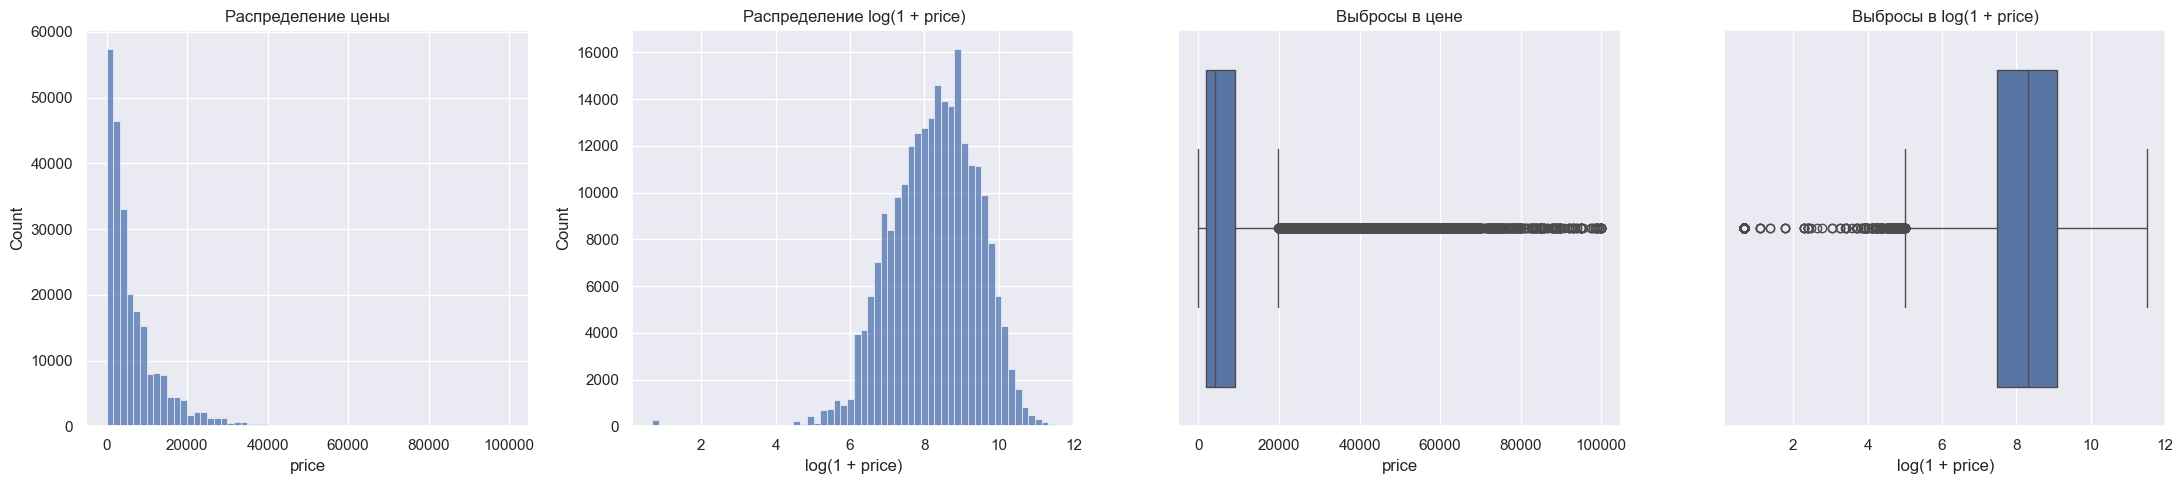

In [83]:
fig, axes = plt.subplots(1, 4, figsize=(22, 5))

log_price = np.log1p(data['price'])

sns.histplot(data=data, x='price', bins=60, ax=axes[0])
axes[0].set_title('Распределение цены')

sns.histplot(log_price, bins=60, ax=axes[1])
axes[1].set_title('Распределение log(1 + price)')
axes[1].set_xlabel('log(1 + price)')

sns.boxplot(x=data['price'], ax=axes[2])
axes[2].set_title('Выбросы в цене')

sns.boxplot(x=log_price, ax=axes[3])
axes[3].set_title('Выбросы в log(1 + price)')
axes[3].set_xlabel('log(1 + price)')

plt.tight_layout()
plt.show()

In [84]:
display( data['price'].quantile( [0, 0.001, 0.005, 0.01, 0.5, 0.95, 0.99, 0.995, 1] ) )

print('price == 1:', (data['price'] == 1).sum())
print('price <= 10:', (data['price'] <= 10).sum())
print('price <= 100:', (data['price'] <= 100).sum())
print('price => 50 000:', (data['price'] >= 50_000).sum())

0.000        1.00
0.001        1.00
0.005      175.00
0.010      250.00
0.500     4100.00
0.950    22000.00
0.990    37900.00
0.995    46602.75
1.000    99999.00
Name: price, dtype: float64

price == 1: 274
price <= 10: 292
price <= 100: 657
price => 50 000: 909


Добавляем в данные единичную колонку `bias`, чтобы не делать отдельные параметр $b$ для свободного члена модели.

## Выводы:
1. распределение цены исеет тяжелый правый хвос с множествами "выбросов" (видно по бокс-плоту) - такое возможно если есть большой дисбаланс между количеством иникальных значений. При её логарифмировании она становиться визуально более симметричным (возможно нормальным, но нужно пройти стат тесты для этого вывода).
2. Лог цены имеет уже левый тяжелый хвост, но "выбросов" слегка меньше.
3. Есть также странность в распределение цены связанные с её значениями. Есть чуть более 600 заявок с машинами на которых цена меньше 100, среди них 274 машин имеют цену равную 1, что достаточно подозрительно для ценообразовании машин. Это может свидетельствовать о том, что есть несколько групп машин с разной логикой ценообразования, либо, что есть "искажения" в данных (например из-за качественного источника данных) из-за чего нормальные цены превратились в такие малые.

Стоит взять в качестве целевого значения именно лог цену, а саму цену получать преобразованием предсказанной лог цены (но это скажется на среднюю ошибку предсказания цены, так как мы её находим косвенно, поэтому нельзя автоматически переносить значения разброса и смещения полученных в ходе анализа предсказателя лог цены на саму цену - они будут различаться и это нужно контролировать отдельно).

## Исследование влияния числовых признаков на целевую переменную

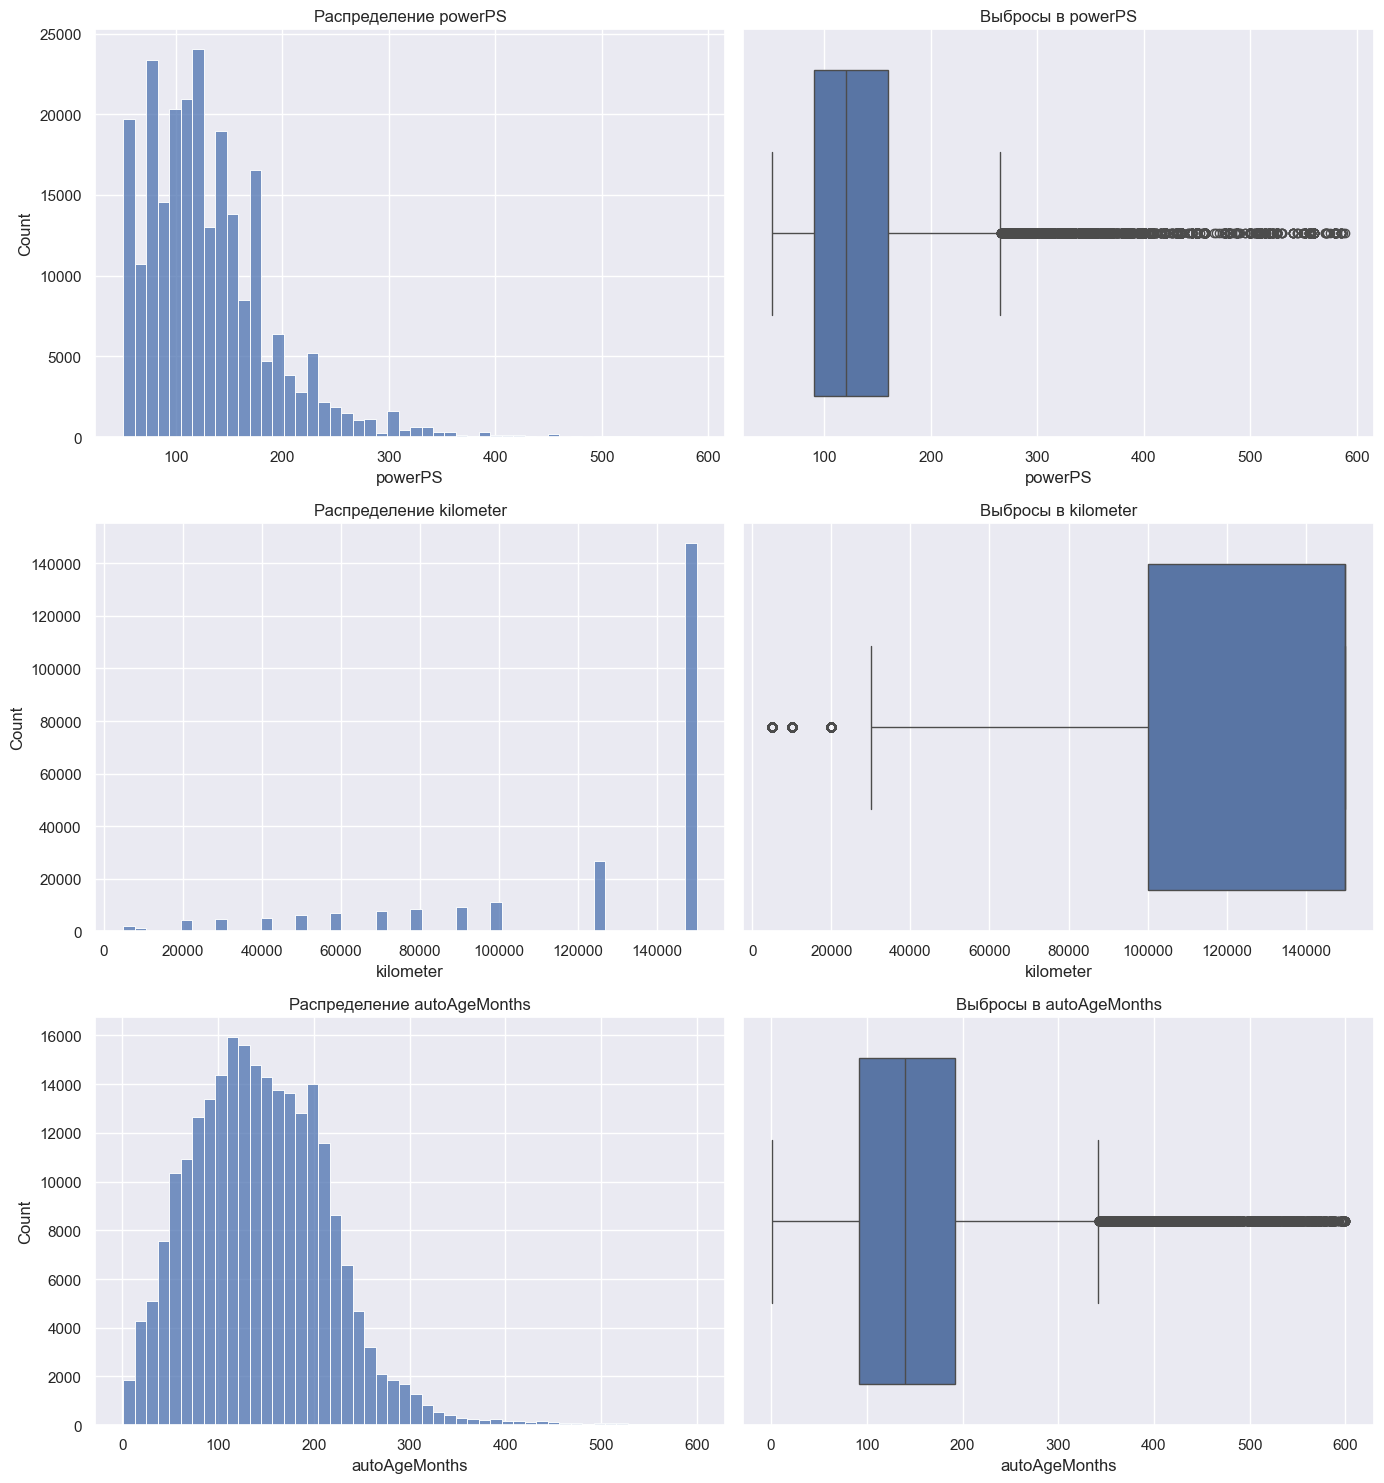

In [85]:
numeric = [ 'powerPS', 'kilometer', 'autoAgeMonths' ]
fig, axes = plt.subplots( len(numeric), 2, figsize=(14, 15) )

for row, column in enumerate(numeric):
    sns.histplot( data=data, x=column, bins=50, ax=axes[row, 0] )
    axes[row, 0].set_title(f'Распределение {column}')
    sns.boxplot( x=data[column], ax=axes[row, 1] )
    axes[row, 1].set_title(f'Выбросы в {column}')

plt.tight_layout()
plt.show()

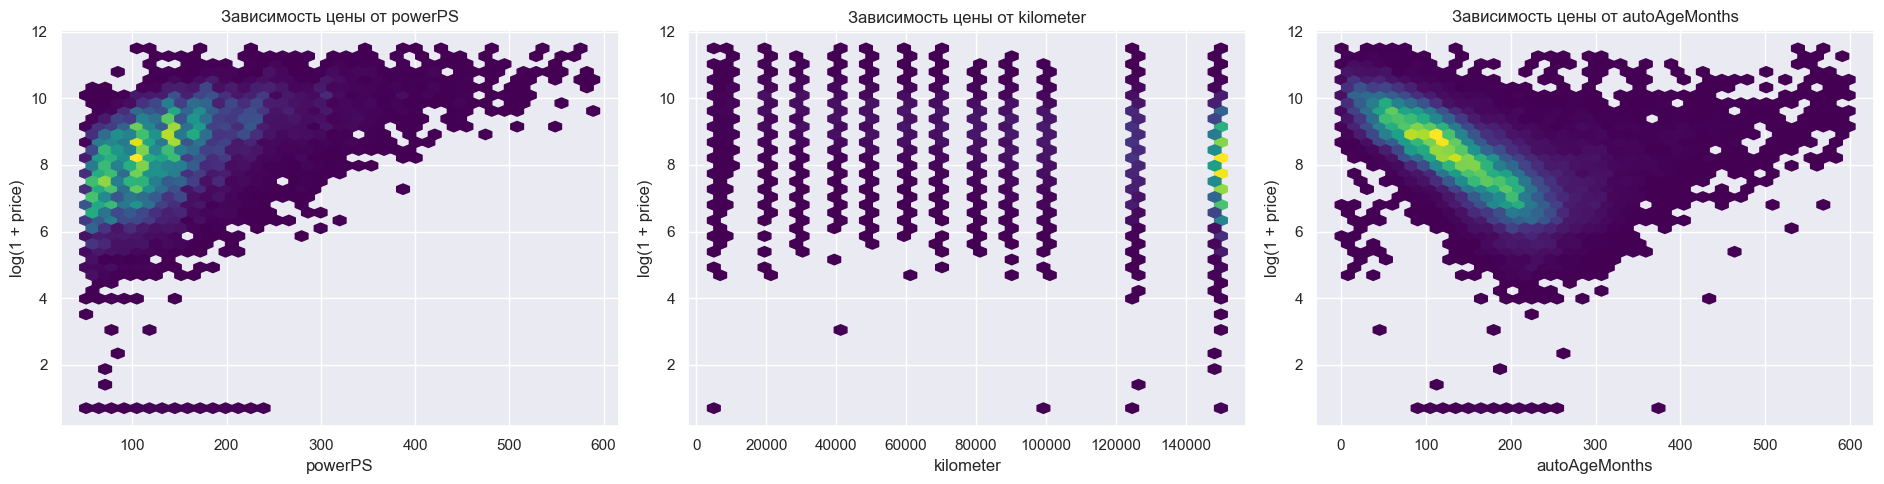

In [86]:
eda_data = data.copy()
eda_data['log_price'] = np.log1p(eda_data['price'])
plot_sample = eda_data.sample( n=min(50_000, len(eda_data)), random_state=42 )

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

for ax, column in zip(axes, numeric):
    ax.hexbin( plot_sample[column], plot_sample['log_price'], gridsize=40, mincnt=1, cmap='viridis' )

    ax.set_xlabel(column)
    ax.set_ylabel('log(1 + price)')
    ax.set_title(f'Зависимость цены от {column}')

plt.tight_layout()
plt.show()

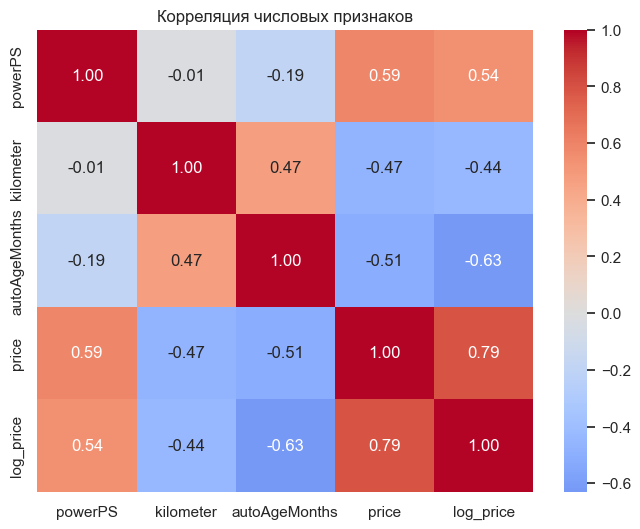

In [87]:
correlation = eda_data[ numeric + ['price', 'log_price'] ].corr()

plt.figure(figsize=(8, 6))
sns.heatmap( correlation, annot=True, fmt='.2f', cmap='coolwarm', center=0 )

plt.title('Корреляция числовых признаков')
plt.show()

## Выводы:
В ходе исследования были построены графики: эмпирического распределения, бокс-плоты, плотностные карты зависимости цены от признаков, матрица корреляций
1. распределения признаков "мощность" и "возраста" имеют тяжелые правые хвосты - возможно, стоит провести над ними лог преобразования, чтобы получить более симметричное распределение (то, что было проделанно с ценною). При этом признак "Пробег" по распределению более дискретен, чем непрерывен, возможно, стоит его отнести к группе признаков ординарных (так как имеется отношение порядка между значениями) - но для простаты работы оставляем данный признак в качестве непрерывного числового.
2.  по плотностным картам видны зависимости лог цены от признаков: у "Мощности" - прямо пропорциональная или возможно логарифмическая, у "Возраста" - в большей степени (в области высокой плотности) обратно порпорциональная, но в среднем (по всей основной области не считая "выбросы") скорее квадратичная. Зависимость от "Пробега" трудно визуально определить, т.к. нет крупных облостей (и сам признак ведет себя более дискретно как отмечалось ранее), но зато есть высокая плотность у машин с большим пробегом - это согласуется с распределением данного признака, концентрация возникает у медианного значения (чуть больше 8) по лог цене. Также видно по каждом из графиков что есть выбросы, но также и область слишком подозрительная, чтобы считать её стандартным выбросом (горизонтальная линия заметная и у "Мощности" и у "Возраста" у около нулевого значения лог цены) - возможно это отдельный кластер (группа машин) со своим ценообразованием, цены которых нельзя определить на основе остальных данных.
3. Матрица корреляций подтвержает выводы на основе плотностной карты, взаимосвязь от признака "Мощность"  положительная, а от "Возраста" и "Пробега" - отрицательная. При этом стоит обратить внимание между взаимосвязь признаков "Пробег" и "Возраст" - она умеренно положительная, это согласуется с логикой того, что чем сраше машина, тем больше у неё пробег. Это также наталкивает на мысль о том, что можно либо убрать признак "Пробег" из-за его дискретности и сильно дисбланс между значениями, либо применить PCA, чтобы снизить пространство признаков. 

## Исследование категориальных признаков

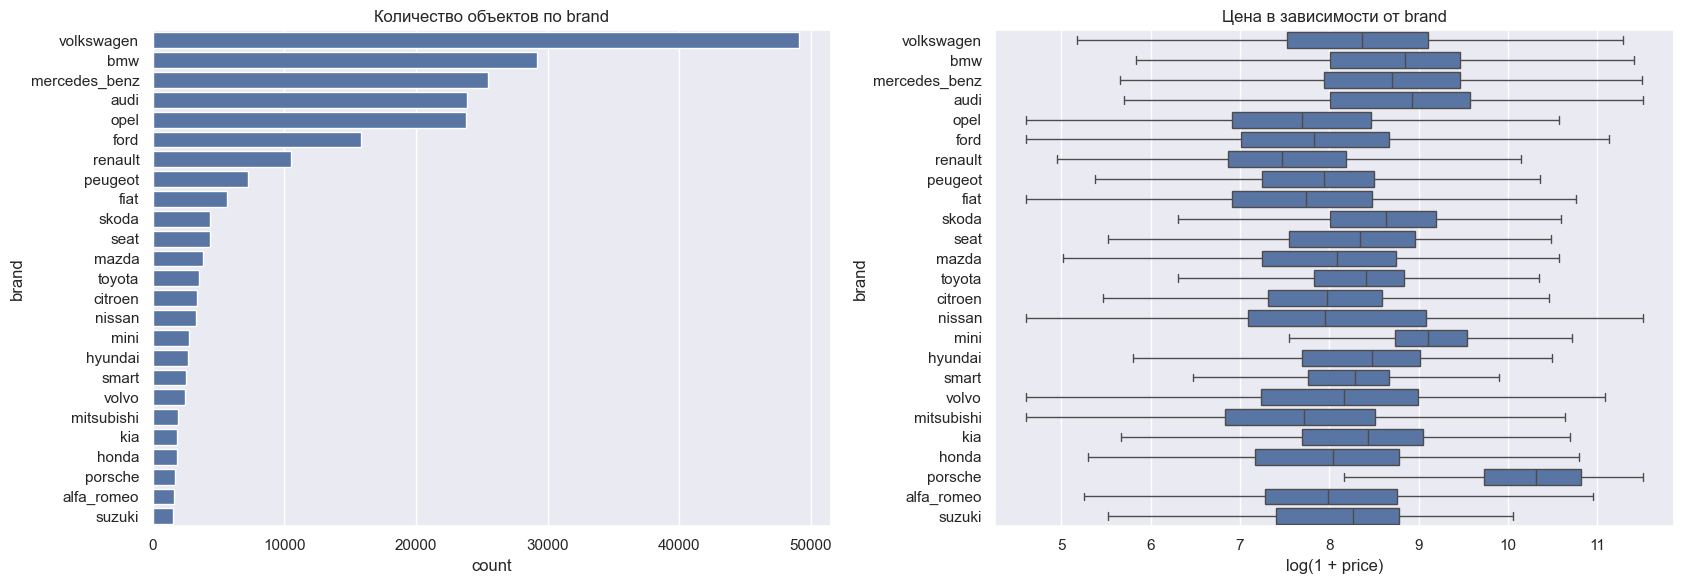

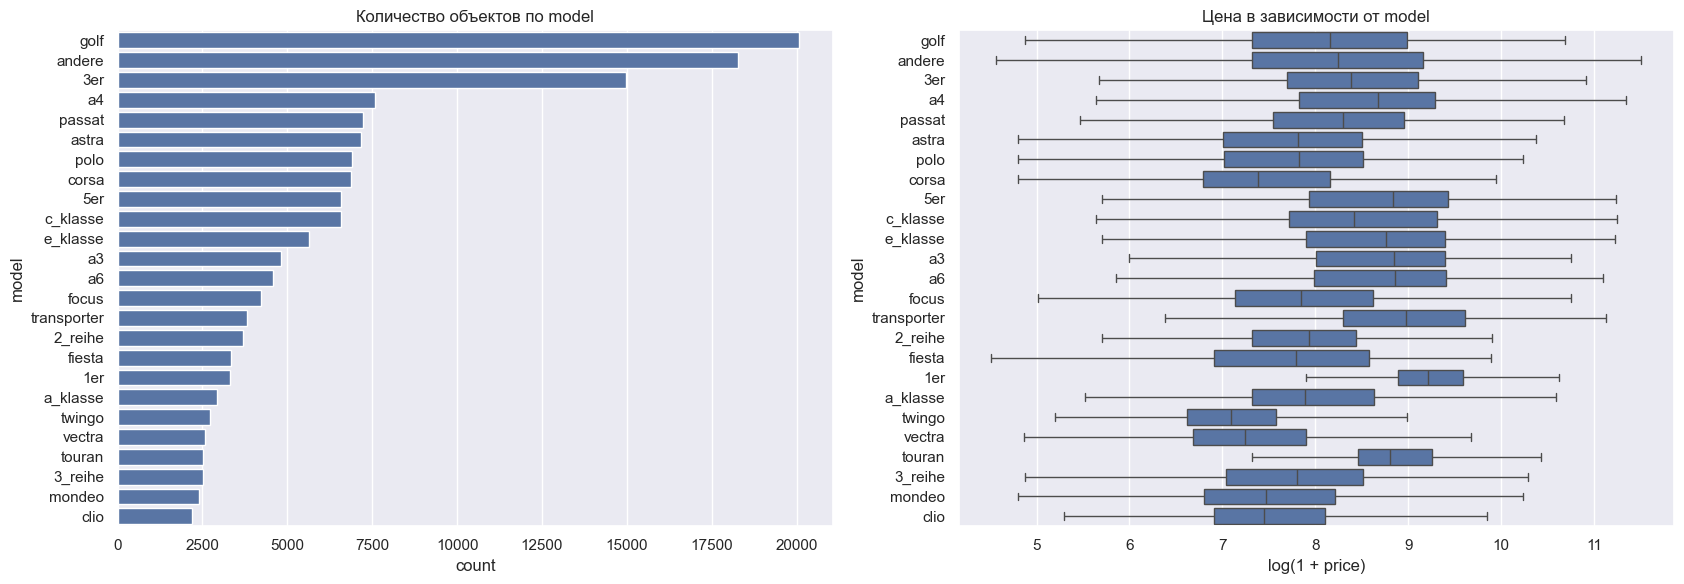

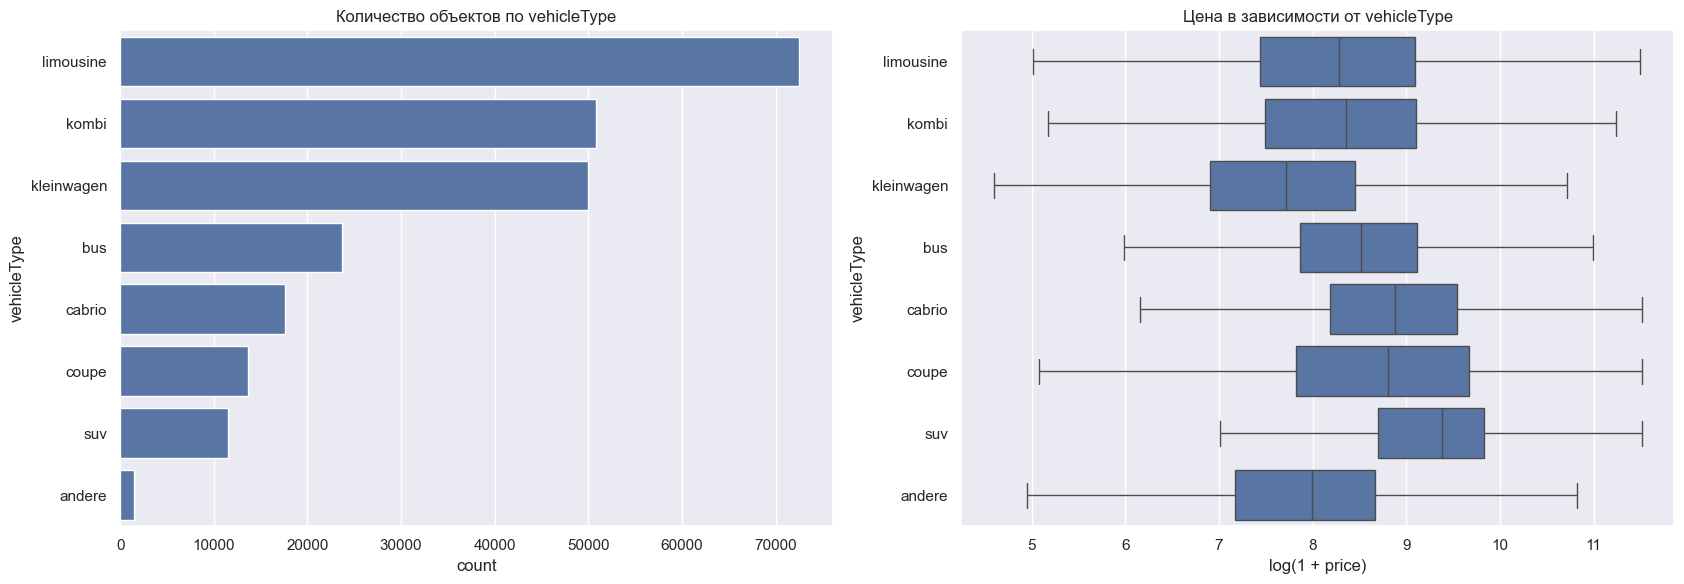

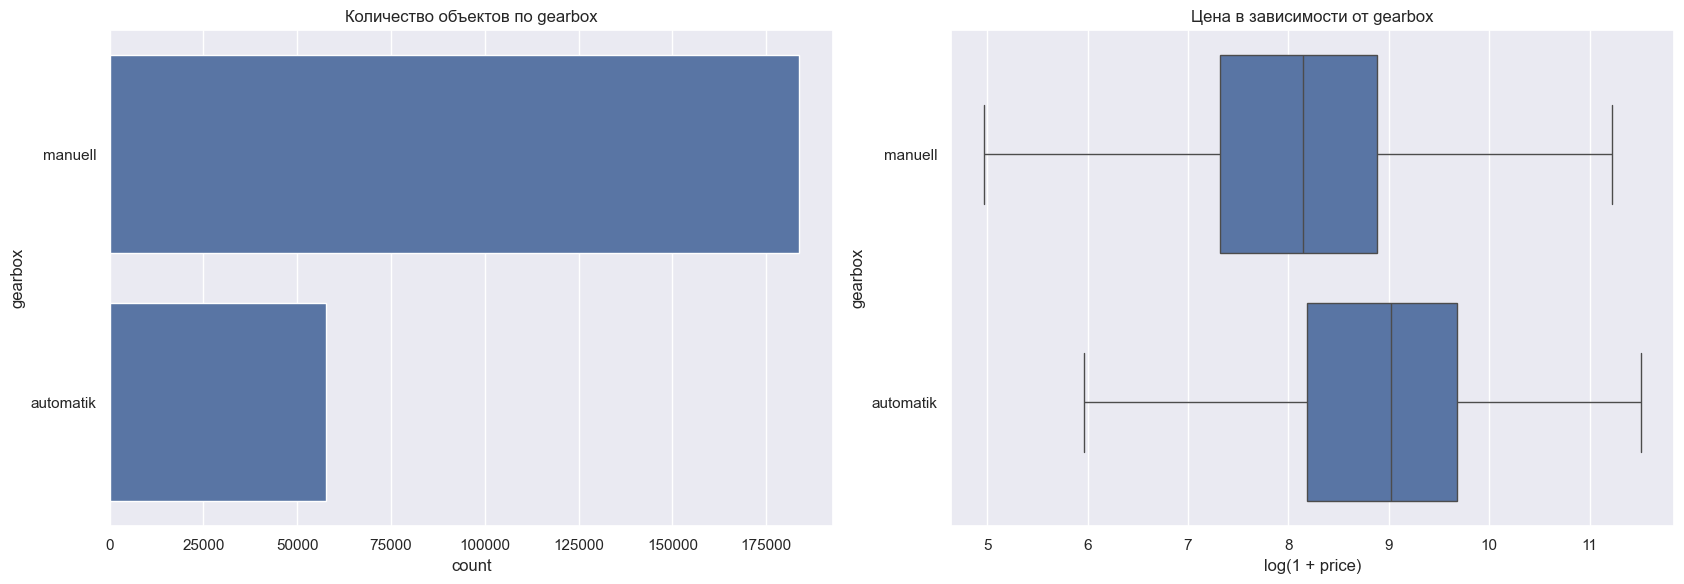

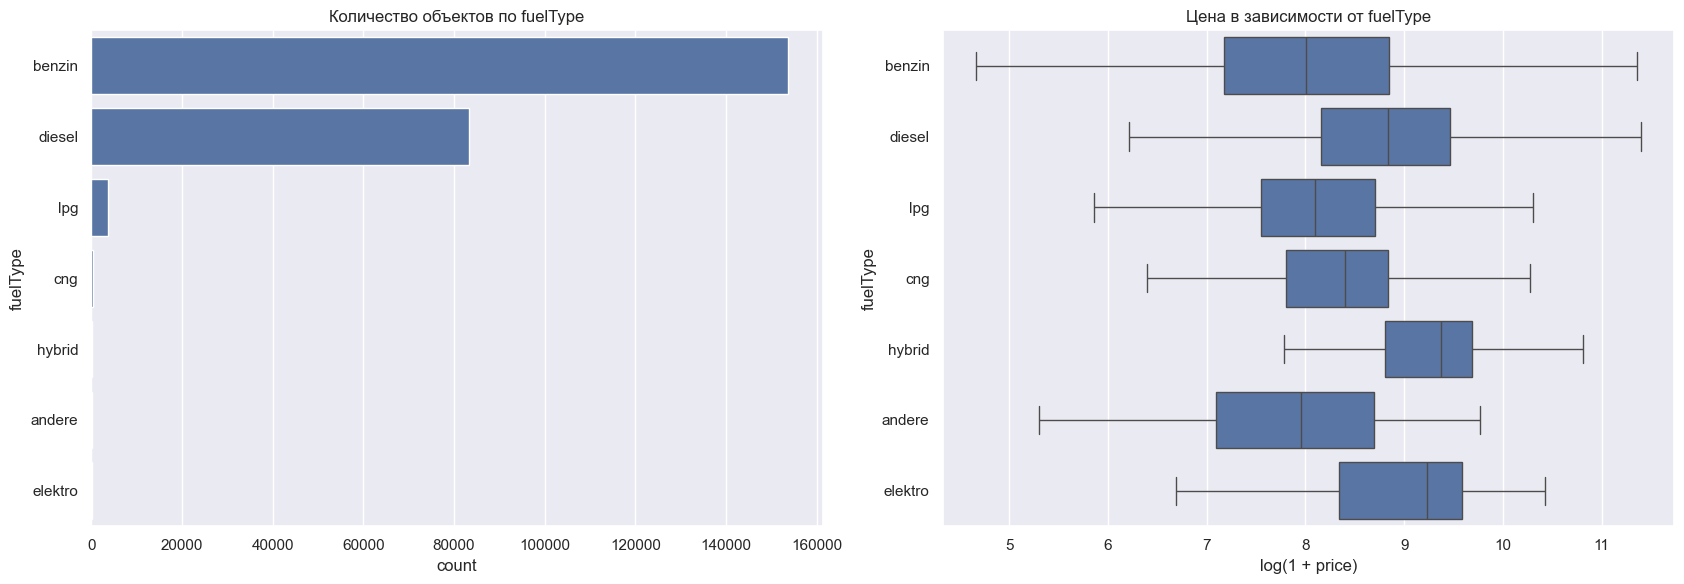

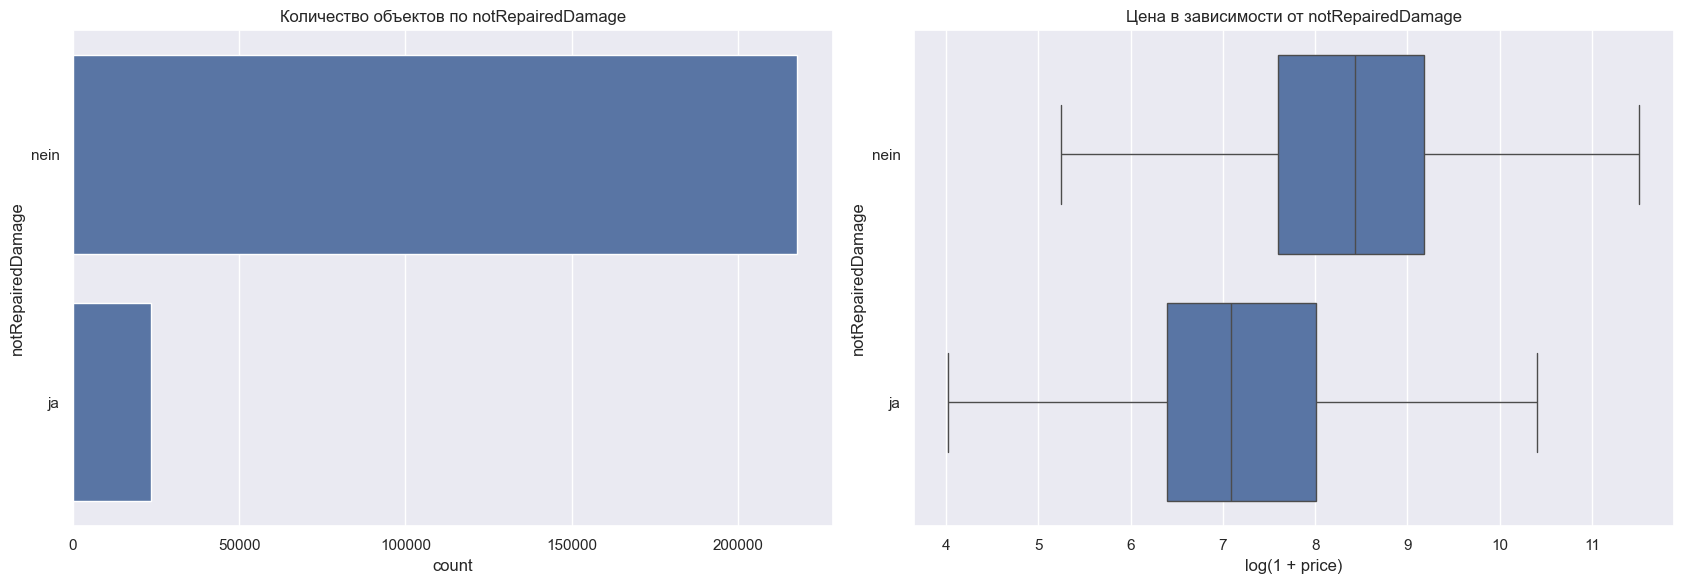

In [88]:
def plot_categorical_feature(data, column, top_n=25):
    cat_order = ( data[column] .value_counts() .head(top_n) .index )

    plot_data = data[data[column].isin(cat_order)].copy()

    fig, axes = plt.subplots(1, 2, figsize=(17, 6))
    sns.countplot( data=plot_data, y=column, order=cat_order, ax=axes[0] )
    axes[0].set_title(f'Количество объектов по {column}')
    sns.boxplot( data=plot_data, y=column, x='log_price', order=cat_order, showfliers=False, ax=axes[1] )
    axes[1].set_title(f'Цена в зависимости от {column}')
    axes[1].set_xlabel('log(1 + price)')

    plt.tight_layout()
    plt.show()
    
for column in categorical:
    plot_categorical_feature(eda_data, column)

In [89]:
pairs_bm = []
for feat_a, feat_b in combinations( categorical, 2 ):
    unique_count = ( data[[feat_a, feat_b]] .drop_duplicates() .shape[0] )
    pairs_bm.append({ 'Признаки': f'{feat_a} + {feat_b}', 'Количество уникальных пар': unique_count })
pair_counts_bm = ( pd.DataFrame(pairs_bm) .sort_values( 'Количество уникальных пар', ascending=False ) .reset_index(drop=True) )

display(pair_counts_bm)

,Признаки,Количество уникальных пар
0,model + vehicleType,980
1,model + fuelType,749
2,model + notRepairedDamage,489
3,model + gearbox,480
4,brand + model,295
5,brand + vehicleType,267
6,brand + fuelType,172
7,brand + notRepairedDamage,76
8,brand + gearbox,76
9,vehicleType + fuelType,53


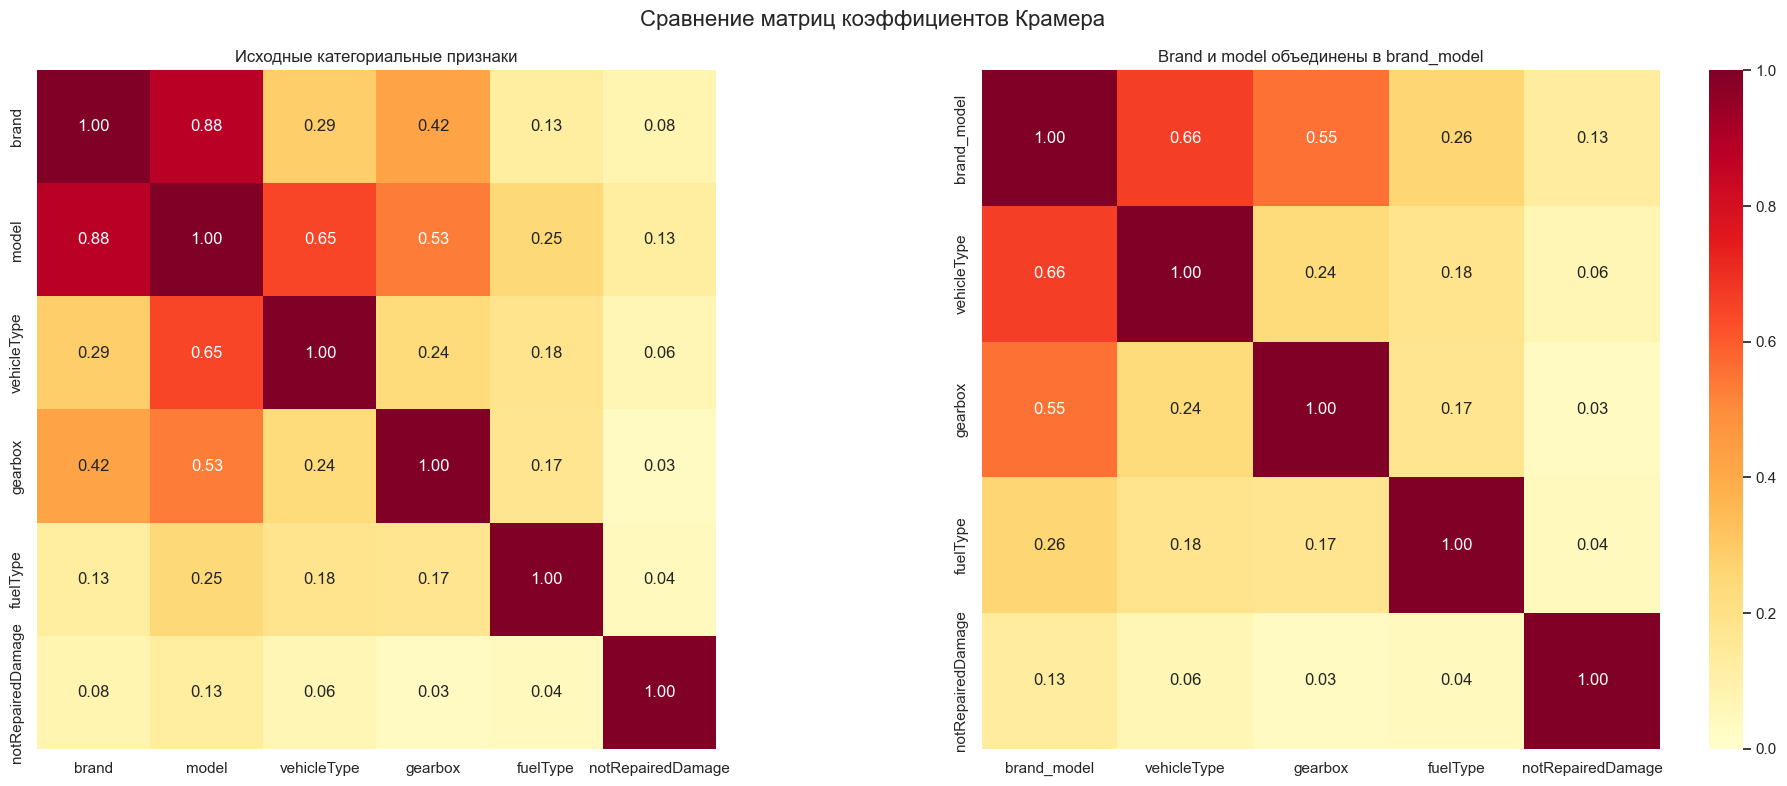

In [90]:
data['brand_model'] = ( data['brand'].astype(str) + '_' + data['model'].astype(str) )
cat_bm = [ 'brand_model' ] + [ column for column in categorical if column not in ['brand', 'model'] ]


def cramers_v(feat_a, feat_b):
    counts = pd.crosstab( feat_a, feat_b )
    chi2 = chi2_contingency( counts, correction=False )[0]

    n_obs = counts.to_numpy().sum()
    n_rows, n_cols = counts.shape

    denominator = min(n_rows - 1, n_cols - 1)

    if denominator == 0:
        return 0.0
    return np.sqrt( chi2 / (n_obs * denominator) )


def create_cramers_matrix(data, columns):
    matrix = pd.DataFrame( np.eye(len(columns)), index=columns, columns=columns )

    for feat_a, feat_b in combinations(columns, 2):
        value = cramers_v( data[feat_a], data[feat_b] )

        matrix.loc[feat_a, feat_b] = value
        matrix.loc[feat_b, feat_a] = value

    return matrix
cramer_orig = create_cramers_matrix( data, categorical )
cramer_bm = create_cramers_matrix( data, cat_bm )
fig, axes = plt.subplots( 1, 2, figsize=(20, 8) )
sns.heatmap( cramer_orig, annot=True, fmt='.2f', cmap='YlOrRd', vmin=0, vmax=1, square=True, cbar=False, ax=axes[0] )
axes[0].set_title( 'Исходные категориальные признаки' )
sns.heatmap( cramer_bm, annot=True, fmt='.2f', cmap='YlOrRd', vmin=0, vmax=1, square=True, ax=axes[1] )
axes[1].set_title( 'Brand и model объединены в brand_model' )
fig.suptitle( 'Сравнение матриц коэффициентов Крамера', fontsize=16 )

plt.tight_layout()
plt.show()

In [91]:
pairs_bm = []
for feat_a, feat_b in combinations( cat_bm, 2 ):
    unique_count = ( data[[feat_a, feat_b]] .drop_duplicates() .shape[0] )
    pairs_bm.append({ 'Признаки': f'{feat_a} + {feat_b}', 'Количество уникальных пар': unique_count })
pair_counts_bm = ( pd.DataFrame(pairs_bm) .sort_values( 'Количество уникальных пар', ascending=False ) .reset_index(drop=True) )

display(pair_counts_bm)

,Признаки,Количество уникальных пар
0,brand_model + vehicleType,1238
1,brand_model + fuelType,891
2,brand_model + notRepairedDamage,576
3,brand_model + gearbox,567
4,vehicleType + fuelType,53
5,vehicleType + gearbox,16
6,vehicleType + notRepairedDamage,16
7,gearbox + fuelType,14
8,fuelType + notRepairedDamage,14
9,gearbox + notRepairedDamage,4


## Выводы:
В ходе исследования были построены графики распределения по частоте значений по каждому из признаков (отсортированы по убыванию и высвечены первые 25 позиций), а также бокс-плоты зависимости лог цены от значения признака 
1. Есть целая совокупность брендов машин, которые встречаются чаще всего: от Volkswagen до Ford - факстически за счет их количества и образуется медиана лог цены около 8. Также стоит отметить, что это не самые дорогие бренды машин, например, выделяется Porsche у которого медиана лог цены около 10.4 - но при этом количество авто на сайте меньше. Тем самым нет прямой зависимости между количеством авто бренда и ростом предложенной цены. Также стоит отметить, что "усы" бокс-плотов очень большие, это можно объяснить несколькими факторами:
   1. влияниет не просто бренд, но и состояние машины - то есть числовые признаки
   2. внутри брендов есть множество моделей, а значит как премиальные, так и более бюджетные варианты
   3. гипотеза о существовании разных групп со своим ценообразованием
2. Схожие выводы можно сделать и про признак "Модели": есть популярные модели и есть большой разброс цен. Но стоит сделать акцент на том, что количество уникальных значений признака - около 250, а значит при кодировании каждого значения нам понадобиться дополнительно столько же признаков, это увеличивает изначально количество признаков (пространство данных) в несколько десятков раз. Стоит задуматься над тем, чтобы либо убрать данный признак (но он в связке с признаком "Брэнд" дает возможность различать разные по статусу машин - то есть по цене, что сам брэнд не сможет сделать, а точнее брэнд усреднит эти различия в предсказатели и для машин с одними и теме же данными кроме как "Модель" будет выдавать один и тот же ответ). Либо стоит объединить модели в более сжатые группы, например: бизнес модель, семейная модель, бюджетная модель - но для этого нужно будет разделить саму лог-цену на такие категории и внутри заданных категорий изучить распределение по каждой из данных выделенных категорий - но данные категории имеют субъективную оценку, что явным образому будет сказываться на предсказания модели. Либо воспользоваться статистическим эмбедингом, допустим, на основе медиан числовых признаков и частот категориальных - это даст усредненный профиль каждой модели, но потенциально модет дать предсказателю больше возможностей для различения. Также стоит посмотреть на пару бренд + модель, чтобы понять насколько они определяют друг друга.
3. остальные признаки в целом имеют такой же характер выводов: есть доминирующие значения, большой разброс лог цены.
4. Матрицы Крамера и таблица уникальных значений пар указывают на то, что пара брэнд и модель может быть единным индификатором типа машины (а не двумя различными признаками, потому что из потенциально 38 * 249 пар есть только 295 пар), это означает что при горячем кодирование, стоит кодировать именно связку этих признаков, а не по отдельности.

## Исследование гипотезы о существовании групп с разным ценообразованием
Как отмечалось ранее большой ценовой разброс может быть вызван смешением нескольких групп с различной логикой ценообразовании. Здесь проводиться исследование о разбиении данных на несколько групп, в качестве таковых взято первоначально разбиение данные на две группы: центральный сегмент и сегмент с низкой стоимостью. Разбиение проводиться по 25-ому квантилю лог цены. Графики повторяются что и для изучения общей совокупности данных.

Q25 всей выборки: 1750
Q75 всей выборки: 8999

Центральный сегмент: 181858 (75.40%)
Нижний сегмент: 59332 (24.60%)

Верхний ус центрального сегмента: 66000
Экстремально высокие цены: 330 (0.181% центрального сегмента)

Нижний ус нижнего сегмента: 217
Экстремально низкие цены: 1978 (3.334% нижнего сегмента)


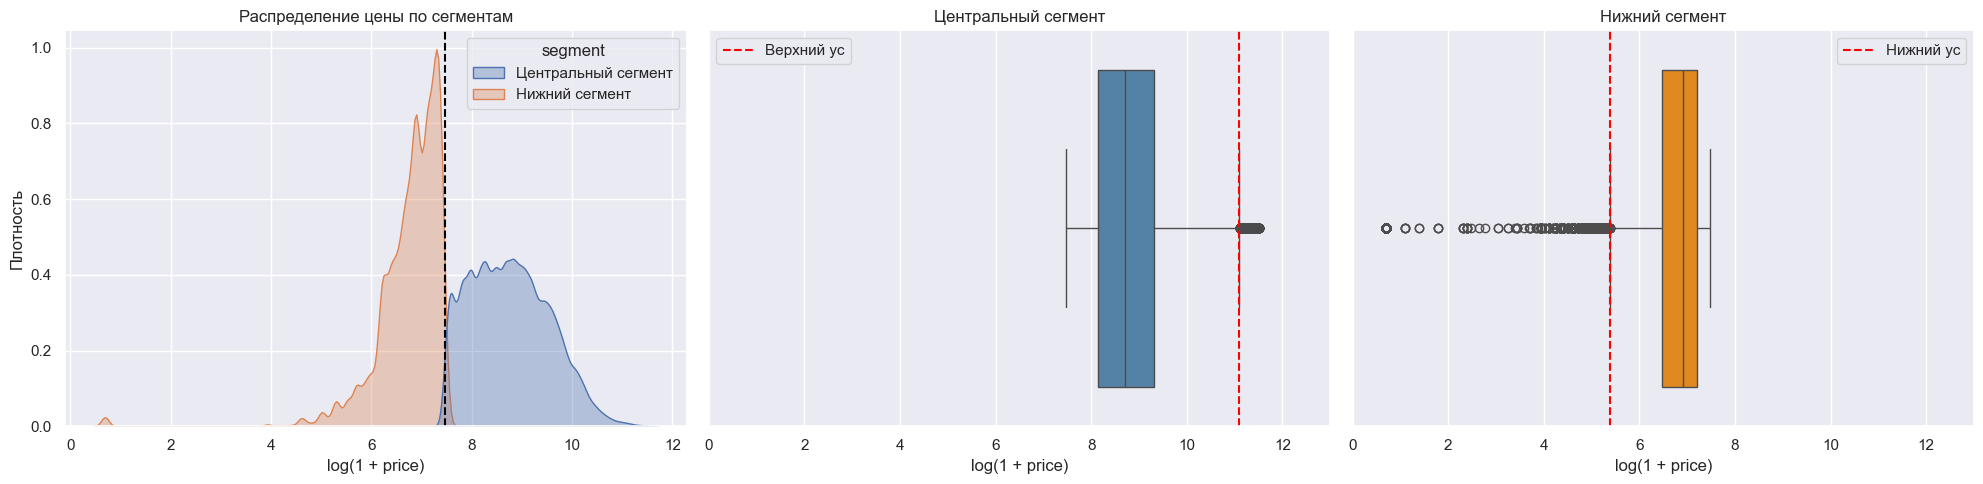

In [92]:
data['log_price'] = np.log1p(data['price'])

q25 = data['log_price'].quantile(0.25)
q75 = data['log_price'].quantile(0.75)
central = data[ data['log_price'] >= q25 ].copy()
low_price = data[ data['log_price'] < q25 ].copy()
central_q1 = central[ 'log_price' ].quantile(0.25)
central_q3 = central[ 'log_price' ].quantile(0.75)
central_iqr = ( central_q3 - central_q1 )
central_fence = ( central_q3 + 1.5 * central_iqr )
central_whisker = central.loc[ central['log_price'] <= central_fence, 'log_price' ].max()
extreme_high = central[ central['log_price'] > central_whisker ].copy()
low_q1 = low_price[ 'log_price' ].quantile(0.25)
low_q3 = low_price[ 'log_price' ].quantile(0.75)
low_iqr = ( low_q3 - low_q1 )
low_fence = ( low_q1 - 1.5 * low_iqr )
low_whisker = low_price.loc[ low_price['log_price'] >= low_fence, 'log_price' ].min()
extreme_low = low_price[ low_price['log_price'] < low_whisker ].copy()



central['segment'] = 'Центральный сегмент'
low_price['segment'] = 'Нижний сегмент'
comparison = pd.concat( [central, low_price], ignore_index=True )


print(f'Q25 всей выборки: {np.expm1(q25):.0f}')
print(f'Q75 всей выборки: {np.expm1(q75):.0f}')
print( f'\nЦентральный сегмент: {len(central)} ' f'({len(central) / len(data):.2%})' )
print( f'Нижний сегмент: {len(low_price)} ' f'({len(low_price) / len(data):.2%})' )
print( '\nВерхний ус центрального сегмента: ' f'{np.expm1(central_whisker):.0f}' )
print( f'Экстремально высокие цены: ' f'{len(extreme_high)} ' f'({len(extreme_high) / len(central):.3%} ' f'центрального сегмента)' )
print( '\nНижний ус нижнего сегмента: ' f'{np.expm1(low_whisker):.0f}' )
print( f'Экстремально низкие цены: ' f'{len(extreme_low)} ' f'({len(extreme_low) / len(low_price):.3%} ' f'нижнего сегмента)' )


fig, axes = plt.subplots( 1, 3, figsize=(20, 5) )
sns.kdeplot( data=comparison, x='log_price', hue='segment', fill=True, alpha=0.35, common_norm=False, ax=axes[0] )
axes[0].axvline( q25, color='black', linestyle='--', label='Q25' )
axes[0].set_title( 'Распределение цены по сегментам' )

axes[0].set_xlabel('log(1 + price)')
axes[0].set_ylabel('Плотность')
sns.boxplot( x=central['log_price'], color='steelblue', ax=axes[1] )
axes[1].axvline( central_whisker, color='red', linestyle='--', label='Верхний ус' )

axes[1].set_title('Центральный сегмент')
axes[1].set_xlabel('log(1 + price)')
axes[1].legend()
sns.boxplot( x=low_price['log_price'], color='darkorange', ax=axes[2] )
axes[2].axvline( low_whisker, color='red', linestyle='--', label='Нижний ус' )

axes[2].set_title('Нижний сегмент')
axes[2].set_xlabel('log(1 + price)')
axes[2].legend()
price_limits = ( 0, 13 )

axes[1].set_xlim(price_limits)
axes[2].set_xlim(price_limits)

plt.tight_layout()
plt.show()

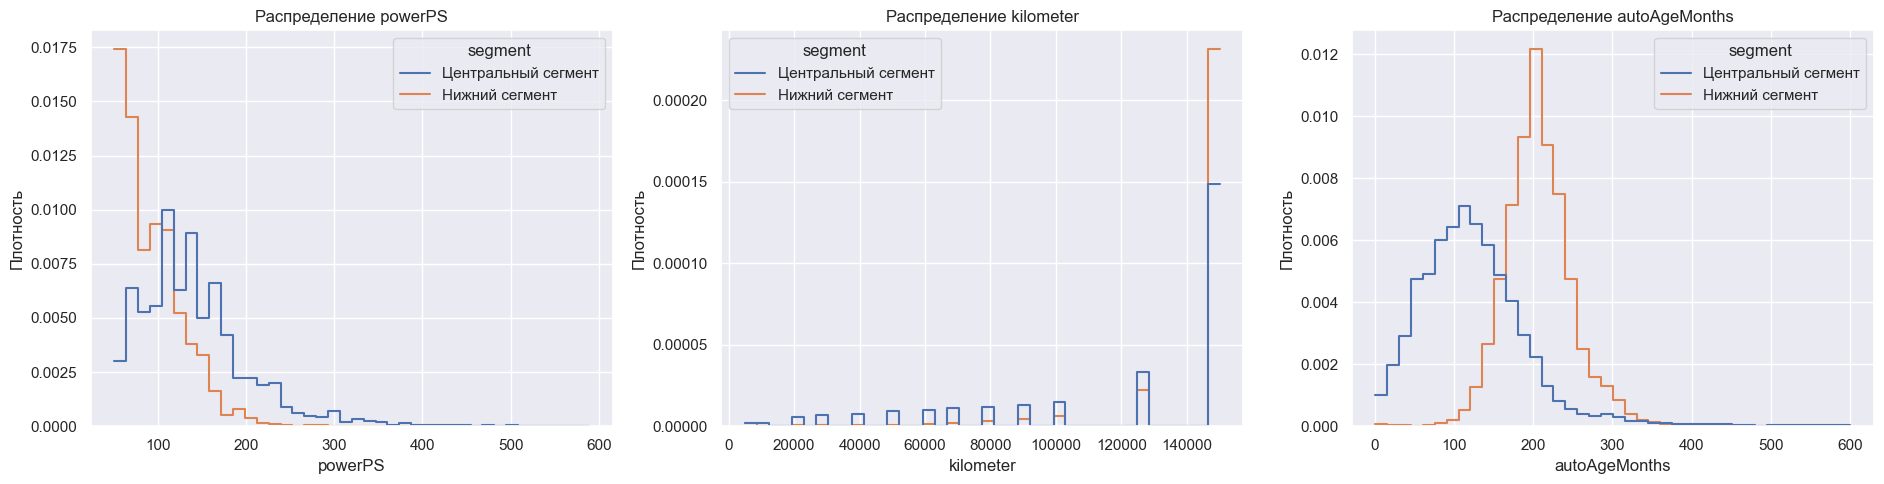

In [93]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

for ax, column in zip(axes, numeric):
    sns.histplot( data=comparison, x=column, hue='segment', bins=40, stat='density', common_norm=False, element='step', fill=False, ax=ax )

    ax.set_title(f'Распределение {column}')
    ax.set_ylabel('Плотность')

plt.tight_layout()
plt.show()

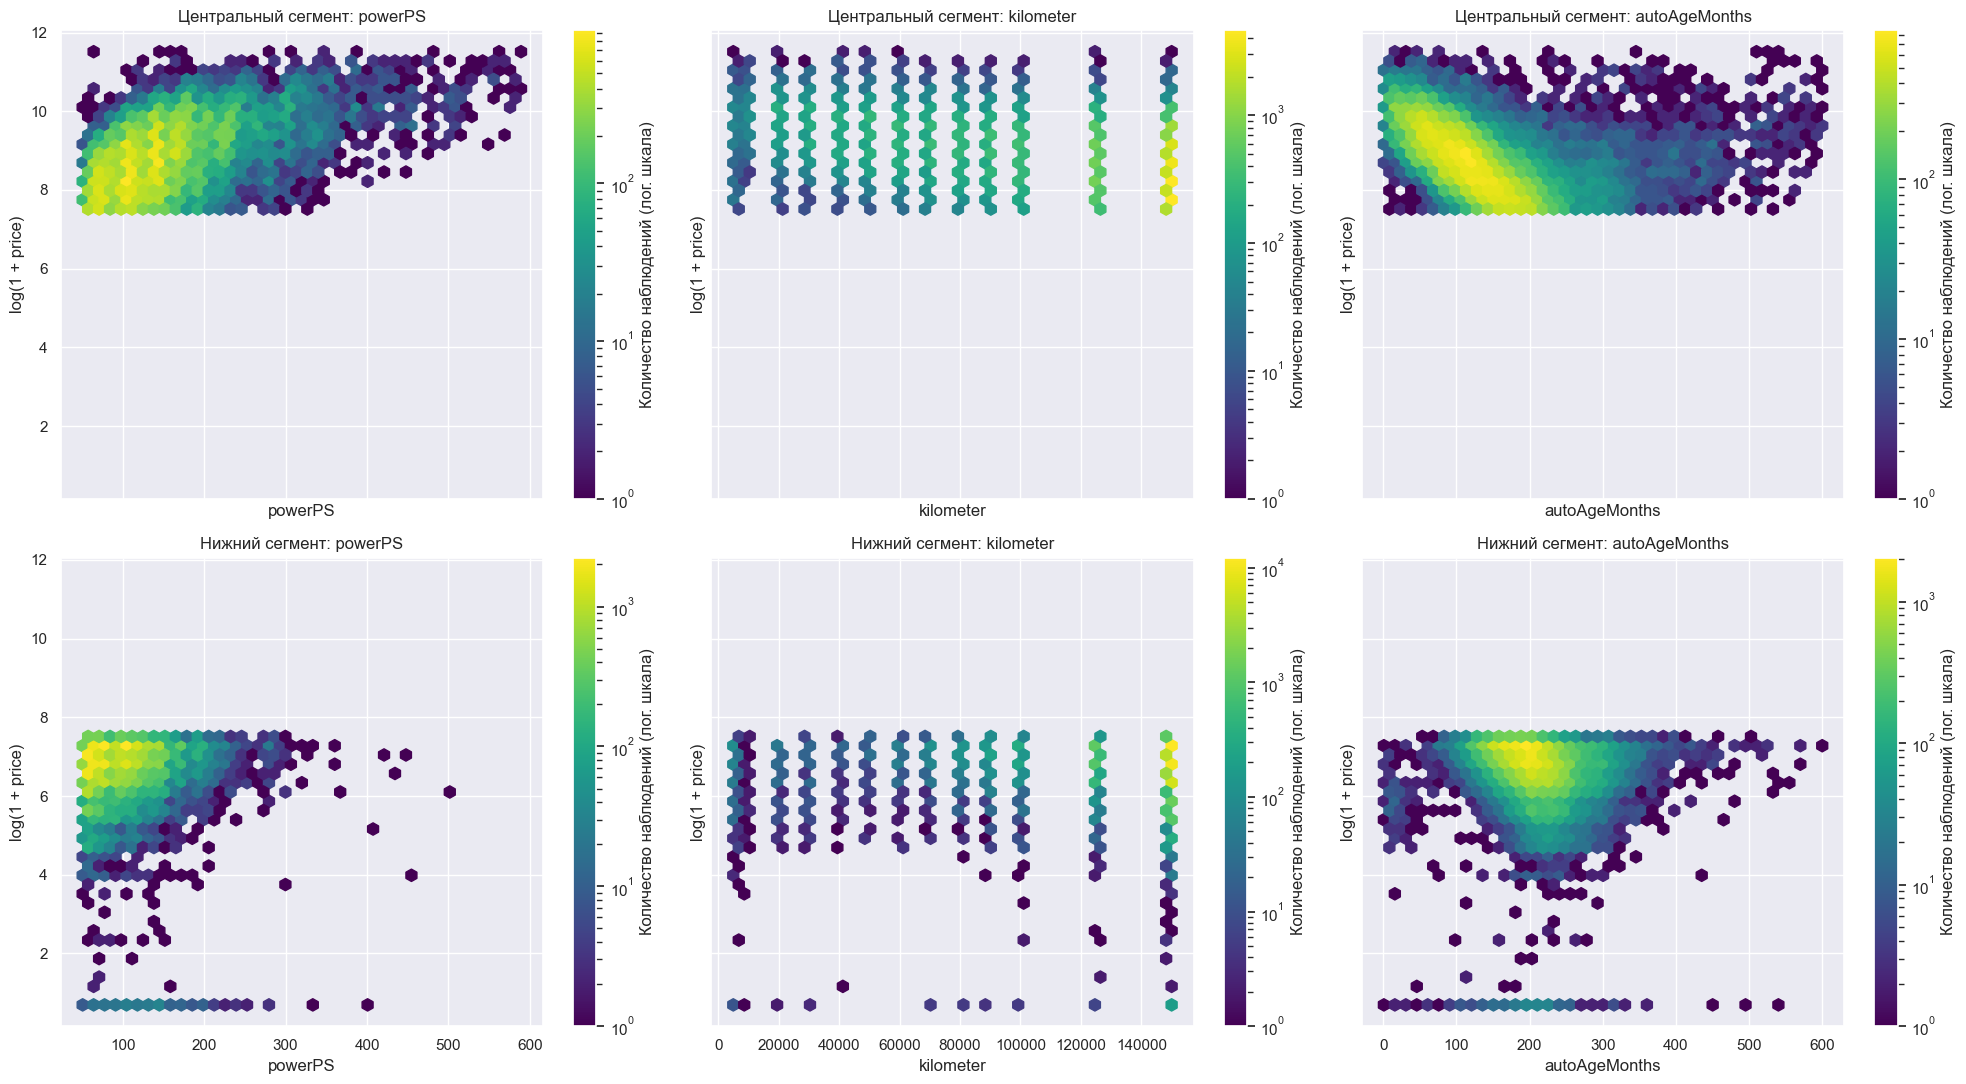

In [94]:
sample_size = min( 50_000, len(central), len(low_price) )
groups = [ ( 'Центральный сегмент', central.sample(sample_size, random_state=42) ), ( 'Нижний сегмент', low_price.sample(sample_size, random_state=42) ) ]

y_min = comparison['log_price'].min()
y_max = comparison['log_price'].max()
fig, axes = plt.subplots( 2, 3, figsize=(20, 11), sharex='col', sharey=True )

for row, (group_name, group_data) in enumerate(groups):
    for column_number, feature in enumerate(numeric):
        ax = axes[row, column_number]
        hexbin = ax.hexbin( group_data[feature], group_data['log_price'], gridsize=40, mincnt=1, bins='log', cmap='viridis', extent=( comparison[feature].min(), comparison[feature].max(), y_min, y_max ) )

        ax.set_title(f'{group_name}: {feature}')
        ax.set_xlabel(feature)
        ax.set_ylabel('log(1 + price)')
        fig.colorbar( hexbin, ax=ax, label='Количество наблюдений (лог. шкала)' )

plt.tight_layout()
plt.show()

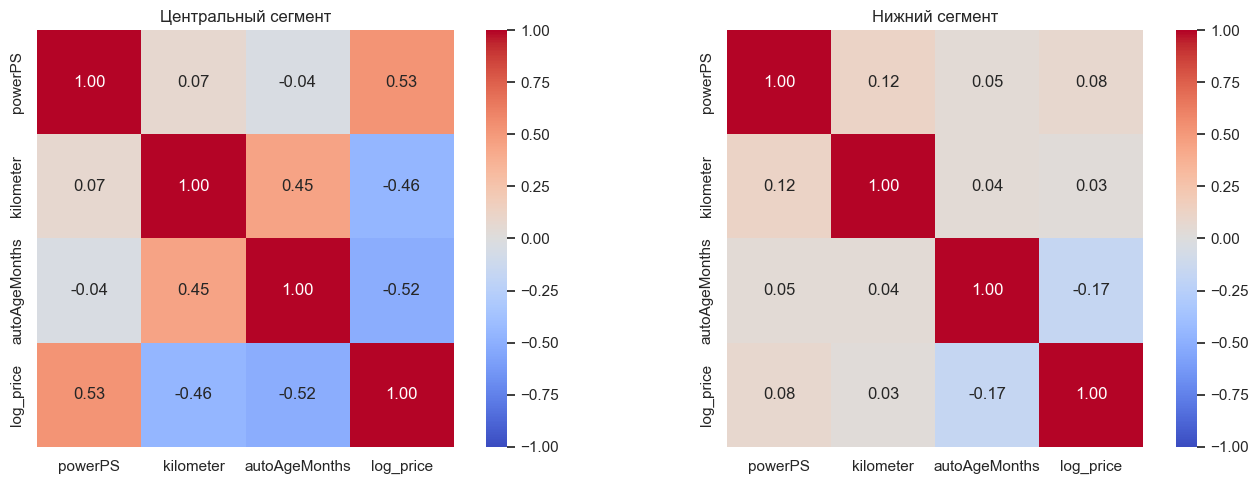

In [95]:
corr_cols = numeric + ['log_price']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
corr_groups = [ ('Центральный сегмент', central), ('Нижний сегмент', low_price) ]
for ax, (group_name, group_data) in zip( axes, corr_groups ):
    correlation = group_data[ corr_cols ].corr(method='pearson')
    sns.heatmap( correlation, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1, square=True, ax=ax )

    ax.set_title(group_name)

plt.tight_layout()
plt.show()

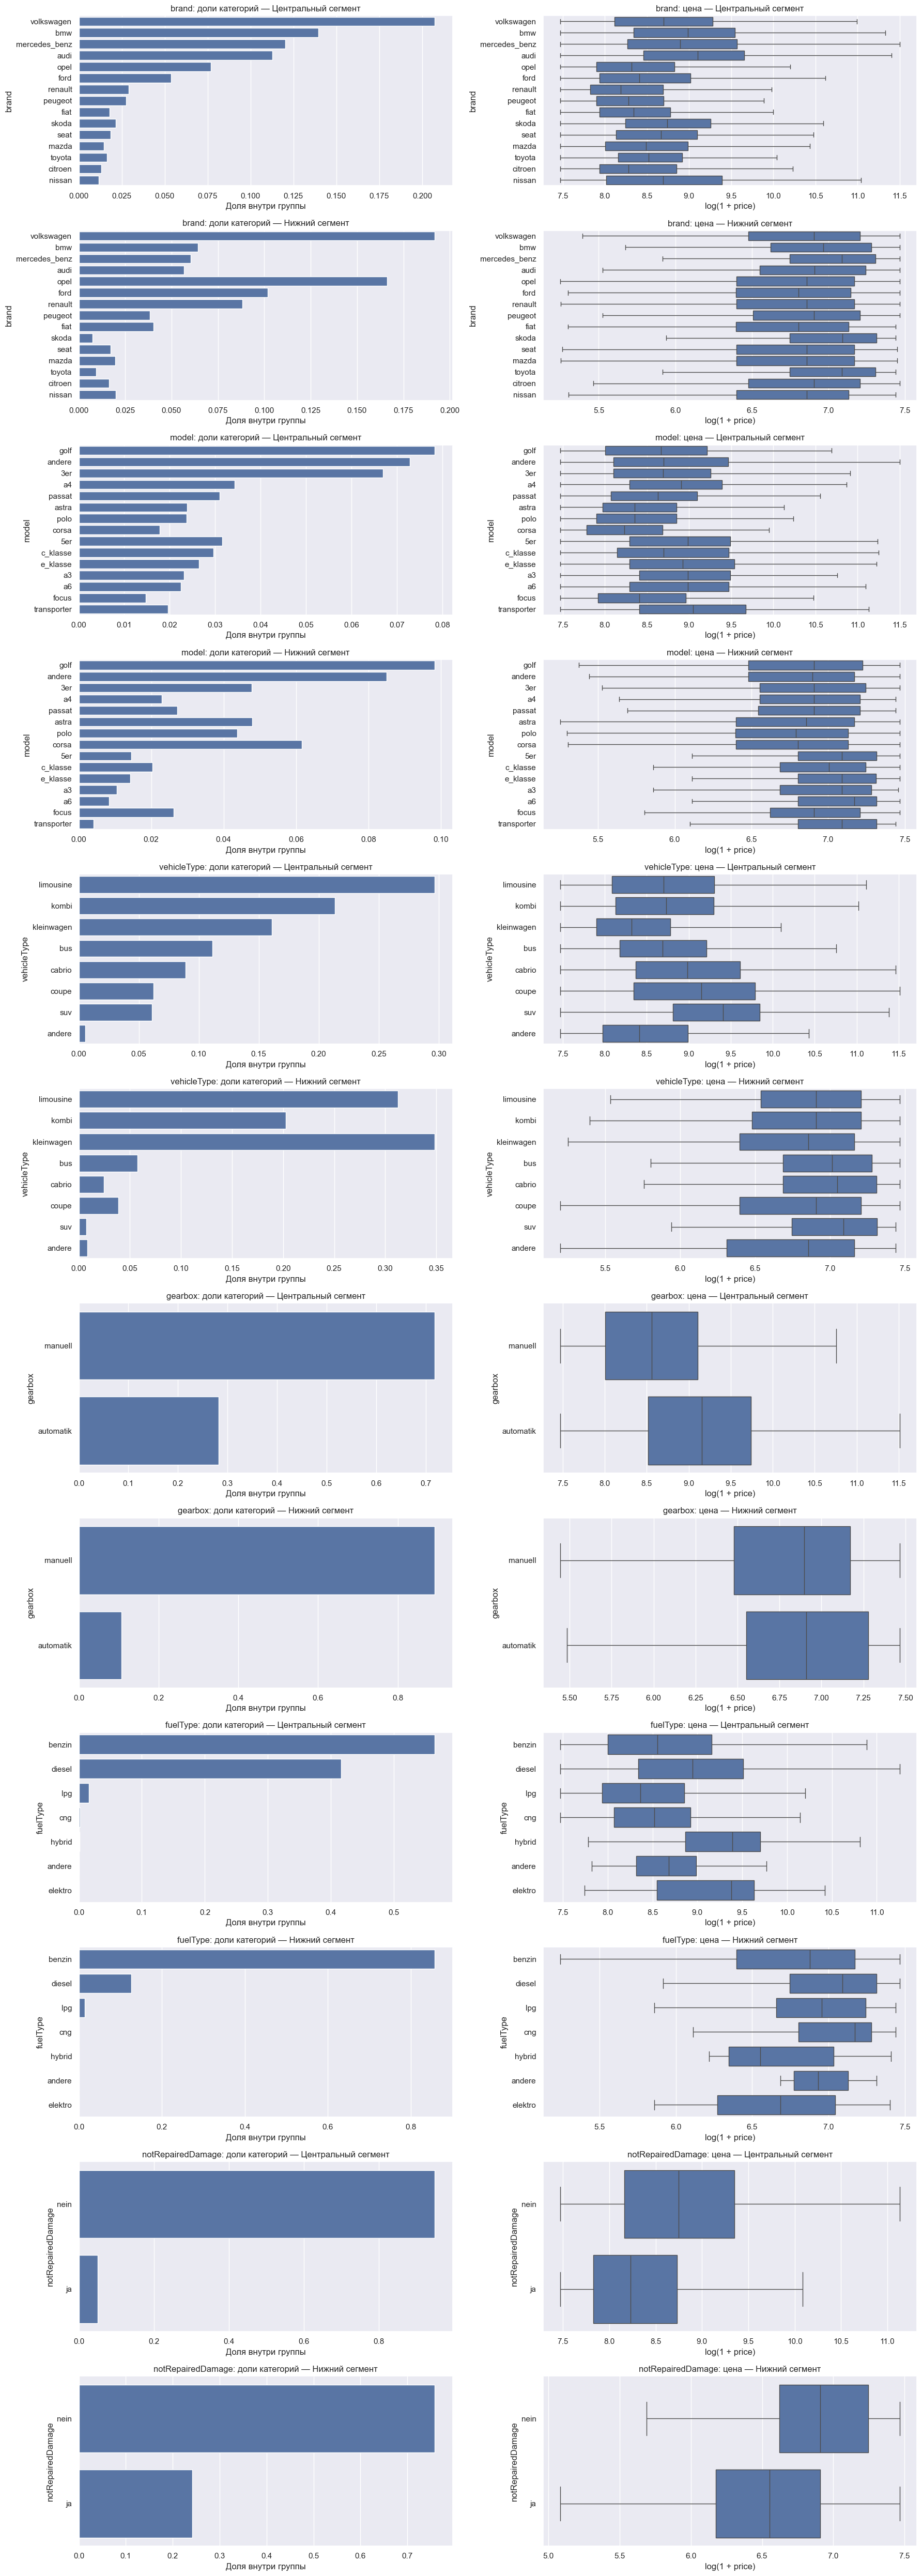

In [96]:
fig, axes = plt.subplots( len(categorical) * 2, 2, figsize=(18, 50) )
cat_groups = [ ('Центральный сегмент', central), ('Нижний сегмент', low_price) ]

for feature_number, feature in enumerate(categorical):
    cat_order = ( data[feature] .value_counts() .head(15) .index )
    for group_number, (group_name, group_data) in enumerate( cat_groups ):
        row = feature_number * 2 + group_number
        cat_shares = ( group_data[feature] .value_counts(normalize=True) .reindex(cat_order, fill_value=0) .rename_axis(feature) .reset_index(name='share') )
        sns.barplot( data=cat_shares, y=feature, x='share', order=cat_order, ax=axes[row, 0] )
        axes[row, 0].set_title( f'{feature}: доли категорий — {group_name}' )
        axes[row, 0].set_xlabel('Доля внутри группы')
        axes[row, 0].set_ylabel(feature)
        plot_data = group_data[ group_data[feature].isin(cat_order) ]
        sns.boxplot( data=plot_data, y=feature, x='log_price', order=cat_order, showfliers=False, ax=axes[row, 1] )
        axes[row, 1].set_title( f'{feature}: цена — {group_name}' )
        axes[row, 1].set_xlabel('log(1 + price)')
        axes[row, 1].set_ylabel(feature)

plt.tight_layout()
plt.show()

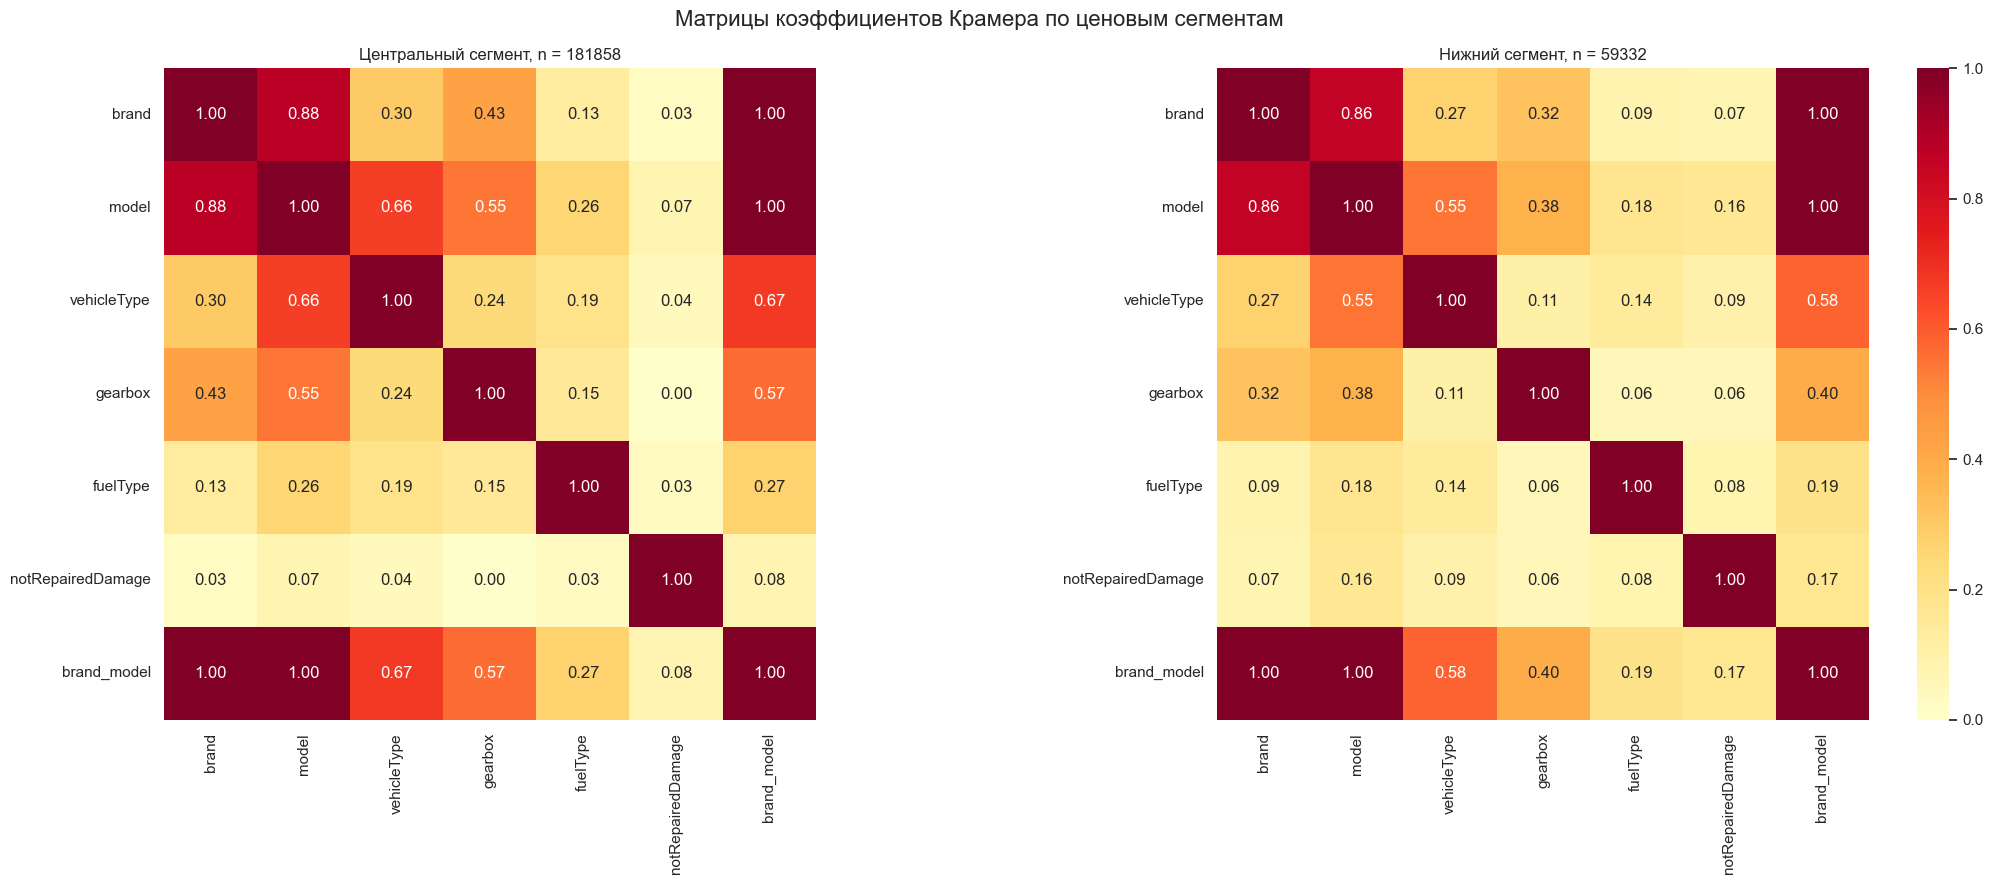

In [97]:
central['brand_model'] = ( central['brand'].astype(str) + '_' + central['model'].astype(str) )
low_price['brand_model'] = ( low_price['brand'].astype(str) + '_' + low_price['model'].astype(str) )



cat_with_bm = categorical.copy()

if 'brand_model' not in cat_with_bm:
    cat_with_bm.append('brand_model')
cramer_central = create_cramers_matrix( central, cat_with_bm )
cramer_low = create_cramers_matrix( low_price, cat_with_bm )



fig, axes = plt.subplots(1, 2, figsize=(22, 9))
sns.heatmap( cramer_central, annot=True, fmt='.2f', cmap='YlOrRd', vmin=0, vmax=1, square=True, cbar=False, ax=axes[0] )
axes[0].set_title( f'Центральный сегмент, n = {len(central)}' )
sns.heatmap( cramer_low, annot=True, fmt='.2f', cmap='YlOrRd', vmin=0, vmax=1, square=True, ax=axes[1] )
axes[1].set_title( f'Нижний сегмент, n = {len(low_price)}' )
fig.suptitle( 'Матрицы коэффициентов Крамера по ценовым сегментам', fontsize=16 )

plt.tight_layout()
plt.show()

In [98]:
summary_groups = { 'Центральный сегмент': central, 'Нижний сегмент': low_price, 'Цена не больше 100': extreme_low }

summary_rows = []

for group_name, group_data in summary_groups.items():
    summary_rows.append({ 'group': group_name, 'count': len(group_data), 'median_price': group_data['price'].median(), 'median_powerPS': group_data['powerPS'].median(), 'median_kilometer': group_data['kilometer'].median(), 'median_age': group_data['autoAgeMonths'].median(), 'damage_share': ( group_data['notRepairedDamage'] .eq('ja') .mean() ) })
group_summary = pd.DataFrame( summary_rows ).set_index('group')

display(group_summary)

,count,median_price,median_powerPS,median_kilometer,median_age,damage_share
group,,,,,,
Центральный сегмент,181858,6000.0,136.0,150000.0,117.0,0.050858
Нижний сегмент,59332,999.0,90.0,150000.0,204.0,0.241489
Цена не больше 100,1978,150.0,75.0,150000.0,223.0,0.588473


## Выводы:
В целом в каждой из групп остались те же самые зависимости, что и в изначальной совокупности. Однако наблюдая за плотностью распределения, плотностной картой и бокс-плотами по категориальным признакам нижнего сегмента, можно заключить что внутри него есть малая группа с абсолютно низкой ценной, поэтому если графики центрального сегмента достаточно симметричны и у них отсутствуют "выбросы", то у нижнего - графики указывают на толстый левый хвост и возможное существование действительно выбросов.
Пока рано отвергать или принимать гипотезу о существовании разных групп ценообразования, следует разобраться с этой малой группой и потом провести тест о том, не принадлежит ли нижний сегмент той же самой генеральной совокупности, что и центральный.

## Исследование малой группы с низким ценновым диапазоном
Исследование разбивает нижний сегмент на две группы: нижнюю и среднюю - по границы 100 относительно цены

Q25: 1750
Q75: 8999
Центральная группа: 181858
Средняя группа: 58884
Низкая группа: 448


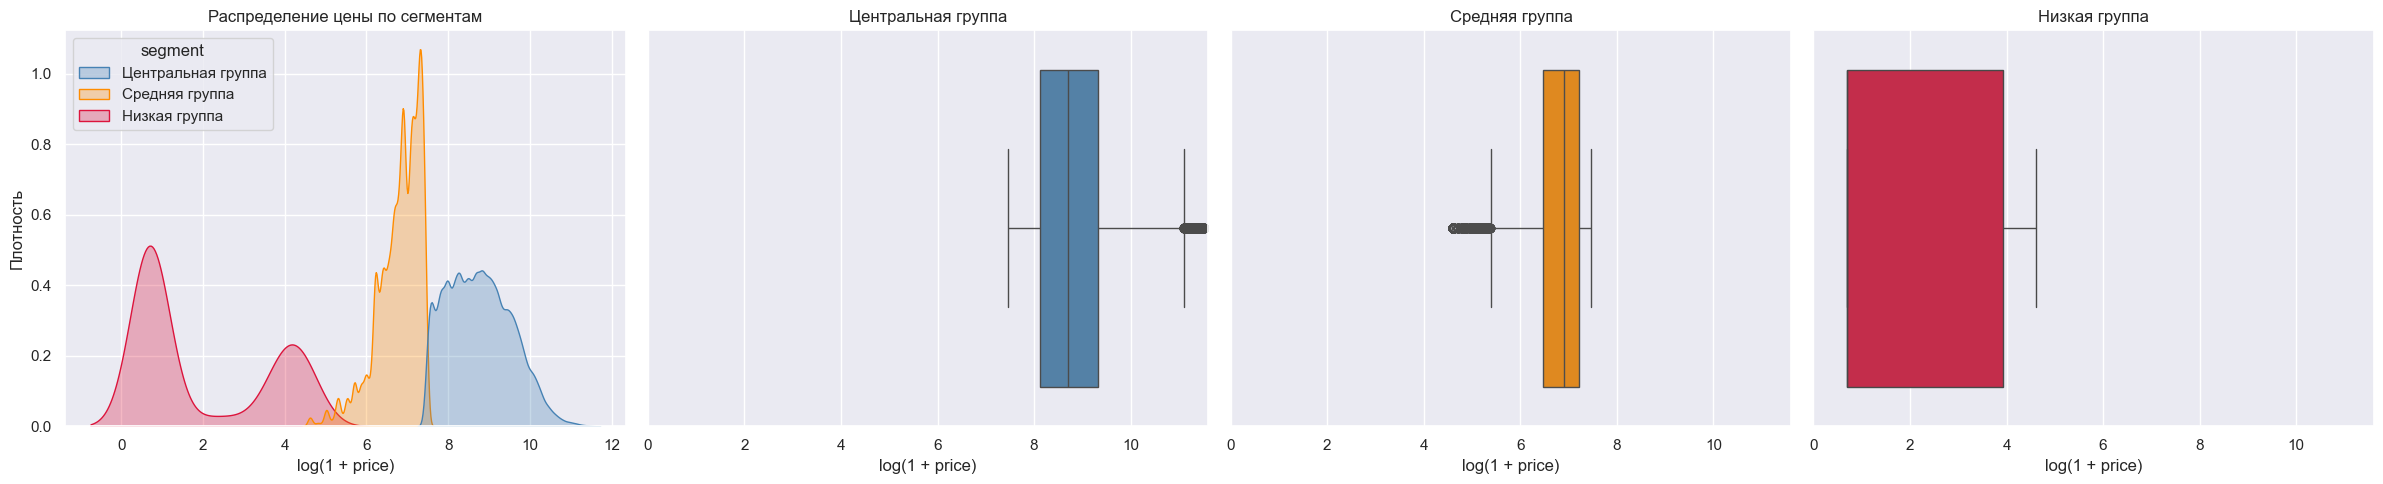

In [99]:
data['log_price'] = np.log1p(data['price'])

q25 = data['log_price'].quantile(0.25)
q75 = data['log_price'].quantile(0.75)
central = data[ data['log_price'] >= q25 ].copy()
medium_low = data[ (data['log_price'] < q25) & (data['price'] >= 100) ].copy()
extreme_low = data[ data['price'] < 100 ].copy()



central['segment'] = 'Центральная группа'
medium_low['segment'] = 'Средняя группа'
extreme_low['segment'] = 'Низкая группа'

low_groups = pd.concat( [medium_low, extreme_low], ignore_index=True )
segments = pd.concat( [central, medium_low, extreme_low], ignore_index=True )


print(f'Q25: {np.expm1(q25):.0f}')
print(f'Q75: {np.expm1(q75):.0f}')

print(f'Центральная группа: {len(central)}')
print(f'Средняя группа: {len(medium_low)}')
print(f'Низкая группа: {len(extreme_low)}')
seg_colors = { 'Центральная группа': 'steelblue', 'Средняя группа': 'darkorange', 'Низкая группа': 'crimson' }
fig, axes = plt.subplots( 1, 4, figsize=(24, 5) )
sns.kdeplot( data=segments, x='log_price', hue='segment', hue_order=[ 'Центральная группа', 'Средняя группа', 'Низкая группа' ], palette=seg_colors, fill=True, alpha=0.3, common_norm=False, ax=axes[0] )

axes[0].set_title('Распределение цены по сегментам')
axes[0].set_xlabel('log(1 + price)')
axes[0].set_ylabel('Плотность')
sns.boxplot( x=central['log_price'], color=seg_colors['Центральная группа'], ax=axes[1] )

axes[1].set_title('Центральная группа')
axes[1].set_xlabel('log(1 + price)')
sns.boxplot( x=medium_low['log_price'], color=seg_colors['Средняя группа'], ax=axes[2] )

axes[2].set_title('Средняя группа')
axes[2].set_xlabel('log(1 + price)')
sns.boxplot( x=extreme_low['log_price'], color=seg_colors['Низкая группа'], ax=axes[3] )

axes[3].set_title('Низкая группа')
axes[3].set_xlabel('log(1 + price)')



price_limits = (0, data['log_price'].max() + 0.1)

for axis in axes[1:]:
    axis.set_xlim(price_limits)


plt.tight_layout()
plt.show()

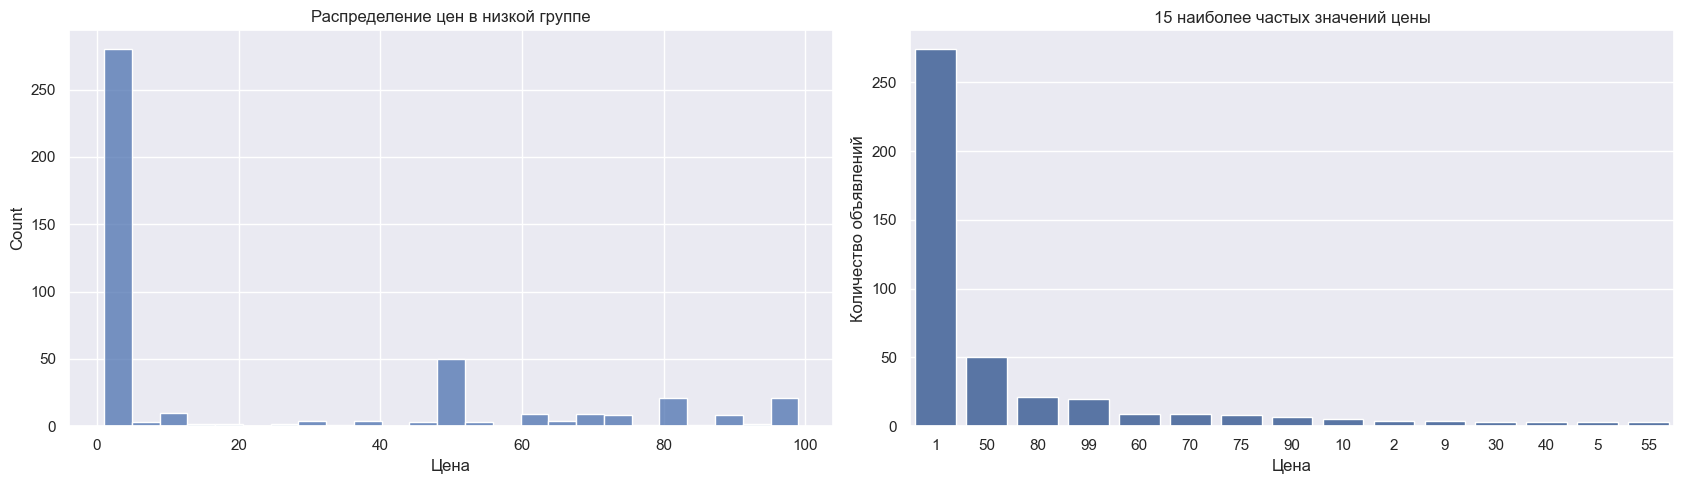

In [100]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5))
sns.histplot( data=extreme_low, x='price', bins=25, ax=axes[0] )

axes[0].set_title('Распределение цен в низкой группе')
axes[0].set_xlabel('Цена')
price_counts = ( extreme_low['price'] .value_counts() .head(15) .rename_axis('price') .reset_index(name='count') )


price_counts['price'] = price_counts['price'].astype(str)
sns.barplot( data=price_counts, x='price', y='count', ax=axes[1] )

axes[1].set_title('15 наиболее частых значений цены')
axes[1].set_xlabel('Цена')
axes[1].set_ylabel('Количество объявлений')

plt.tight_layout()
plt.show()

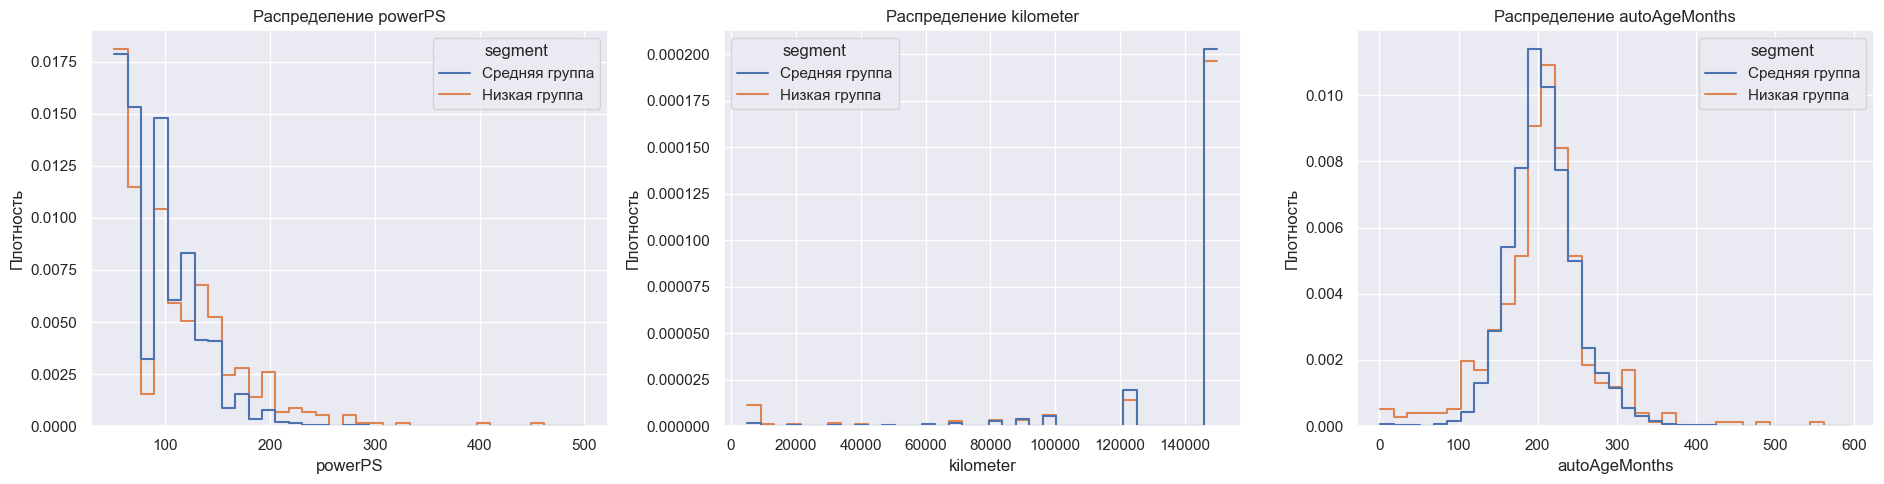

In [101]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

for ax, feature in zip(axes, numeric):
    sns.histplot( data=low_groups, x=feature, hue='segment', bins=35, stat='density', common_norm=False, element='step', fill=False, ax=ax )

    ax.set_title(f'Распределение {feature}')
    ax.set_ylabel('Плотность')

plt.tight_layout()
plt.show()

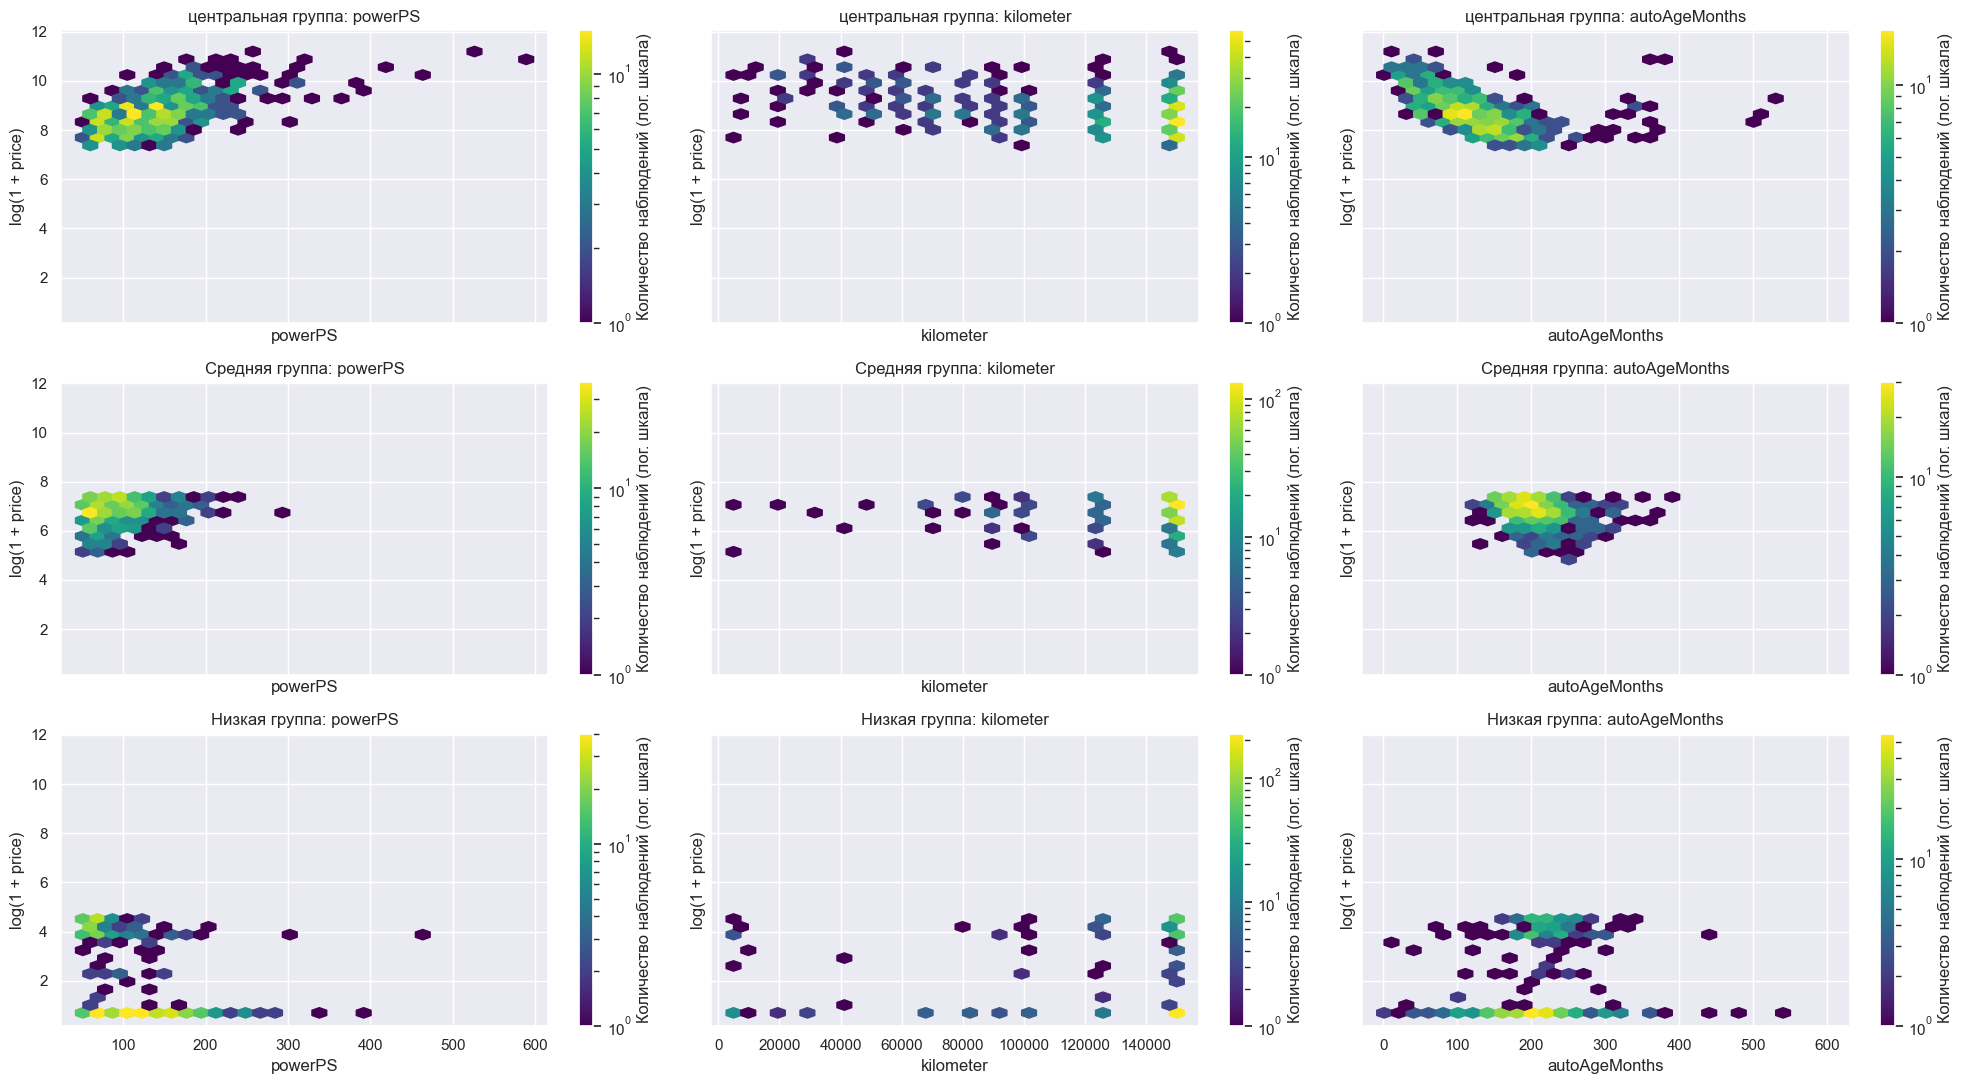

In [102]:
sample_size = min( len(medium_low), len(extreme_low) )
groups = [ ( 'центральная группа', central.sample( sample_size, random_state=42 ) ), ( 'Средняя группа', medium_low.sample( sample_size, random_state=42 ) ), ( 'Низкая группа', extreme_low.sample( sample_size, random_state=42 ) ) ]

y_min = segments['log_price'].min()
y_max = segments['log_price'].max()
fig, axes = plt.subplots( 3, 3, figsize=(20, 11), sharex='col', sharey=True )

for row, (group_name, group_data) in enumerate(groups):
    for column_number, feature in enumerate(numeric):
        ax = axes[row, column_number]
        hexbin = ax.hexbin( group_data[feature], group_data['log_price'], gridsize=30, mincnt=1, bins='log', cmap='viridis', extent=( segments[feature].min(), segments[feature].max(), y_min, y_max ) )

        ax.set_title(f'{group_name}: {feature}')
        ax.set_xlabel(feature)
        ax.set_ylabel('log(1 + price)')
        fig.colorbar( hexbin, ax=ax, label='Количество наблюдений (лог. шкала)' )

plt.tight_layout()
plt.show()

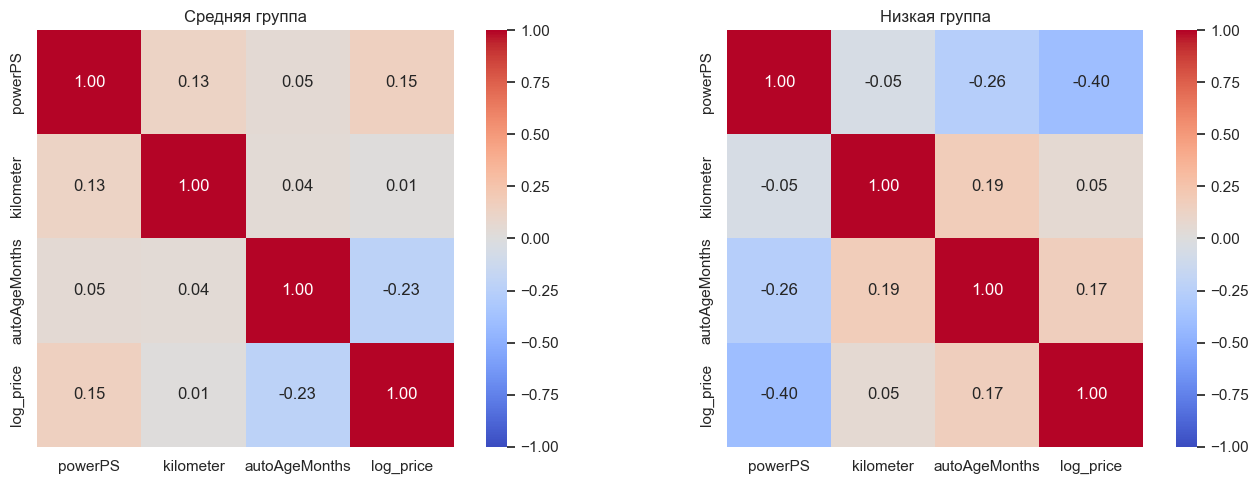

In [103]:
corr_cols = numeric + ['log_price']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
corr_groups = [ ('Средняя группа', medium_low), ('Низкая группа', extreme_low) ]
for ax, (group_name, group_data) in zip( axes, corr_groups ):
    correlation = group_data[ corr_cols ].corr(method='pearson')
    sns.heatmap( correlation, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1, square=True, ax=ax )

    ax.set_title(group_name)

plt.tight_layout()
plt.show()

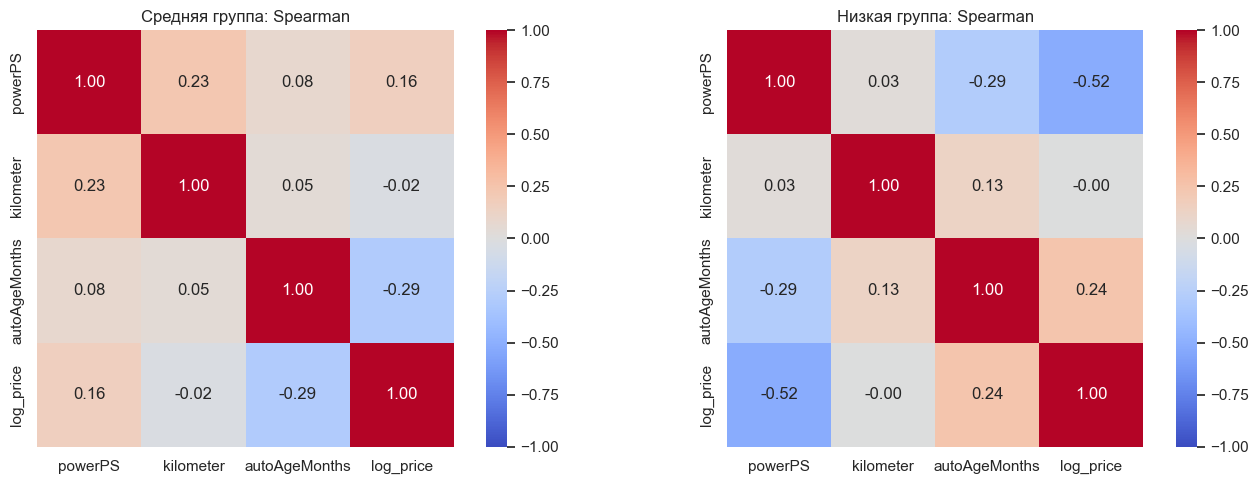

In [104]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (group_name, group_data) in zip( axes, corr_groups ):
    correlation = group_data[ corr_cols ].corr(method='spearman')
    sns.heatmap( correlation, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1, square=True, ax=ax )

    ax.set_title(f'{group_name}: Spearman')

plt.tight_layout()
plt.show()

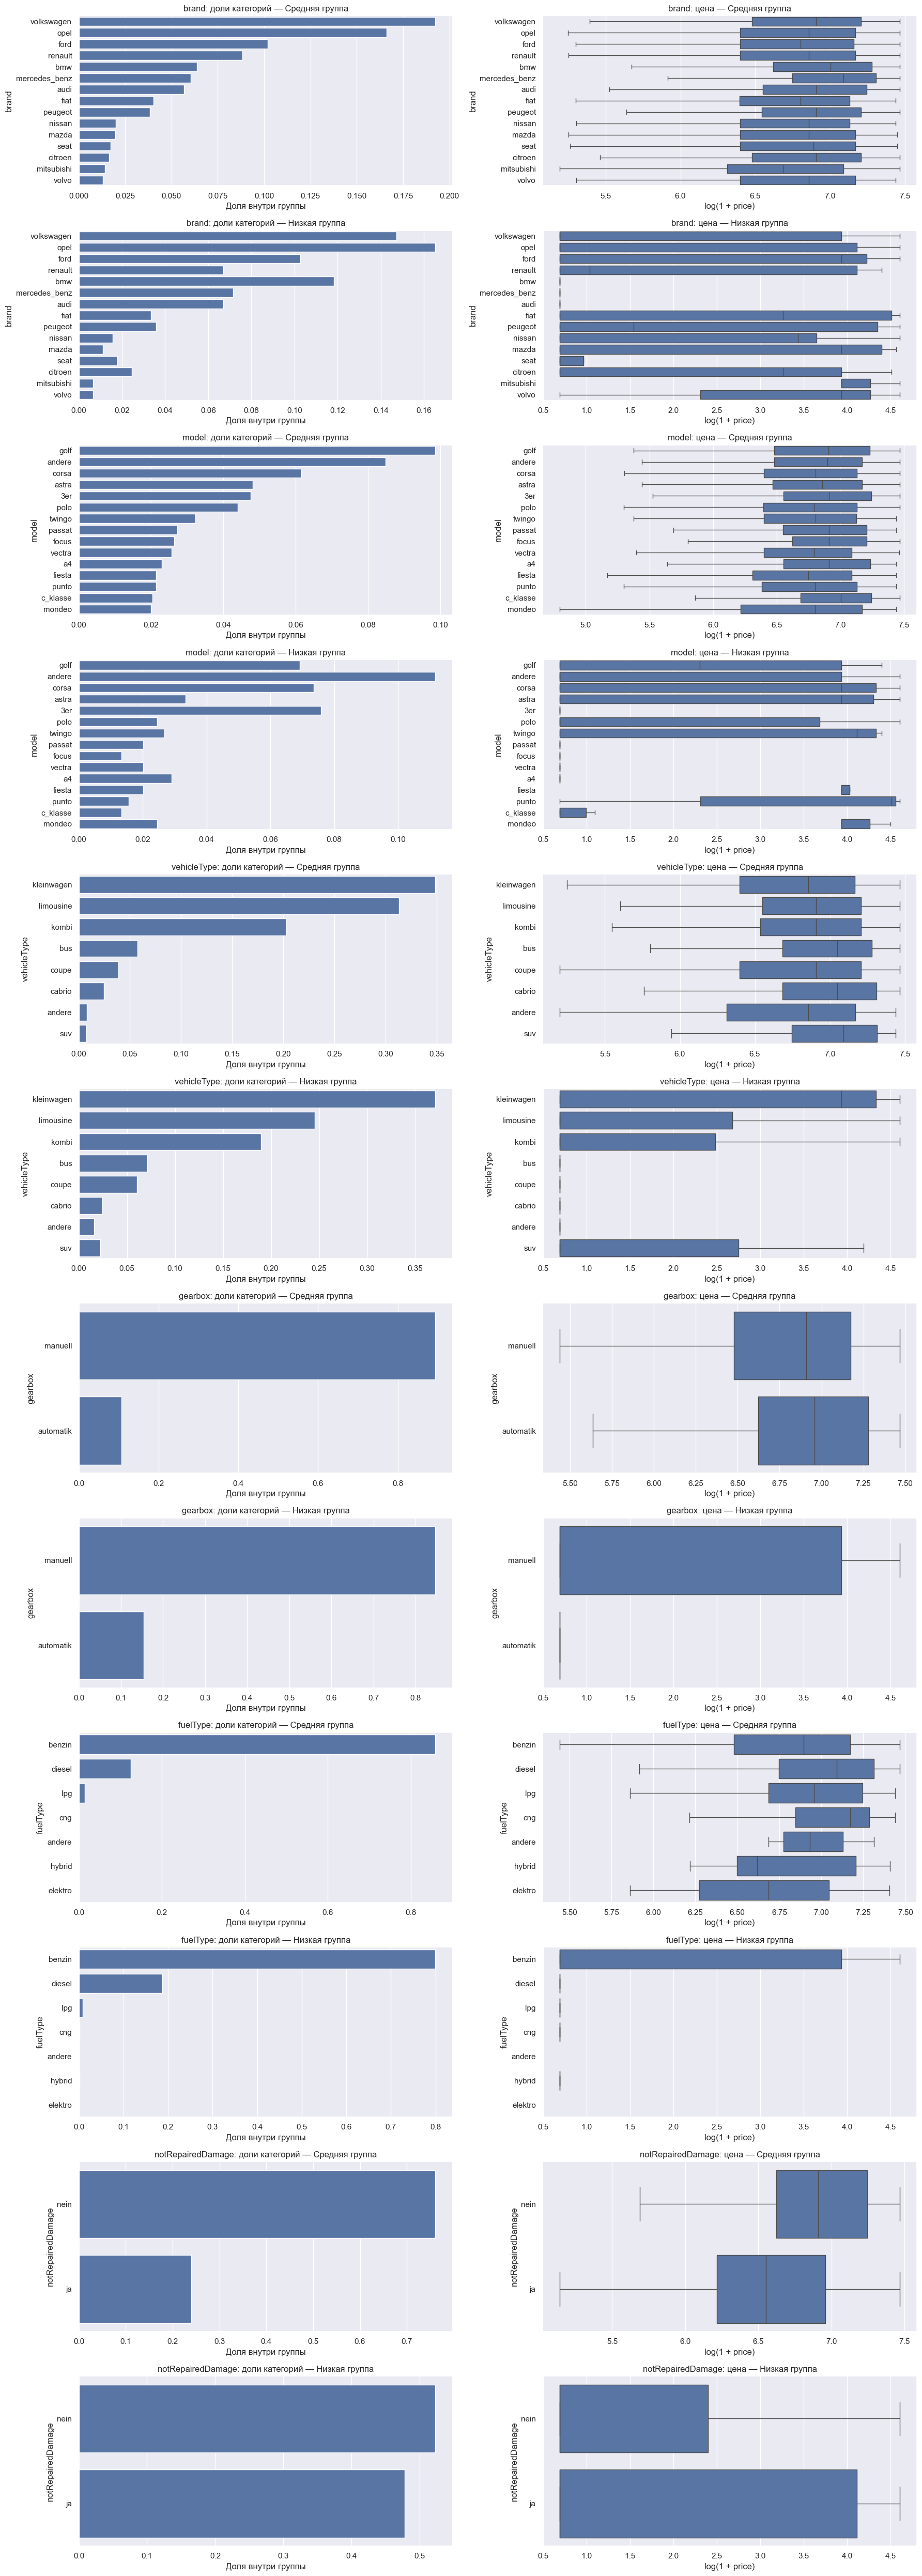

In [105]:
fig, axes = plt.subplots( len(categorical) * 2, 2, figsize=(18, 50) )
cat_groups = [ ('Средняя группа', medium_low), ('Низкая группа', extreme_low) ]

for feature_number, feature in enumerate(categorical):
    cat_order = ( low_groups[feature] .value_counts() .head(15) .index )
    for group_number, (group_name, group_data) in enumerate( cat_groups ):
        row = feature_number * 2 + group_number
        cat_shares = ( group_data[feature] .value_counts(normalize=True) .reindex(cat_order, fill_value=0) .rename_axis(feature) .reset_index(name='share') )
        sns.barplot( data=cat_shares, y=feature, x='share', order=cat_order, ax=axes[row, 0] )
        axes[row, 0].set_title( f'{feature}: доли категорий — {group_name}' )
        axes[row, 0].set_xlabel('Доля внутри группы')
        axes[row, 0].set_ylabel(feature)
        plot_data = group_data[ group_data[feature].isin(cat_order) ]
        sns.boxplot( data=plot_data, y=feature, x='log_price', order=cat_order, showfliers=False, ax=axes[row, 1] )
        axes[row, 1].set_title( f'{feature}: цена — {group_name}' )
        axes[row, 1].set_xlabel('log(1 + price)')
        axes[row, 1].set_ylabel(feature)

plt.tight_layout()
plt.show()

In [106]:
summary_groups = { 'Центральная группа': central, 'Средняя группа': medium_low, 'Низкая группа': extreme_low }

summary_rows = []

for group_name, group_data in summary_groups.items():
    summary_rows.append({ 'group': group_name, 'count': len(group_data), 'median_price': group_data['price'].median(), 'median_powerPS': group_data['powerPS'].median(), 'median_kilometer': group_data['kilometer'].median(), 'median_age': group_data['autoAgeMonths'].median(), 'damage_share': ( group_data['notRepairedDamage'] .eq('ja') .mean() ), 'price_1_share': ( group_data['price'] .eq(1) .mean() ) })
group_summary = pd.DataFrame( summary_rows ).set_index('group')

display(group_summary)

,count,median_price,median_powerPS,median_kilometer,median_age,damage_share,price_1_share
group,,,,,,,
Центральная группа,181858,6000.0,136.0,150000.0,117.0,0.050858,0.000000
Средняя группа,58884,999.0,90.0,150000.0,204.0,0.239692,0.000000
Низкая группа,448,1.0,101.0,150000.0,208.0,0.477679,0.611607


## Выводы:
1. РАспределение цены нижней группы является бимодальным, большая масса концентрируется у 1 и 100, количество "выбросов" в средней группе снизилось
2. Поведение нижней группы имеет странности, например, положительную связь с возрастом, но при этом около нулевую связь с пробегом - это может свидетельствовать о том, что либо ценяться старые автомобили, либо что есть какие-то искажения в данных. Сами значения внутри группы достаточно дискретные, большинство наблюден расположены при цене равной 1, что не характерно для торговли автомобилями (даже достаточно старые модели должны стоять дорого при такой положительной связи, но видно, что нет никакой тенденции в цене или непрерывного распределения по ценам внутри данной группы).
3. Достаточно мало наблюдений в нижней группе, из-за чего проблематично составить какие-нибудь гипотезы по поводу природы ценообразования в ней

Исходя из данных выводов, можно заключить, что не стоит рассматривать нижнюю группу, и её следует исключить из рассмотрения, как группу содержащие некорректные значения. При этом гипотеза о существовании групп с разной природой ценообразования следует оставить недоказанной.

In [107]:
data

,brand,model,vehicleType,gearbox,fuelType,notRepairedDamage,powerPS,kilometer,autoAgeMonths,price,brand_model,log_price
0,volkswagen,golf,kleinwagen,manuell,benzin,nein,75,150000,177,1500,volkswagen_golf,7.313887
1,skoda,fabia,kleinwagen,manuell,diesel,nein,69,90000,93,3600,skoda_fabia,8.188967
2,bmw,3er,limousine,manuell,benzin,ja,102,150000,246,650,bmw_3er,6.478510
3,peugeot,2_reihe,cabrio,manuell,benzin,nein,109,150000,140,2200,peugeot_2_reihe,7.696667
4,mazda,3_reihe,limousine,manuell,benzin,nein,105,150000,136,2000,mazda_3_reihe,7.601402
...,...,...,...,...,...,...,...,...,...,...,...,...
241185,volkswagen,golf,limousine,manuell,diesel,nein,140,150000,69,7900,volkswagen_golf,8.974745
241186,seat,leon,limousine,manuell,benzin,ja,225,150000,142,3200,seat_leon,8.071219
241187,smart,fortwo,cabrio,automatik,benzin,nein,101,125000,192,1199,smart_fortwo,7.090077
241188,volkswagen,transporter,bus,manuell,diesel,nein,102,150000,241,9200,volkswagen_transporter,9.127067


In [108]:
data = data[data['price'] >= 100].copy().reset_index(drop=True)

categorical = ['brand_model', 'vehicleType', 'gearbox', 'fuelType', 'notRepairedDamage']

data['bias'] = 1
other = ['bias']

x = data[categorical + numeric + other].copy()
y = data['log_price'].copy()

In [109]:
x

,brand_model,vehicleType,gearbox,fuelType,notRepairedDamage,powerPS,kilometer,autoAgeMonths,bias
0,volkswagen_golf,kleinwagen,manuell,benzin,nein,75,150000,177,1
1,skoda_fabia,kleinwagen,manuell,diesel,nein,69,90000,93,1
2,bmw_3er,limousine,manuell,benzin,ja,102,150000,246,1
3,peugeot_2_reihe,cabrio,manuell,benzin,nein,109,150000,140,1
4,mazda_3_reihe,limousine,manuell,benzin,nein,105,150000,136,1
...,...,...,...,...,...,...,...,...,...
240737,volkswagen_golf,limousine,manuell,diesel,nein,140,150000,69,1
240738,seat_leon,limousine,manuell,benzin,ja,225,150000,142,1
240739,smart_fortwo,cabrio,automatik,benzin,nein,101,125000,192,1
240740,volkswagen_transporter,bus,manuell,diesel,nein,102,150000,241,1


Теперь вам необходимо разбить данные на обучающую, тестовую и валидационную выборки.

In [110]:
from sklearn.model_selection import train_test_split
X_train, X_temp, y_train, y_temp = train_test_split( x, y, test_size=0.2, random_state=42, shuffle=True )
X_val, X_test, y_val, y_test = train_test_split( X_temp, y_temp, test_size=0.5, random_state=42, shuffle=True )


print('Train:')
print(f'  X_train: {X_train.shape}')
print(f'  y_train: {y_train.shape}')

print('\nValidation:')
print(f'  X_val:   {X_val.shape}')
print(f'  y_val:   {y_val.shape}')

print('\nTest:')
print(f'  X_test:  {X_test.shape}')
print(f'  y_test:  {y_test.shape}')

Train:
  X_train: (192593, 9)
  y_train: (192593,)

Validation:
  X_val:   (24074, 9)
  y_val:   (24074,)

Test:
  X_test:  (24075, 9)
  y_test:  (24075,)


А также сделаем базовую обработку данных, а именно:
* Применим `OneHotEncoding` к категориальным признакам
* Стандартизуем численные признаки с помощью `StandardScaler`
* Остальные признаки трогать не будем, т.к. с ними непонятно что делать

> А почему мы сначала делим данные, а только потом применяем обработку данных? Энкодеры и скейлеры используют информацию о данных: если сделать fit на всем датасете до split, это будет утечка: статистики из val/test попадут в обучение.

In [111]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
preprocessor = ColumnTransformer([ ('ohe', OneHotEncoder(handle_unknown='ignore'), categorical), ('scaling', StandardScaler(), numeric), ('other',  'passthrough', other) ])

X_train = preprocessor.fit_transform(X_train)
X_val = preprocessor.transform(X_val)
X_test = preprocessor.transform(X_test)

## Задание 5. Сравнение методов градиентного спуска (1.5 балла)

В этом задании вам предстоит сравнить методы градиентного спуска на подготовленных вами данных из предыдущего задания.

### Задание 5.1. Подбор оптимальной длины шага (0.75 балла)

Подберите по валидационной выборке наилучшую длину шага $\lambda$ для каждого метода с точки зрения ошибки. Для этого сделайте перебор по логарифмической сетке. Для каждого метода посчитайте ошибку на обучающей и тестовой выборках, посчитайте качество по метрике $R^2$, сохраните количество итераций до сходимости.

Все параметры кроме `lambda_` стоит выставить равным значениям по умолчанию.

In [112]:
from sklearn.metrics import mean_squared_error, r2_score

y_train_np = y_train.to_numpy()
y_val_np = y_val.to_numpy()
y_test_np = y_test.to_numpy()
methods = { 'Vanilla GD': VanillaGradientDescent, 'SGD': StochasticGradientDescent, 'SAG': SAGDescent, 'Momentum': MomentumDescent, 'Adam': Adam }
lambda_grid = np.logspace( -5, 0, 11 )

print(lambda_grid)

[1.00000000e-05 3.16227766e-05 1.00000000e-04 3.16227766e-04
 1.00000000e-03 3.16227766e-03 1.00000000e-02 3.16227766e-02
 1.00000000e-01 3.16227766e-01 1.00000000e+00]


In [113]:
search_rows = []

best_models = {}
best_lams = {}
best_val_mse = { method_name: np.inf for method_name in methods }


for method_name, opt_class in methods.items():
    print(f'\nМетод: {method_name}')

    for lam in lambda_grid:
        optimizer = opt_class( lr_schedule=TimeDecayLR( lambda_=float(lam) ) )
        model = CustomLinearRegression( optimizer=optimizer )



        np.random.seed(42)
        model.fit( X_train, y_train_np )

        val_pred = model.predict(X_val)

        if np.isfinite(val_pred).all():
            val_mse = mean_squared_error( y_val_np, val_pred )
        else:
            val_mse = np.inf
        search_rows.append({ 'Метод': method_name, 'lambda': lam, 'Validation MSE': val_mse, 'Количество итераций': optimizer.iteration })
        print( f'lambda={lam:.5g}, ' f'validation MSE={val_mse:.6f}, ' f'итераций={optimizer.iteration}' )

        if val_mse < best_val_mse[method_name]:
            best_val_mse[method_name] = val_mse
            best_lams[method_name] = lam
            best_models[method_name] = model


Метод: Vanilla GD
lambda=1e-05, validation MSE=69.617949, итераций=1
lambda=3.1623e-05, validation MSE=69.598954, итераций=1
lambda=0.0001, validation MSE=69.214543, итераций=9
lambda=0.00031623, validation MSE=65.110384, итераций=83
lambda=0.001, validation MSE=40.418245, итераций=503
lambda=0.0031623, validation MSE=7.966500, итераций=865
lambda=0.01, validation MSE=1.319058, итераций=485
lambda=0.031623, validation MSE=0.696316, итераций=279
lambda=0.1, validation MSE=0.422641, итераций=366
lambda=0.31623, validation MSE=0.339699, итераций=325
lambda=1, validation MSE=0.304666, итераций=474

Метод: SGD
lambda=1e-05, validation MSE=69.617795, итераций=1
lambda=3.1623e-05, validation MSE=69.598467, итераций=1
lambda=0.0001, validation MSE=69.185084, итераций=10
lambda=0.00031623, validation MSE=65.298850, итераций=76
lambda=0.001, validation MSE=40.648739, итераций=491
lambda=0.0031623, validation MSE=8.392509, итераций=814
lambda=0.01, validation MSE=1.484320, итераций=408
lambda=0.

In [114]:
search_df = pd.DataFrame(search_rows)
display( search_df .sort_values( ['Метод', 'Validation MSE'] ) .reset_index(drop=True) )


,Метод,lambda,Validation MSE,Количество итераций
0,Adam,1.000000,0.269063,212
1,Adam,0.316228,0.269086,453
2,Adam,0.100000,0.269554,1000
3,Adam,0.031623,0.684186,1000
4,Adam,0.010000,23.969715,1000
5,Adam,0.003162,51.458025,1000
6,Adam,0.001000,66.194187,313
7,Adam,0.000316,69.303836,32
8,Adam,0.000100,69.598099,4
9,Adam,0.000032,69.623483,1


In [115]:
mse_results = []

for method_name, model in best_models.items():
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)
    mse_results.append({ 'Метод': method_name, 'Лучшая lambda': best_lams[method_name], 'Train MSE': mean_squared_error( y_train_np, train_pred ), 'Test MSE': mean_squared_error( y_test_np, test_pred ), 'Train R2': r2_score( y_train_np, train_pred ), 'Test R2': r2_score( y_test_np, test_pred ), 'Количество итераций': model.optimizer.iteration })
mse_results = ( pd.DataFrame(mse_results) .sort_values('Test MSE') .reset_index(drop=True) )

display(mse_results)

,Метод,Лучшая lambda,Train MSE,Test MSE,Train R2,Test R2,Количество итераций
0,Adam,1.000000,0.266032,0.265219,0.787362,0.786465,212
1,Momentum,1.000000,0.271369,0.271196,0.783097,0.781652,931
2,Vanilla GD,1.000000,0.304958,0.304984,0.756249,0.754449,474
3,SGD,0.316228,0.327477,0.326670,0.738250,0.736989,1000
4,SAG,1.000000,2.754259,2.757731,-1.201464,-1.220328,1000


### Задание 5.2. Сравнение методов (0.75 балла)

Постройте график зависимости ошибки на обучающей выборке от номера итерации (все методы на одном графике).

Посмотрите на получившиеся результаты (таблички с метриками и график). Сравните методы между собой.

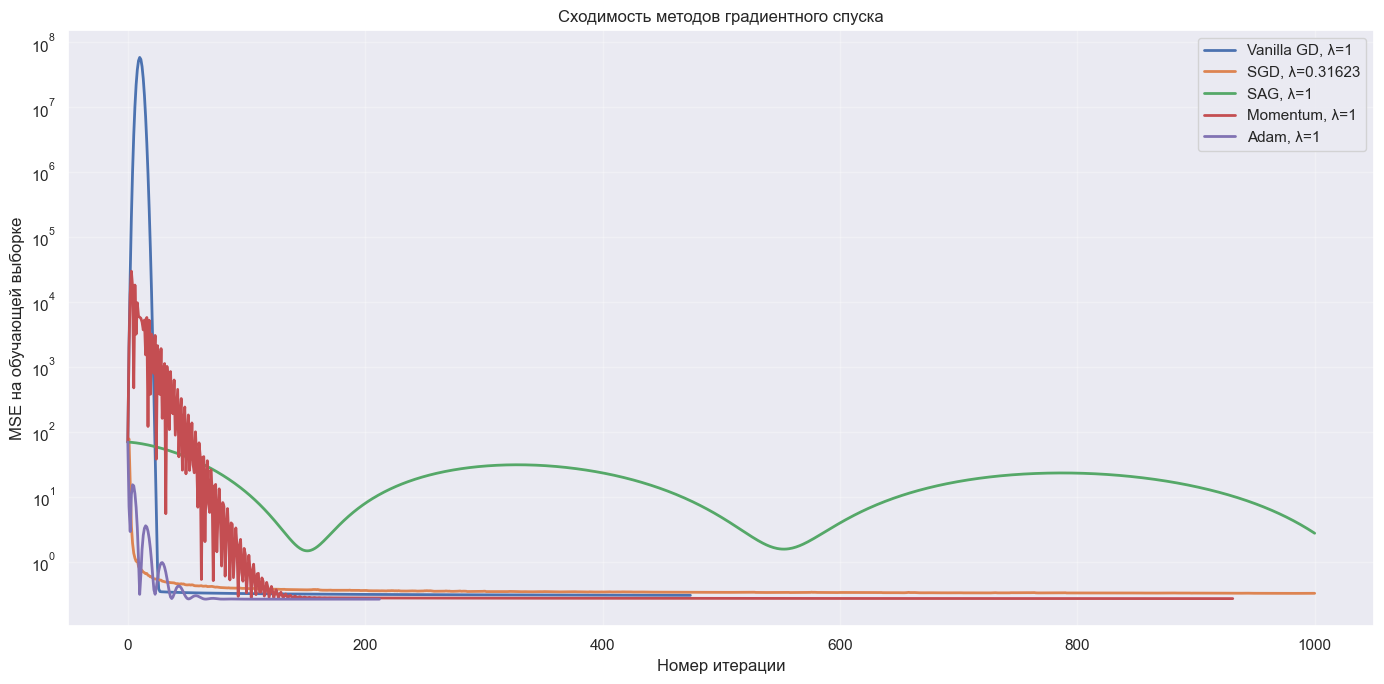

In [116]:
plt.figure(figsize=(14, 7))

for method_name, model in best_models.items():
    iterations = np.arange( len(model.loss_history) )
    plt.plot( iterations, model.loss_history, label=( f'{method_name}, ' f'λ={best_lams[method_name]:.5g}' ), linewidth=2 )

plt.xlabel('Номер итерации')
plt.ylabel('MSE на обучающей выборке')
plt.title('Сходимость методов градиентного спуска')

plt.yscale('log')

plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Выводы

1. Vanilla GD. В начале обучения MSE резко возрастает, после чего быстро снижается. Полный градиент вычисляется по всей выборке, поэтому резкий скачок связан с величиной начального шага: при большом шаге обновление весов может перенести модель в область с высокой ошибкой. По мере уменьшения шага алгоритм возвращается к области меньших значений MSE. На тестовой выборке он получил MSE = 0.305.

2. Momentum. На графике заметны колебания: накопленный вектор инерции продолжает влиять на движение даже после изменения направления градиента. Поэтому метод может проходить мимо области низкой ошибки и затем возвращаться к ней. Несмотря на колебания, общая тенденция - снижение MSE. Итоговая тестовая MSE = 0.271.

3. SAG. Ошибка снижается неустойчиво и остаётся значительно выше, чем у других методов. SAG обновляет среднее по памяти индивидуальных градиентов, но за ограниченное число итераций и при используемом размере батча эта память может недостаточно полно отражать текущие градиенты всей выборки. Метод достиг max_iter, а его тестовая MSE составила = 2.758. Вероятная причина - размер батча, выставленая по умолчанию.

4. SGD. Ошибка в целом убывает, но траектория содержит колебания, поскольку на каждом шаге градиент оценивается по случайному батчу. Метод дошёл до max_iter=1000 и показал тестовую MSE = 0.327 - выше, чем у Vanilla GD, Momentum и Adam.

5. Adam. В начале также видны колебания, но ошибка быстро снижается и стабилизируется на наиболее низком уровне среди исследованных методов. Adam использует оценки первого и второго моментов градиента, подстраивая масштаб обновления отдельно для каждого веса. В этом эксперименте он достиг критерия остановки за 212 итераций и получил наименьшую тестовую MSE = 0.265.

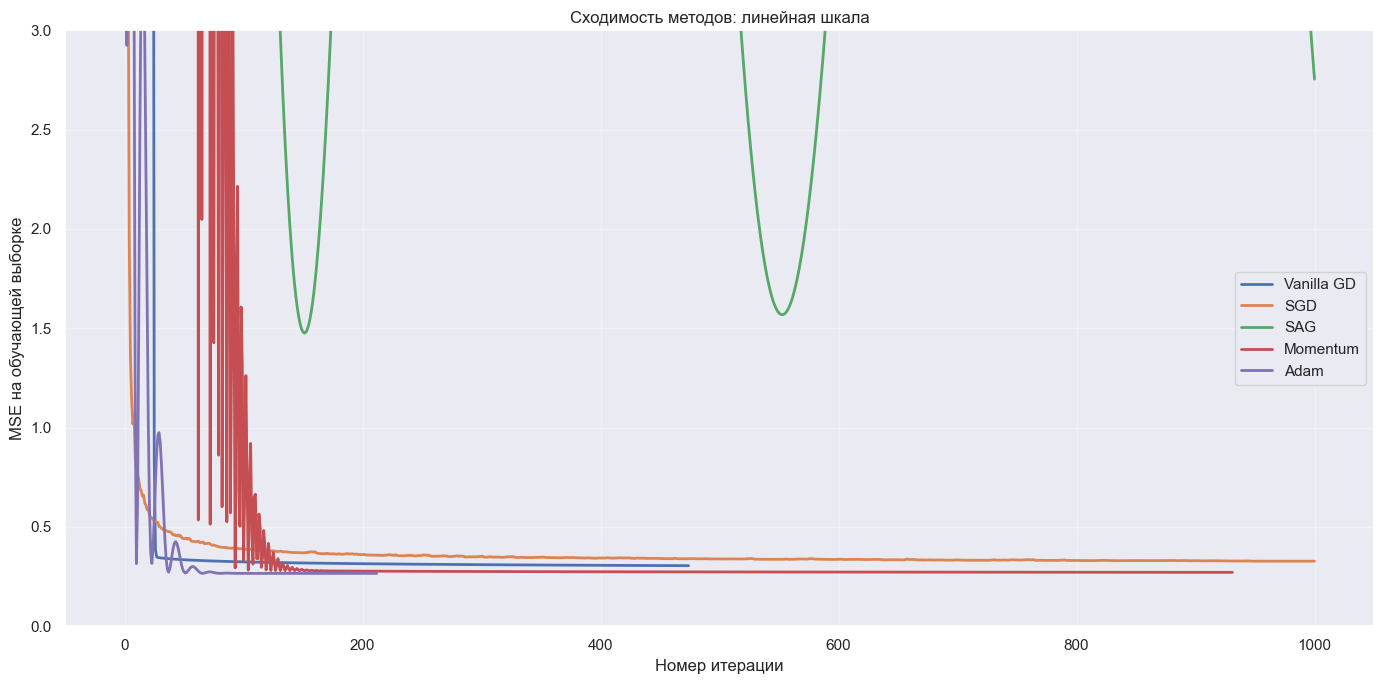

In [117]:
plt.figure(figsize=(14, 7))

for method_name, model in best_models.items():
    plt.plot( model.loss_history, label=method_name, linewidth=2 )

plt.xlabel('Номер итерации')
plt.ylabel('MSE на обучающей выборке')
plt.title('Сходимость методов: линейная шкала')

plt.ylim(0, 3)

plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Задание 6. Стохастический градиентный спуск и размер батча (1 балл)

В этом задании вам предстоит исследовать влияние размера батча на работу стохастического градиентного спуска.

* Сделайте по несколько запусков (например, $k = 10$) стохастического градиентного спуска на обучающей выборке для каждого размера батча из перебираемого списка. Замерьте время в секундах и количество итераций до сходимости. Посчитайте среднее этих значений для каждого размера батча.
* Постройте график зависимости количества шагов до сходимости от размера батча. _(под сходимостью понимается достижение критерия останова)_
* Постройте график зависимости времени до сходимости от размера батча.

Посмотрите на получившиеся результаты. Какие выводы можно сделать про подбор размера батча для стохастического градиентного спуска?

In [118]:
sgd_lam = best_lams['SGD']

print('Лучшая lambda для SGD:', sgd_lam)

from time import perf_counter
batch_sizes = [ 1, 8, 32, 128, 512, 2048, 4096, 8192, 10000, 20000, 40000]

runs_count = 10

batch_rows = []


for batch_size in batch_sizes:
    run_times = []
    run_iters = []
    stopped_early = []

    print(f'\nРазмер батча: {batch_size}')

    for run_number in range(runs_count):
        optimizer = StochasticGradientDescent( lr_schedule=TimeDecayLR( lambda_=sgd_lam ), batch_size=batch_size )
        model = CustomLinearRegression( optimizer=optimizer )



        np.random.seed(42 + run_number)

        start_time = perf_counter()
        model.fit( X_train, y_train_np )

        duration = perf_counter() - start_time

        run_times.append(duration)
        run_iters.append(optimizer.iteration)
        stopped_early.append( optimizer.iteration < optimizer.max_iter )
        print( f'Запуск {run_number + 1}: ' f'{optimizer.iteration} итераций, ' f'{duration:.3f} сек.' )
    batch_rows.append({ 'Размер батча': batch_size, 'Среднее число итераций': np.mean(run_iters), 'Стандартное отклонение итераций': np.std(run_iters), 'Среднее время, сек.': np.mean(run_times), 'Стандартное отклонение времени': np.std(run_times), 'Доля запусков с достижением критерия': np.mean(stopped_early) })


Лучшая lambda для SGD: 0.31622776601683794

Размер батча: 1
Запуск 1: 351 итераций, 1.523 сек.
Запуск 2: 292 итераций, 1.310 сек.
Запуск 3: 52 итераций, 0.232 сек.
Запуск 4: 307 итераций, 1.346 сек.
Запуск 5: 371 итераций, 1.628 сек.
Запуск 6: 271 итераций, 1.169 сек.
Запуск 7: 343 итераций, 1.472 сек.
Запуск 8: 385 итераций, 1.694 сек.
Запуск 9: 299 итераций, 1.350 сек.
Запуск 10: 389 итераций, 1.781 сек.

Размер батча: 8
Запуск 1: 1000 итераций, 4.572 сек.
Запуск 2: 1000 итераций, 4.507 сек.
Запуск 3: 1000 итераций, 4.491 сек.
Запуск 4: 1000 итераций, 4.462 сек.
Запуск 5: 1000 итераций, 4.263 сек.
Запуск 6: 1000 итераций, 4.277 сек.
Запуск 7: 1000 итераций, 4.292 сек.
Запуск 8: 1000 итераций, 4.237 сек.
Запуск 9: 1000 итераций, 4.273 сек.
Запуск 10: 1000 итераций, 4.391 сек.

Размер батча: 32
Запуск 1: 1000 итераций, 4.271 сек.
Запуск 2: 1000 итераций, 4.377 сек.
Запуск 3: 1000 итераций, 4.337 сек.
Запуск 4: 1000 итераций, 4.286 сек.
Запуск 5: 1000 итераций, 4.284 сек.
Запуск 6: 1000

In [119]:
batch_stats = pd.DataFrame( batch_rows )

display(batch_stats)

,Размер батча,Среднее число итераций,Стандартное отклонение итераций,"Среднее время, сек.",Стандартное отклонение времени,Доля запусков с достижением критерия
0,1,306.0,93.132164,1.350595,0.413538,1.0
1,8,1000.0,0.000000,4.376484,0.116530,0.0
2,32,1000.0,0.000000,4.264456,0.062845,0.0
3,128,1000.0,0.000000,4.307296,0.045484,0.0
4,512,830.7,91.945690,3.673746,0.428152,0.9
5,2048,431.1,31.731530,2.096210,0.177846,1.0
6,4096,378.3,15.900000,1.985182,0.081895,1.0
7,8192,349.6,12.289833,2.186842,0.075804,1.0
8,10000,347.4,10.131140,2.309765,0.088267,1.0
9,20000,336.9,10.231813,3.093029,0.115725,1.0


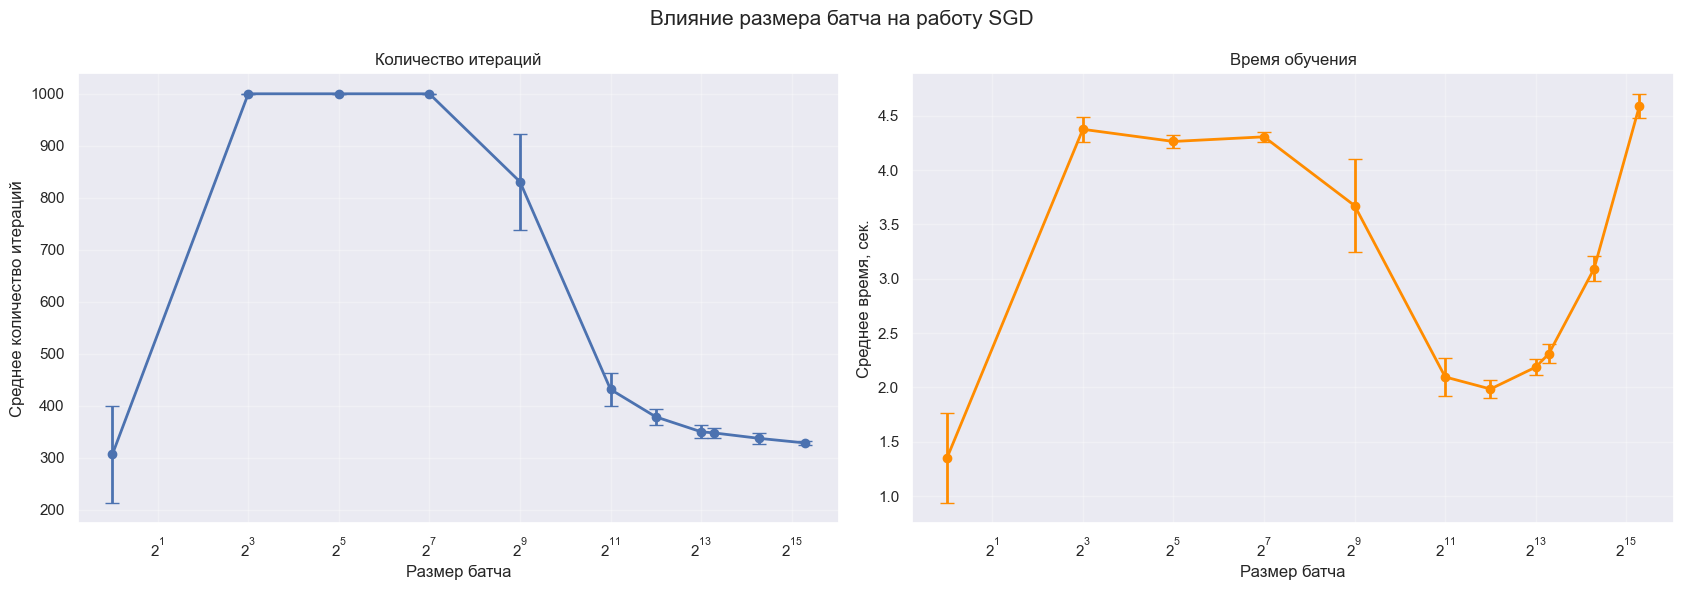

In [120]:
fig, axes = plt.subplots( 1, 2, figsize=(17, 6) )
axes[0].errorbar( batch_stats['Размер батча'], batch_stats['Среднее число итераций'], yerr=batch_stats[ 'Стандартное отклонение итераций' ], marker='o', capsize=5, linewidth=2 )

axes[0].set_xscale('log', base=2)
axes[0].set_xlabel('Размер батча')
axes[0].set_ylabel('Среднее количество итераций')
axes[0].set_title('Количество итераций')
axes[0].grid(True, alpha=0.3)
axes[1].errorbar( batch_stats['Размер батча'], batch_stats['Среднее время, сек.'], yerr=batch_stats[ 'Стандартное отклонение времени' ], marker='o', capsize=5, linewidth=2, color='darkorange' )

axes[1].set_xscale('log', base=2)
axes[1].set_xlabel('Размер батча')
axes[1].set_ylabel('Среднее время, сек.')
axes[1].set_title('Время обучения')
axes[1].grid(True, alpha=0.3)
fig.suptitle( 'Влияние размера батча на работу SGD', fontsize=15 )

plt.tight_layout()
plt.show()

**Выводы:**
Наблюдается неленейная зависимости количества итераций и времени обучения от размера батча. Видно, что при значениях 8, 32, 128 алгоритм достигает max_iter во всем прогонах, из-за чего std = 0. Далее при увеличении размера батча наблюдается уменьшение как количества итераций так и времени. Плато достигается примерно на размере батча в 8000, вместе с этим разброс по количеству итераций также уменьшается. Однако для времени после 8000 примеров в батче происходит дальнейший рост, связанные с вычислением градиента на каждой итерации. Из-за чего можно заключить, что при данном выбранной в предыдущем части первоначальном шаге оптимальное по времени и по количеству итераций является размер батча в 8000.

## Задание 7. Регуляризация (0.5 балла)

В этом задании вам предстоит исследовать влияние регуляризации на работу различных методов градиентного спуска. Напомним, регуляризация – это добавка к функции потерь, которая штрафует за норму весов. Мы будем использовать $L_2$-регуляризацию, таким образом функция потерь приобретает следующий вид:

$$
    Q(w) = \dfrac{1}{\ell} \sum\limits_{i=1}^{\ell} (a_w(x_i) - y_i)^2 + \dfrac{\mu}{2} \| w \|^2
$$

Допишите класс `linear_regression.L2Regularization`, следуя интерфейсу и докуметации.

Используя регуляризованный лосс в эксприментах, найдите лучшие параметры обучения с регуляризацией аналогично 5 заданию. Будем подбирать длину шага $\lambda$ (`lambda_`) и коэффициент регуляризации $\mu$ (`mu`).

Сравните для каждого метода результаты с регуляризацией и без регуляризации (нужно опять сохранить ошибку и качество по метрике $R^2$ на обучающей и тестовой выборках и количество итераций до сходимости).

Постройте для каждого метода график со значениями функции потерь MSE с регуляризацией и без регуляризации (всего должно получиться 5 графиков).

Посмотрите на получившиеся результаты. Какие можно сделать выводы, как регуляризация влияет на сходимость? Как изменилось качество на обучающей выборке? На тестовой? Чем вы можете объяснить это?

In [121]:
from linear_regression import ( MSELoss, L2Regularization, CustomLinearRegression )
reg_lam_grid = np.logspace( -3, 0, 7 )
mu_grid = np.logspace( -5, -1, 5 )

print('lambda:', reg_lam_grid)
print('mu:', mu_grid)

lambda: [0.001      0.00316228 0.01       0.03162278 0.1        0.31622777
 1.        ]
mu: [1.e-05 1.e-04 1.e-03 1.e-02 1.e-01]


In [122]:
reg_search_rows = []

best_reg_models = {}
best_reg_params = {}
best_reg_val_mse = { method_name: np.inf for method_name in methods }


for method_name, opt_class in methods.items():
    print(f'\nМетод: {method_name}')

    for mu in mu_grid:
        for lam in reg_lam_grid:
            optimizer = opt_class( lr_schedule=TimeDecayLR( lambda_=float(lam) ) )
            regularized_loss = L2Regularization( core_loss=MSELoss(), mu_rate=float(mu) )
            model = CustomLinearRegression( optimizer=optimizer, loss_function=regularized_loss )

            np.random.seed(42)
            model.fit( X_train, y_train_np )
            val_pred = model.predict( X_val )

            if np.isfinite(val_pred).all():
                val_mse = mean_squared_error( y_val_np, val_pred )
            else:
                val_mse = np.inf
            reg_search_rows.append({ 'Метод': method_name, 'lambda': lam, 'mu': mu, 'Validation MSE': val_mse, 'Количество итераций': optimizer.iteration })
            if ( val_mse < best_reg_val_mse[method_name] ):
                best_reg_val_mse[ method_name ] = val_mse
                best_reg_params[method_name] = { 'lambda': lam, 'mu': mu }
                best_reg_models[ method_name ] = model
    print( 'Лучшие параметры:', best_reg_params[method_name], '\nValidation MSE:', best_reg_val_mse[method_name] )



Метод: Vanilla GD
Лучшие параметры: {'lambda': np.float64(1.0), 'mu': np.float64(1e-05)} 
Validation MSE: 0.3046715297228783

Метод: SGD
Лучшие параметры: {'lambda': np.float64(0.31622776601683794), 'mu': np.float64(1e-05)} 
Validation MSE: 0.3271794071535445

Метод: SAG
Лучшие параметры: {'lambda': np.float64(1.0), 'mu': np.float64(0.1)} 
Validation MSE: 2.294728014392252

Метод: Momentum
Лучшие параметры: {'lambda': np.float64(1.0), 'mu': np.float64(1e-05)} 
Validation MSE: 0.27211088041053105

Метод: Adam
Лучшие параметры: {'lambda': np.float64(1.0), 'mu': np.float64(1e-05)} 
Validation MSE: 0.2690864546812411


In [123]:
reg_results = []

for method_name, model in best_reg_models.items():
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)
    reg_results.append({ 'Метод': method_name, 'Лучшая lambda': best_reg_params[ method_name ]['lambda'], 'mu': best_reg_params[ method_name ]['mu'], 'Train MSE': mean_squared_error( y_train_np, train_pred ), 'Test MSE': mean_squared_error( y_test_np, test_pred ), 'Train R2': r2_score( y_train_np, train_pred ), 'Test R2': r2_score( y_test_np, test_pred ), 'Количество итераций': model.optimizer.iteration })
reg_results = ( pd.DataFrame(reg_results) .sort_values('Test MSE') .reset_index(drop=True) )



In [124]:
plain_results = mse_results.copy()
plain_results['Вариант'] = ( 'Без регуляризации' )

plain_results['mu'] = 0.0
l2_results = ( reg_results.copy() )
l2_results['Вариант'] = ( 'С L2-регуляризацией' )
cmp_cols = [ 'Метод', 'Вариант', 'Лучшая lambda', 'mu', 'Train MSE', 'Test MSE', 'Train R2', 'Test R2', 'Количество итераций' ]
reg_comparison = pd.concat( [ plain_results[cmp_cols], l2_results[cmp_cols] ], ignore_index=True )
reg_comparison = ( reg_comparison .sort_values(['Метод', 'Вариант']) .reset_index(drop=True) )

display(reg_comparison)

,Метод,Вариант,Лучшая lambda,mu,Train MSE,Test MSE,Train R2,Test R2,Количество итераций
0,Adam,Без регуляризации,1.000000,0.00000,0.266032,0.265219,0.787362,0.786465,212
1,Adam,С L2-регуляризацией,1.000000,0.00001,0.266115,0.265288,0.787296,0.786409,1000
2,Momentum,Без регуляризации,1.000000,0.00000,0.271369,0.271196,0.783097,0.781652,931
3,Momentum,С L2-регуляризацией,1.000000,0.00001,0.271411,0.271240,0.783063,0.781617,925
4,SAG,Без регуляризации,1.000000,0.00000,2.754259,2.757731,-1.201464,-1.220328,1000
5,SAG,С L2-регуляризацией,1.000000,0.10000,2.318586,2.316830,-0.853233,-0.865346,1000
6,SGD,Без регуляризации,0.316228,0.00000,0.327477,0.326670,0.738250,0.736989,1000
7,SGD,С L2-регуляризацией,0.316228,0.00001,0.327478,0.326671,0.738249,0.736988,1000
8,Vanilla GD,Без регуляризации,1.000000,0.00000,0.304958,0.304984,0.756249,0.754449,474
9,Vanilla GD,С L2-регуляризацией,1.000000,0.00001,0.304964,0.304990,0.756244,0.754444,474


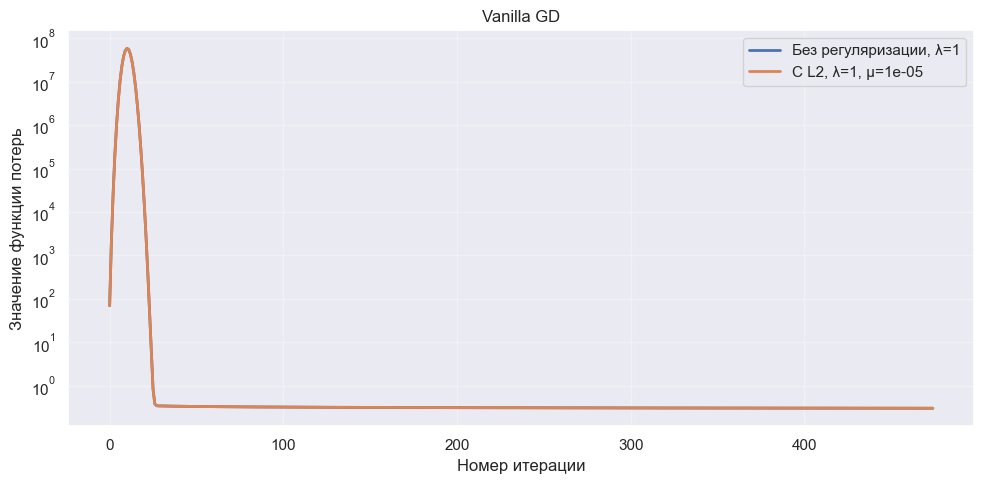

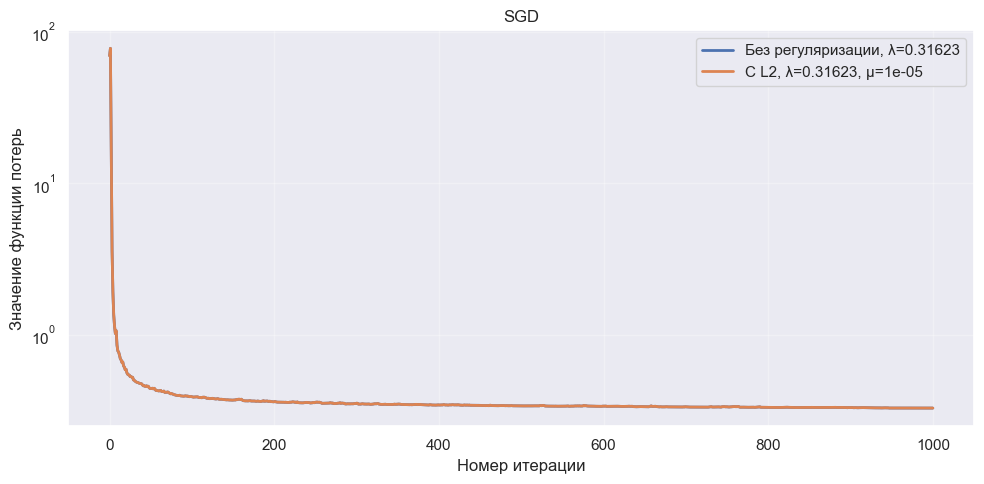

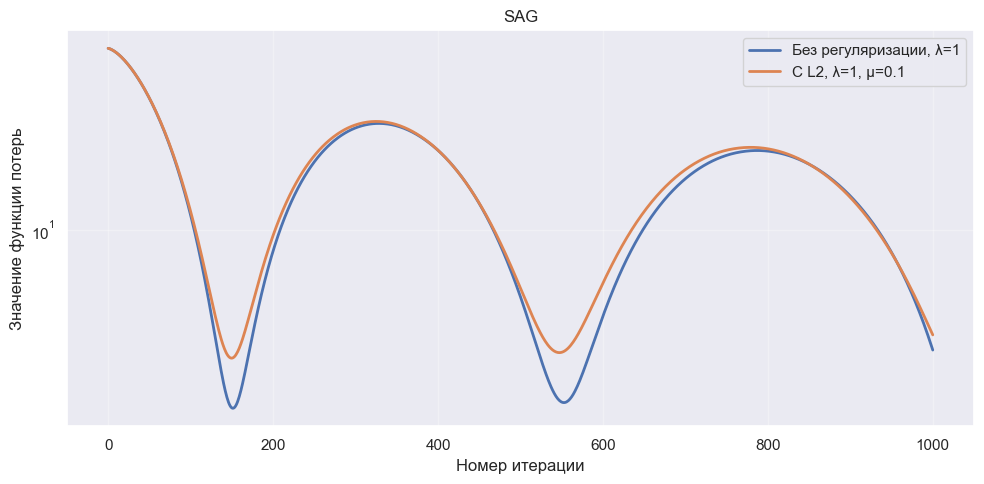

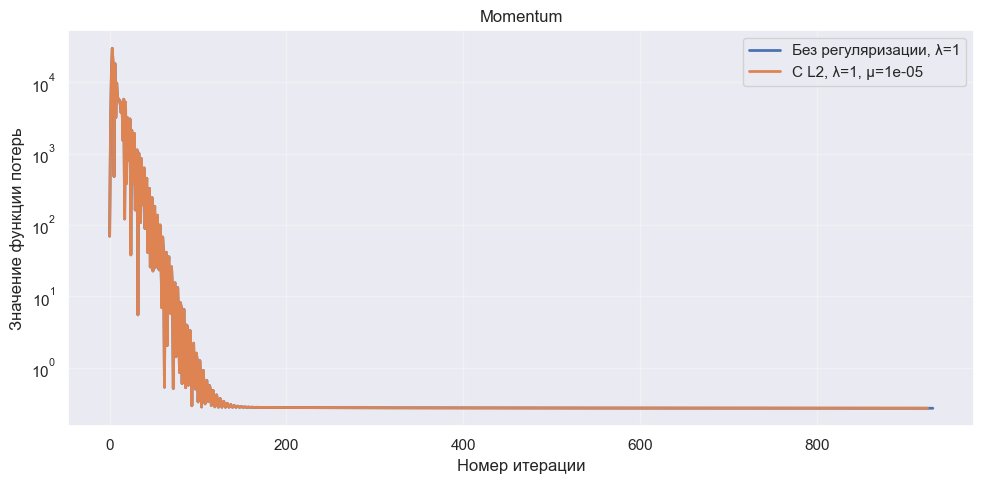

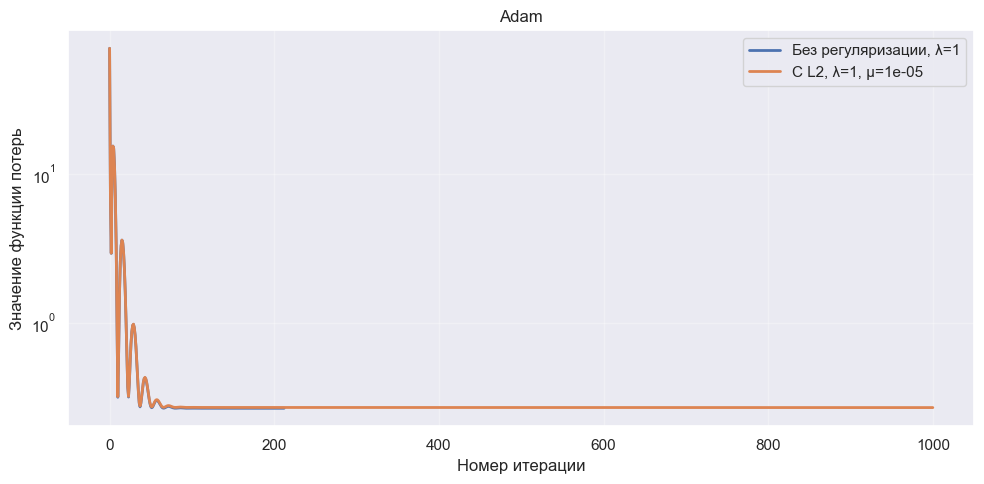

In [125]:
for method_name in methods:
    plain_model = best_models[method_name]
    l2_model = best_reg_models[ method_name ]

    plt.figure(figsize=(10, 5))
    plt.plot( plain_model.loss_history, label=( 'Без регуляризации, ' f'λ={best_lams[method_name]:.5g}' ), linewidth=2 )
    plt.plot( l2_model.loss_history, label=( 'С L2, ' f'λ={best_reg_params[method_name]["lambda"]:.5g}, ' f'μ={best_reg_params[method_name]["mu"]:.5g}' ), linewidth=2 )

    plt.xlabel('Номер итерации')
    plt.ylabel('Значение функции потерь')
    plt.title(method_name)

    plt.yscale('log')
    plt.grid(True, alpha=0.3)
    plt.legend()

    plt.tight_layout()
    plt.show()

In [126]:
norm_rows = []

for method_name in methods:
    norm_rows.append({ 'Метод': method_name, 'Норма без L2': np.linalg.norm( best_models[method_name].w ), 'Норма с L2': np.linalg.norm( best_reg_models[method_name].w ) })

display(pd.DataFrame(norm_rows))

,Метод,Норма без L2,Норма с L2
0,Vanilla GD,5.348019,5.347906
1,SGD,5.291425,5.291346
2,SAG,4.305271,4.292282
3,Momentum,6.864042,6.855773
4,Adam,26.250631,23.290790


**Вывод:**
Для Vanilla GD, SGD, Momentum и Adam тестовые MSE и $R^2$ почти не изменились по сравнению с моделями без регуляризации. Например, у Adam на тесте MSE изменилась с 0.265219 до 0.265288, у Momentum — с 0.271196 до 0.271240. Следовательно, в исследованной сетке L2 не дала заметного улучшения обобщения для этих методов.

Для SAG MSE на тесте снизилось с 2.7 до 2.3, но $R^2$ остался отрицательным -0.86, и оба запуска достигли max_iter=1000. Поэтому это улучшение нельзя считать решением проблемы сходимости SAG.

L2 добавляет к функции потерь штраф и стремится уменьшить норму весов. В эксперименте нормы изменились слабо у большинства методов. Наиболее заметно — у Adam (с 26.25 до 23.29). По числу итераций общего ускорения не видно: регуляризованный Adam дошёл до max_iter, тогда как вариант без L2 остановился за 212 итераций

## Задание 8. Альтернативные функции потерь (1 балл)

В этом задании вам предстоит использовать другую функцию потерь для нашей задачи регрессии. В качестве функции потерь мы выбрали **LogCosh** и **HuberLoss**:

$$
    L(y, a)
    =
    \log\left(\cosh(a - y)\right).
$$

$$
L_{\text{Huber}}(y, a) = \frac{1}{n} \sum_{i=1}^{n}
\begin{cases}
   \frac{1}{2} (a_i - y_i)^2, & \text{если } |a_i - y_i| < \delta, \\
   \delta \cdot |a_i - y_i| - \frac{1}{2} \delta^2, & \text{если } |a_i - y_i| \geq \delta,
\end{cases}
$$

Самостоятельно продифференцируйте данные функции потерь чтобы найти их градиенты _(требуется показать не только результат, но и промежуточные вычисления)_:

**Решение:**

Обозначим $r_i=x_i^Tw-y_i$. Тогда $\nabla_w r_i=x_i$.

Для LogCosh:
$$
Q(w)=\frac1\ell\sum_{i=1}^{\ell}\log\cosh(r_i).
$$
По правилу дифференцирования сложной функции
$$
\frac{d}{dr}\log\cosh(r)
=\frac{\sinh(r)}{\cosh(r)}
=\tanh(r).
$$
Следовательно,
$$
\nabla_w Q(w)
=\frac1\ell\sum_{i=1}^{\ell}\tanh(r_i)x_i
=\frac1\ell X^T\tanh(Xw-y),
$$
где $\tanh$ применяется поэлементно.

Для функции Хьюбера
$$
h_\delta(r)=
\begin{cases}
\frac12r^2,& |r|<\delta,\\
\delta|r|-\frac12\delta^2,& |r|\geq\delta.
\end{cases}
$$
В первой области производная равна $r$. Во второй используем
$\frac{d}{dr}|r|=\operatorname{sign}(r)$ при $r\ne0$ и получаем
$\delta\operatorname{sign}(r)$. На границах $r=\pm\delta$ значения
производных совпадают. Поэтому
$$
h_\delta'(r)=
\begin{cases}
r,& |r|<\delta,\\
\delta\operatorname{sign}(r),& |r|\geq\delta,
\end{cases}
$$
и
$$
\nabla_w Q(w)=\frac1\ell X^T  h_\delta'(Xw-y),
$$

Программно реализуйте функции потерь и их градиенты для LogCosh и HuberLoss в файле `linear_regression.py`. После этого обучите все пять методов градиентного спуска (без регуляризации) с этими лоссами аналогично заданию 5 и сравните качество с результатами из задания 5, где использовался MSE.

Имплементировать эти функции потерь необходимо при помощи наследования от `linear_regression.LossFunction` и имплементирования всех абстрактных методов. Аналитическое решение для этих функций выводить и имплементировать не требуется.



In [127]:
from linear_regression import ( LogCoshLoss, HuberLoss )
alt_losses = { 'LogCosh': lambda: LogCoshLoss(), 'Huber': lambda: HuberLoss(delta=1.0) }
alt_lam_grid = np.logspace( -4, 2, 13 )

print(alt_lam_grid)

[1.00000000e-04 3.16227766e-04 1.00000000e-03 3.16227766e-03
 1.00000000e-02 3.16227766e-02 1.00000000e-01 3.16227766e-01
 1.00000000e+00 3.16227766e+00 1.00000000e+01 3.16227766e+01
 1.00000000e+02]


In [128]:
alt_search_rows = []

best_alt_models = {}
best_alt_lams = {}
best_alt_val_loss = {}


for loss_name, make_loss in alt_losses.items():
    print(f'\nФункция потерь: {loss_name}')

    for method_name, opt_class in methods.items():
        key = (loss_name, method_name)

        best_alt_val_loss[key] = np.inf

        print(f'\nМетод: {method_name}')

        for lam in alt_lam_grid:
            optimizer = opt_class( lr_schedule=TimeDecayLR( lambda_=float(lam) ) )

            loss_function = make_loss()
            model = CustomLinearRegression( optimizer=optimizer, loss_function=loss_function )

            np.random.seed(42)
            model.fit( X_train, y_train_np )
            val_pred = model.predict( X_val )

            if np.isfinite(val_pred).all():
                val_loss = loss_function.loss( X_val, y_val_np, model.w )
                val_mse = mean_squared_error( y_val_np, val_pred )
            else:
                val_loss = np.inf
                val_mse = np.inf
            alt_search_rows.append({ 'Функция потерь': loss_name, 'Метод': method_name, 'lambda': lam, 'Validation loss': val_loss, 'Validation MSE': val_mse, 'Количество итераций': optimizer.iteration })
            print( f'lambda={lam:.5g}, ' f'validation loss={val_loss:.6f}, ' f'validation MSE={val_mse:.6f}, ' f'итераций={optimizer.iteration}' )
            if ( val_loss < best_alt_val_loss[key] ):
                best_alt_val_loss[ key ] = val_loss
                best_alt_lams[ key ] = lam
                best_alt_models[ key ] = model



Функция потерь: LogCosh

Метод: Vanilla GD
lambda=0.0001, validation loss=7.574456, validation MSE=69.621448, итераций=1
lambda=0.00031623, validation loss=7.573763, validation MSE=69.610016, итераций=1
lambda=0.001, validation loss=7.565852, validation MSE=69.479591, итераций=4
lambda=0.0031623, validation loss=7.472255, validation MSE=67.946054, итераций=33
lambda=0.01, validation loss=6.472259, validation MSE=52.671041, итераций=321
lambda=0.031623, validation loss=1.592708, validation MSE=6.532385, итераций=1000
lambda=0.1, validation loss=0.284944, validation MSE=0.780847, итераций=551
lambda=0.31623, validation loss=0.161659, validation MSE=0.429394, итераций=464
lambda=1, validation loss=0.129767, validation MSE=0.342875, итераций=367
lambda=3.1623, validation loss=0.116629, validation MSE=0.310172, итераций=543
lambda=10, validation loss=0.109850, validation MSE=0.291778, итераций=1000
lambda=31.623, validation loss=0.713201, validation MSE=1.953730, итераций=1000
lambda=100, 

In [129]:
alt_search_df = pd.DataFrame( alt_search_rows )
display( alt_search_df .sort_values( [ 'Функция потерь', 'Метод', 'Validation loss' ] ) .reset_index(drop=True) )


,Функция потерь,Метод,lambda,Validation loss,Validation MSE,Количество итераций
0,Huber,Adam,3.162278,0.114366,0.278920,165
1,Huber,Adam,1.000000,0.114366,0.278969,145
2,Huber,Adam,10.000000,0.114367,0.278932,200
3,Huber,Adam,31.622777,0.114368,0.278929,246
4,Huber,Adam,0.316228,0.114372,0.278862,250
...,...,...,...,...,...,...
125,LogCosh,Vanilla GD,0.010000,6.472259,52.671041,321
126,LogCosh,Vanilla GD,0.003162,7.472255,67.946054,33
127,LogCosh,Vanilla GD,0.001000,7.565852,69.479591,4
128,LogCosh,Vanilla GD,0.000316,7.573763,69.610016,1


In [130]:
alt_results = []


for key, model in best_alt_models.items():
    loss_name, method_name = key

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)
    alt_results.append({ 'Функция потерь': loss_name, 'Метод': method_name, 'Лучшая lambda': best_alt_lams[key], 'Train MSE': mean_squared_error( y_train_np, train_pred ), 'Test MSE': mean_squared_error( y_test_np, test_pred ), 'Train R2': r2_score( y_train_np, train_pred ), 'Test R2': r2_score( y_test_np, test_pred ), 'Количество итераций': model.optimizer.iteration, 'Статус': ( 'Достигнут max_iter' if ( model.optimizer.iteration == model.optimizer.max_iter ) else 'Сработал критерий остановки' ) })
alt_results = ( pd.DataFrame(alt_results) .sort_values( ['Функция потерь', 'Test MSE'] ) .reset_index(drop=True) )



In [131]:
mse_cmp = ( mse_results.copy() )
mse_cmp[ 'Функция потерь' ] = 'MSE'
cmp_cols = [ 'Функция потерь', 'Метод', 'Лучшая lambda', 'Train MSE', 'Test MSE', 'Train R2', 'Test R2', 'Количество итераций' ]
loss_comparison = pd.concat( [ mse_cmp[ cmp_cols ], alt_results[ cmp_cols ] ], ignore_index=True )
loss_comparison = ( loss_comparison .sort_values( ['Метод', 'Test MSE'] ) .reset_index(drop=True) )

display(loss_comparison)

,Функция потерь,Метод,Лучшая lambda,Train MSE,Test MSE,Train R2,Test R2,Количество итераций
0,MSE,Adam,1.000000,0.266032,0.265219,0.787362,0.786465,212
1,LogCosh,Adam,31.622777,0.275407,0.274737,0.779868,0.778801,241
2,Huber,Adam,3.162278,0.276666,0.276081,0.778862,0.777719,165
3,MSE,Momentum,1.000000,0.271369,0.271196,0.783097,0.781652,931
4,LogCosh,Momentum,31.622777,0.276482,0.276123,0.779010,0.777686,1000
5,Huber,Momentum,31.622777,0.277877,0.277663,0.777894,0.776445,1000
6,LogCosh,SAG,10.000000,0.979450,0.975409,0.217131,0.214670,1000
7,Huber,SAG,10.000000,1.049641,1.042878,0.161028,0.160349,1000
8,MSE,SAG,1.000000,2.754259,2.757731,-1.201464,-1.220328,1000
9,LogCosh,SGD,10.000000,0.299790,0.299505,0.760379,0.758860,1000


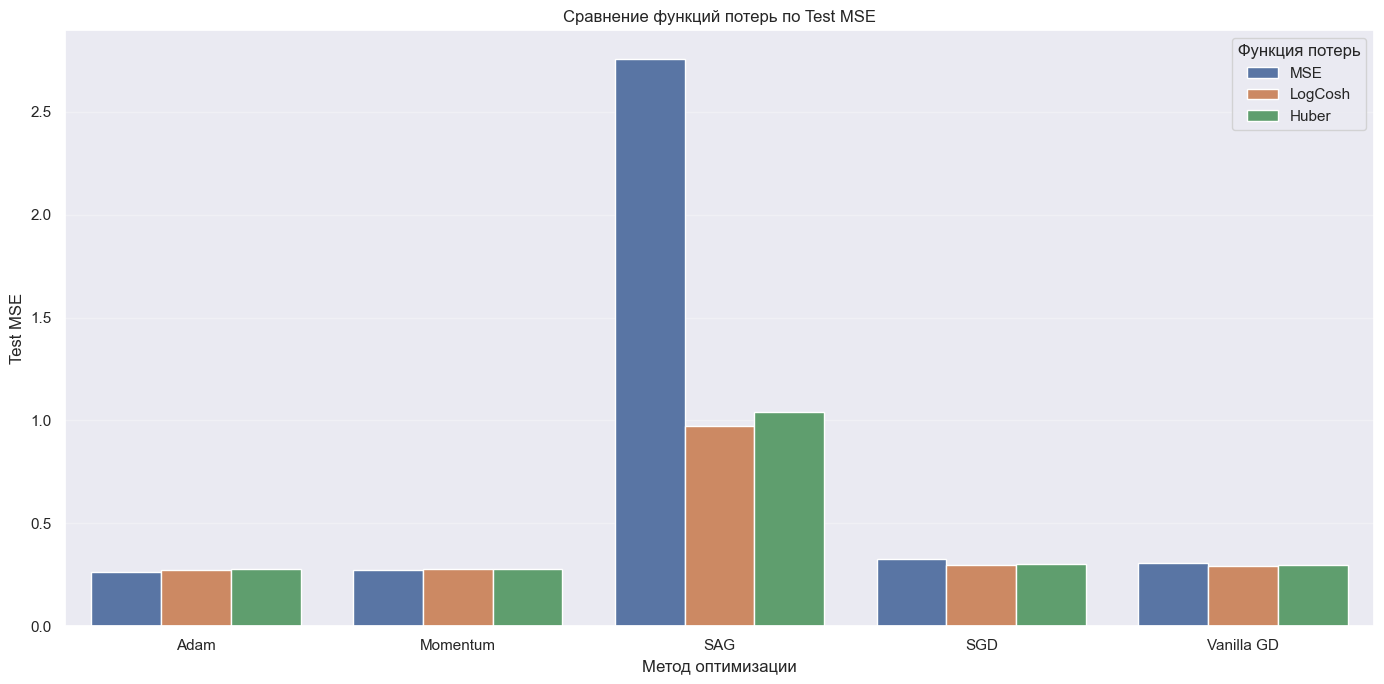

In [132]:
plt.figure(figsize=(14, 7))
sns.barplot( data=loss_comparison, x='Метод', y='Test MSE', hue='Функция потерь' )
plt.title( 'Сравнение функций потерь по Test MSE' )

plt.xlabel('Метод оптимизации')
plt.ylabel('Test MSE')
plt.grid( axis='y', alpha=0.3 )

plt.tight_layout()
plt.show()

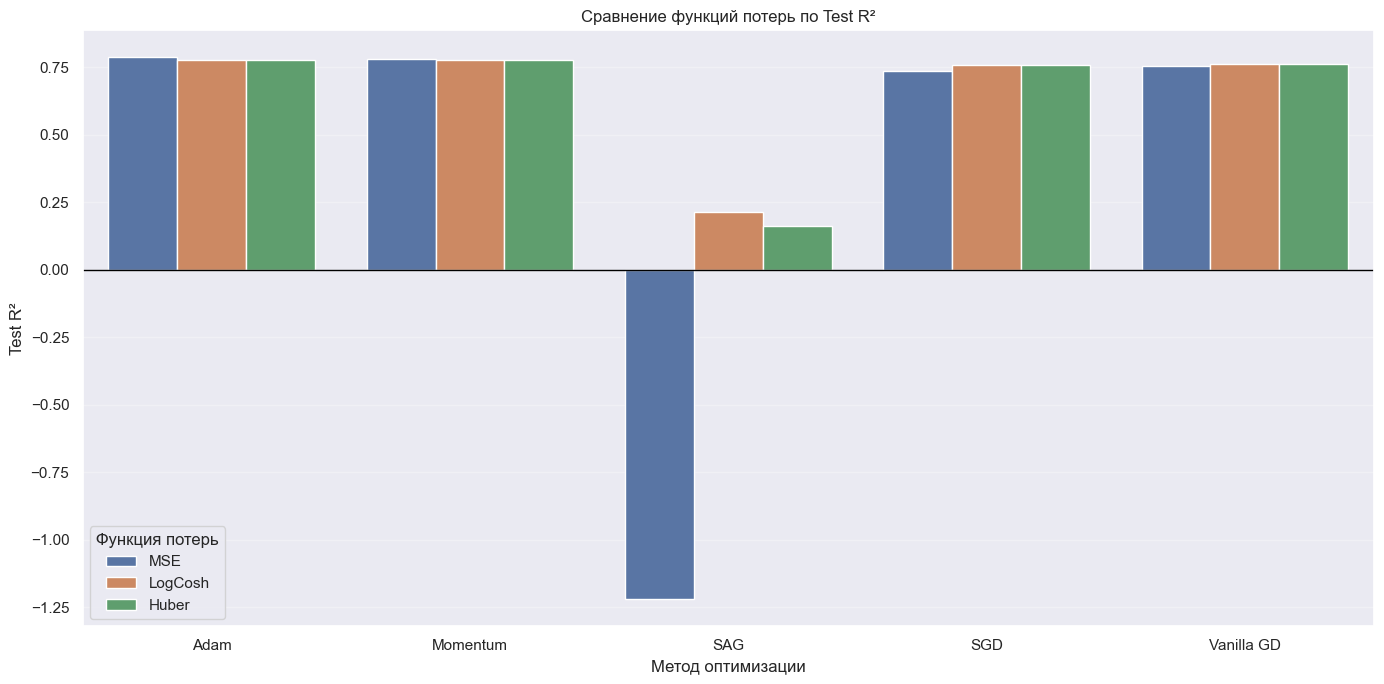

In [133]:
plt.figure(figsize=(14, 7))
sns.barplot( data=loss_comparison, x='Метод', y='Test R2', hue='Функция потерь' )
plt.axhline( 0, color='black', linewidth=1 )
plt.title( 'Сравнение функций потерь по Test R²' )

plt.xlabel('Метод оптимизации')
plt.ylabel('Test R²')
plt.grid( axis='y', alpha=0.3 )

plt.tight_layout()
plt.show()

## Выводы:

1. Vanilla GD. LogCosh и Huber снизили тестовую MSE с 0.305 до 0.294 и 0.295 соответственно.

2. Momentum. Лучшей осталась MSE: тестовая ошибка 0.271 против 0.276 для LogCosh и 0.278 для Huber.

3. SAG. Альтернативные функции потерь дали наибольшее улучшение: тестовая MSE снизилась с 2.758 до 0.975 с LogCosh и 1.043 с Huber. Однако результат всё ещё хуже, чем у остальных методов.

4. SGD. Тестовая MSE снизилась с 0.327 до 0.300 с LogCosh и 0.301 с Huber.

5. Adam. Лучший результат во всём сравнении получен с MSE: тестовая ошибка 0.265. С LogCosh и Huber она составила 0.275 и 0.276.

LogCosh и Huber ограничивают влияние больших ошибок на градиент, что могло помочь некоторым методам. Но для данной выборки и проверенных параметров они не превзошли сочетание Adam и MSE. Порог Huber был фиксирован и равен 1.